# Πρόβλεψη κίνησης κινητού δικτύου: Telecom Italia, Μιλάνο (grid 5060)

#### Δομή του notebook
1. Το τηλεπικοινωνιακό πρόβλημα, το experimental setting, οι μεταβλητές και τα δεδομένα: απομόνωση του τετραγώνου,
   σχηματισμός των χρονοσειρών, διαχωρισμός train/test, διερευνητική ανάλυση.
2. ARIMA, SARIMA, ARIMA-x: θεωρία, εκτίμηση των υπερπαραμέτρων $d, p, q$ (και $D, P, Q$), εκτίμηση και διαγνωστικός
   έλεγχος των μοντέλων, rolling-window πρόβλεψη. Το SARIMA είναι πολύ αργό για τη rolling πρόβλεψη, οπότε στη σύγκριση
   συμμετέχει μόνο το ARIMA-x.
3. Deep learning (LSTM): θεωρία, κανονικοποίηση, από-περιοδικοποίηση, εκπαίδευση.
4. Foundation model (TimesFM 3.0): θεωρία, zero-shot και fine-tuning.
5. Αποτίμηση όλων των μοντέλων: RMSE, MAE, MAPE, MASE, απεικονίσεις, κριτήρια επιτυχίας, διαστήματα πρόβλεψης 95%.
6. Τηλεπικοινωνιακή σημασία, ενορχήστρωση σε δίκτυο 6G πραγματικού χρόνου, χρόνοι inference.

## 1. Το τηλεπικοινωνιακό πρόβλημα, το experimental setting και τα δεδομένα

Πρώτα εξηγούμε το πρόβλημα και από πού προέρχονται τα δεδομένα, και μετά φτιάχνουμε τις χρονοσειρές και εξετάζουμε τι
δείχνουν.

### 1.1 Το τηλεπικοινωνιακό πρόβλημα και η σημασία του στα δίκτυα 5G/6G

Η πρόβλεψη φορτίου κίνησης (traffic load forecasting) εκτιμά τον μελλοντικό όγκο δραστηριότητας (δεδομένα, κλήσεις,
μηνύματα) σε μια κυψέλη ή γεωγραφική περιοχή, με βάση το ιστορικό της. Στα δίκτυα 5G και 6G η ιδέα είναι η διαχείριση
πόρων να γίνεται προληπτικά και όχι αντιδραστικά. Αυτό είναι εφικτό γιατί στα 5G/6G πολλές λειτουργίες
του δικτύου τρέχουν ως λογισμικό και η δέσμευση πόρων μπορεί να αλλάζει δυναμικά. Αν το δίκτυο
ξέρει ότι σε 10 έως 50 λεπτά η ζήτηση σε μια κυψέλη θα αυξηθεί, μπορεί έγκαιρα να:

* δεσμεύσει φάσμα ή να ενεργοποιήσει κυψέλες που ήταν σε κατάσταση ύπνου,
* κλιμακώσει τις εικονικές λειτουργίες δικτύου και τους πόρους του edge,
* μοιράσει τη χωρητικότητα ανάμεσα στα network slices (eMBB, URLLC, mMTC),
* μεταφέρει φορτίο σε γειτονικές κυψέλες.

Αντίστροφα, όταν προβλέπεται χαμηλό φορτίο, μπορεί να απελευθερώσει πόρους και να απενεργοποιήσει εξοπλισμό για
εξοικονόμηση ενέργειας. Το πόσο ασφαλές είναι αυτό εξαρτάται από το πόσο καλή είναι η πρόβλεψη.

Το Zero-touch network and Service Management (ZSM) του ETSI ορίζει μια αρχιτεκτονική πλήρως
αυτοματοποιημένης διαχείρισης δικτύου. Ο βασικός μηχανισμός του είναι ο κλειστός βρόχος: *παρακολούθηση* (monitor)
$\rightarrow$ *ανάλυση* (analyze) $\rightarrow$ *απόφαση* (decide) $\rightarrow$ *εκτέλεση* (execute). Η
πρόβλεψη κίνησης ανήκει στο στάδιο της ανάλυσης: μετατρέπει τις μετρήσεις του παρελθόντος σε εκτίμηση του μέλλοντος, και
πάνω σε αυτή ενεργεί το στάδιο της απόφασης. Χωρίς πρόβλεψη ο βρόχος μπορεί μόνο να αντιδρά.

Για το τετράγωνο 5060 του Μιλάνου έχουμε τρεις χρονοσειρές με ένα σημείο ανά δεκάλεπτο: Internet, SMS
και Calls. Σε κάθε χρονική στιγμή $t$ θέλουμε να προβλέψουμε:

* short-term: την τιμή του επόμενου δεκαλέπτου, $\hat y_{t+1}$ ($h = 1$, 10 λεπτά μπροστά),
* long-term: τις τιμές των πέντε επόμενων δεκαλέπτων, $\hat y_{t+1}, \dots, \hat y_{t+5}$ ($H = 5$, έως 50 λεπτά μπροστά).

### 1.2 Experimental setting: πώς προέκυψαν τα δεδομένα

Τα παρακάτω προέρχονται από το άρθρο που περιγράφει το dataset (Barlacchi et al., *Scientific Data*, 2015). Τα δεδομένα
δημοσιεύτηκαν από την Telecom Italia για το *Big Data Challenge 2014* και καλύπτουν το διάστημα 1 Νοεμβρίου 2013 έως 1
Ιανουαρίου 2014.

Τα δεδομένα προέρχονται από Call Detail Records (CDRs). Στα SMS και τις κλήσεις γράφεται ένα CDR για κάθε SMS ή κλήση που στέλνεται ή λαμβάνεται.
Στο Internet γράφεται όταν ξεκινά ή τελειώνει μια σύνδεση, και κατά τη διάρκειά της αν κρατήσει πάνω από 15 λεπτά ή αν μεταφερθούν πάνω από 5 MB.

Το Μιλάνο χωρίζεται σε πλέγμα $100 \times 100$ τετραγώνων, περίπου $235 \times 235$ m το καθένα. Κάθε αλληλεπίδραση ανήκει στην
περιοχή κάλυψης της κεραίας που την εξυπηρέτησε, και μοιράζεται στα τετράγωνα ανάλογα με την επικάλυψή τους με αυτή.

Οι τιμές είναι κλιμακωμένες με μια σταθερά $k$ της Telecom Italia, της οποίας η τιμή δεν δημοσιεύεται, ώστε να μην
αποκαλύπτεται το πραγματικό πλήθος κλήσεων, SMS και συνδέσεων. Έτσι είναι σχετικοί δείκτες δραστηριότητας χωρίς φυσική
μονάδα, κάτι που επηρεάζει την ερμηνεία των μετρικών σφάλματος, όπως θα δούμε αργότερα.

Τρία όρια των δεδομένων που πρέπει να έχουμε υπόψη:

* Το Internet μετρά πλήθος CDRs και όχι bytes. Με τον κανόνα των 15 λεπτών και των 5 MB ακολουθεί εν μέρει τον όγκο, αλλά δεν
  είναι ο όγκος.
* Καλύπτονται μόνο οι πελάτες της Telecom Italia και όσοι χρησιμοποιούν το δίκτυο της με roaming. Το άρθρο εκτιμά ότι αυτό
  είναι το πολύ το 34% του πληθυσμού.
* Τα δεδομένα είναι του 2013, πριν από το 5G. Η χρήση τους ως εικόνα του
  φορτίου ενός δικτύου 5G/6G είναι δική μας υπόθεση εργασίας, που ακολουθεί την εκφώνηση.

### 1.3 Οι μεταβλητές και το τετράγωνο 5060

Κάθε γραμμή των αρχείων αντιστοιχεί σε ένα τετράγωνο, ένα δεκάλεπτο και έναν κωδικό χώρας:

| Μεταβλητή | Σημασία |
|:---|:---|
| `square_id` | το τετράγωνο του πλέγματος (1 έως 10000) |
| `time_interval` | αρχή του δεκαλέπτου, σε ms |
| `country_code` | κωδικός χώρας |
| `sms_in`, `sms_out` | δραστηριότητα εισερχόμενων και εξερχόμενων SMS |
| `call_in`, `call_out` | δραστηριότητα εισερχόμενων και εξερχόμενων κλήσεων |
| `internet` | δραστηριότητα Internet |

Τι σημαίνει κάθε σειρά για το δίκτυο. Οι τρεις σειρές φορτώνουν διαφορετικούς πόρους:

* Internet: κίνηση δεδομένων στο user plane. Καθορίζει κυρίως τους ραδιοπόρους της κυψέλης (PRBs) και τη χωρητικότητα του UPF
  στο core, και είναι η σειρά που αντιστοιχεί περισσότερο στο φορτίο ενός δικτύου 5G (eMBB).
* SMS: κάθε μήνυμα έχει ελάχιστο όγκο, αλλά μεταφέρεται με σηματοδοσία (στο 5G από τα AMF και SMSF). Φορτώνει λοιπόν
  κυρίως το control plane και όχι τη χωρητικότητα δεδομένων.
* Calls: φωνή με εγγυημένο ρυθμό (GBR) και αυστηρά όρια καθυστέρησης. Οι πόροι της πρέπει να
  δεσμεύονται πριν φτάσει η ζήτηση, οπότε εδώ η πρόβλεψη είναι ιδιαίτερα χρήσιμη.

Γιατί αθροίζουμε. Τα εισερχόμενα και τα εξερχόμενα SMS και κλήσεις εξυπηρετούνται από τους ίδιους σταθμούς βάσης, οπότε για τη
διαστασιολόγηση μετράει το άθροισμά τους και όχι η κατεύθυνση. Για τον ίδιο λόγο αθροίζουμε σε όλους τους κωδικούς χώρας: ένας
χρήστης με roaming φορτώνει την κυψέλη όσο και ένας συνδρομητής της Telecom Italia.

Το τετράγωνο 5060. Σύμφωνα με τα όριά του στο αρχείο του πλέγματος (`milano-grid.geojson`, από το dataset [Milano Grid](https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/QJWLFU) της Telecom Italia στο Harvard Dataverse), βρίσκεται πάνω στην Piazza del Duomo, και η Galleria
Vittorio Emanuele II είναι αμέσως βόρεια του (βλ. χάρτη). Είναι ένα κεντρικό, τουριστικό σημείο της πόλης, οπότε πριν δούμε τα
δεδομένα περιμένουμε έντονη δραστηριότητα, ημερήσια και εβδομαδιαία περιοδικότητα και αισθητή επίδραση των εορτών.


### 1.4 Απομόνωση του τετραγώνου 5060

Το αρχείο `data/grid5060_rows.tsv` περιέχει μόνο τις γραμμές του τετραγώνου 5060 και βρίσκεται ήδη στο repository.
Παράχθηκε με το `python download_dataset.py`, που διαβάζει τα 62 ημερήσια αρχεία (περίπου 21 GB), ελέγχει τα checksums
και κρατά μόνο το grid 5060. Δεν χρειάζεται να ξανατρέξει.


### 1.5 Σχηματισμός των χρονοσειρών και έλεγχος missing values

Στο επόμενο κελί κάνουμε δύο υποθέσεις που δεν αναφέρονται στο άρθρο:

* Τα κενά πεδία γίνονται 0, δηλαδή υποθέτουμε ότι κενό σημαίνει καμία καταγεγραμμένη δραστηριότητα.
* Ο χρόνος μετατρέπεται σε τοπική ώρα (`Europe/Rome`), με την υπόθεση ότι τα ms μετρούν από το Unix epoch σε UTC. Το στηρίζει το
  ότι έτσι η πρώτη και η τελευταία τιμή πέφτουν ακριβώς στις 00:00 της 1/11 και στις 23:50 της 1/1.

Αθροίζουμε πάνω σε όλα τα country codes, γιατί μας ενδιαφέρει η συνολική δραστηριότητα του τετραγώνου, και σχηματίζουμε τις
τρεις σειρές:

$$\text{Internet}_t, \qquad \text{SMS}_t = \text{SMS}^{\text{in}}_t + \text{SMS}^{\text{out}}_t, \qquad \text{Calls}_t = \text{Call}^{\text{in}}_t + \text{Call}^{\text{out}}_t$$

Η εκφώνηση ζητά μια ανάλυση χωρίς missing values. Κανένα δεκάλεπτο της περιόδου δεν λείπει, οπότε κρατάμε την πιο λεπτομερή
ανάλυση, τα 10 λεπτά. Το `asfreq("10min")` δηλώνει ρητά ότι η σειρά έχει ένα σημείο ανά δεκάλεπτο.


In [1]:
import pandas as pd

# Read TSV file
cols = ["square_id", "time_ms", "country_code", "sms_in", "sms_out", "call_in", "call_out", "internet"]
raw = pd.read_csv("data/grid5060_rows.tsv", sep="\t", header=None, names=cols)

# Convert time and replace NaNs
act = ["sms_in", "sms_out", "call_in", "call_out", "internet"]
raw[act] = raw[act].fillna(0.0)                       # empty field = no activity
raw["time"] = pd.to_datetime(raw["time_ms"], unit="ms", utc=True).dt.tz_convert("Europe/Rome").dt.tz_localize(None)

# Produce internet, sms and calls series
g = raw.groupby("time")[act].sum()                     # sum over all country codes
df = pd.DataFrame({"internet": g["internet"],
                   "sms": g["sms_in"] + g["sms_out"],
                   "calls": g["call_in"] + g["call_out"]})

# Missing-value check: every 10-minute interval of the period must have data
full = pd.date_range(df.index[0].normalize(), df.index[-1].normalize() + pd.Timedelta("1D"), freq="10min", inclusive="left")
print(len(full), "ten-minute intervals,", len(full.difference(df.index)), "missing")
df = df.asfreq("10min")
df.head()

8928 ten-minute intervals, 0 missing


,internet,sms,calls
time,,,
2013-11-01 00:00:00,392.178279,17.557269,18.132743
2013-11-01 00:10:00,402.885548,50.770405,15.653305
2013-11-01 00:20:00,350.060713,25.363502,12.460866
2013-11-01 00:30:00,427.730728,10.329996,23.500200
2013-11-01 00:40:00,434.044619,19.226668,12.441366


### 1.6 Διαχωρισμός train / test

Το test set είναι το τελευταίο τέταρτο της σειράς, στρογγυλεμένο σε ολόκληρες ημέρες, ώστε να ξεκινά στις 00:00. Ο διαχωρισμός είναι χρονολογικός, γιατί ένας τυχαίος θα έβαζε μελλοντικές τιμές στο train (*data
leakage*). Η εκφώνηση προτείνει 1/3 ή 1/4: με 1/4 το train έχει 46 ημέρες (6624 σημεία) και το test 16 ημέρες (2304 σημεία).

Το test καλύπτει το διάστημα 17/12/2013 έως 01/01/2014, δηλαδή τα Χριστούγεννα και την Πρωτοχρονιά. Το train (01/11 έως 16/12)
έχει μόνο μεμονωμένες αργίες και καμία αντίστοιχη εορταστική περίοδο, οπότε το test ελέγχει και συνθήκες που τα μοντέλα δεν
έχουν δει.


In [2]:
TEST_FRAC = 0.25
SEASON = 144 # 1 day = 144*10 minutes
SERIES = ["internet", "sms", "calls"]

N = len(df)
n_test = int(round(N * TEST_FRAC / SEASON)) * SEASON       # the test set starts at midnight
n_train = N - n_test
print(f"N = {N}, train = {n_train}, test = {n_test}")
train, test = df.iloc[:n_train], df.iloc[n_train:]
t_split = test.index[0]
print(f"train {train.index[0]} -> {train.index[-1]}")
print(f"test  {test.index[0]} -> {test.index[-1]}")

N = 8928, train = 6624, test = 2304
train 2013-11-01 00:00:00 -> 2013-12-16 23:50:00
test  2013-12-17 00:00:00 -> 2014-01-01 23:50:00


### 1.7 Διερευνητική ανάλυση (EDA)

Οι επιλογές που θα κάνουμε αργότερα για τα μοντέλα πρέπει να στηρίζονται σε αυτό που δείχνουν τα δεδομένα. Η EDA απαντά σε τέσσερα ερωτήματα: υπάρχει
περιοδικότητα και ποια; διαφέρουν οι εργάσιμες από τα Σαββατοκύριακα; υπάρχουν ανωμαλίες (αργίες, αιχμές); πόσο μοιάζουν οι
τρεις σειρές μεταξύ τους;

Το πρώτο κελί ορίζει:
* τις αργίες του διαστήματος: Αγίων Πάντων (1/11), Sant'Ambrogio (7/12, τοπική αργία του Μιλάνου), Άμωμος Σύλληψη (8/12),
  Χριστούγεννα (25/12), Santo Stefano (26/12), Πρωτοχρονιά (1/1),
* τη συνάρτηση `day_type`, που χωρίζει τις ημέρες σε τρεις κατηγορίες: εργάσιμη, Σάββατο, Κυριακή ή αργία. Το να μπαίνουν οι
  αργίες μαζί με τις Κυριακές είναι δική μας επιλογή: υποθέτουμε ότι μοιάζουν, χωρίς να το έχουμε ελέγξει ξεχωριστά.


In [3]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

COLOR = {"internet": "#2a78d6", "sms": "#eb6834", "calls": "#1baf7a"}

# Public holidays in Milan: the national ones plus Sant'Ambrogio (7/12, the city's patron saint).
# National Unity Day is left out: since 1977 it is only marked on the first Sunday of November, so it is an ordinary Sunday.
_hol = holidays.Italy(years=[2013, 2014], subdiv="MI", language="en_US")
HOLIDAYS = pd.to_datetime(sorted(d for d, name in _hol.items() if name != "National Unity Day"))
HOLIDAYS = HOLIDAYS[(HOLIDAYS >= df.index[0].normalize()) & (HOLIDAYS <= df.index[-1])]

def day_type(idx):
    """0 = working day, 1 = Saturday, 2 = Sunday / holiday"""
    dow = idx.dayofweek
    return np.select([(dow == 6) | idx.normalize().isin(HOLIDAYS), dow == 5], [2, 1], 0)

Ολόκληρη η σειρά. Με γκρι σκιάζονται τα Σαββατοκύριακα και οι αργίες, και η διακεκομμένη γραμμή δείχνει την
αρχή του test set. Εδώ ψάχνουμε την τάση (υπάρχει ή όχι), τον εβδομαδιαίο ρυθμό και τυχόν ασυνήθιστες ημέρες.

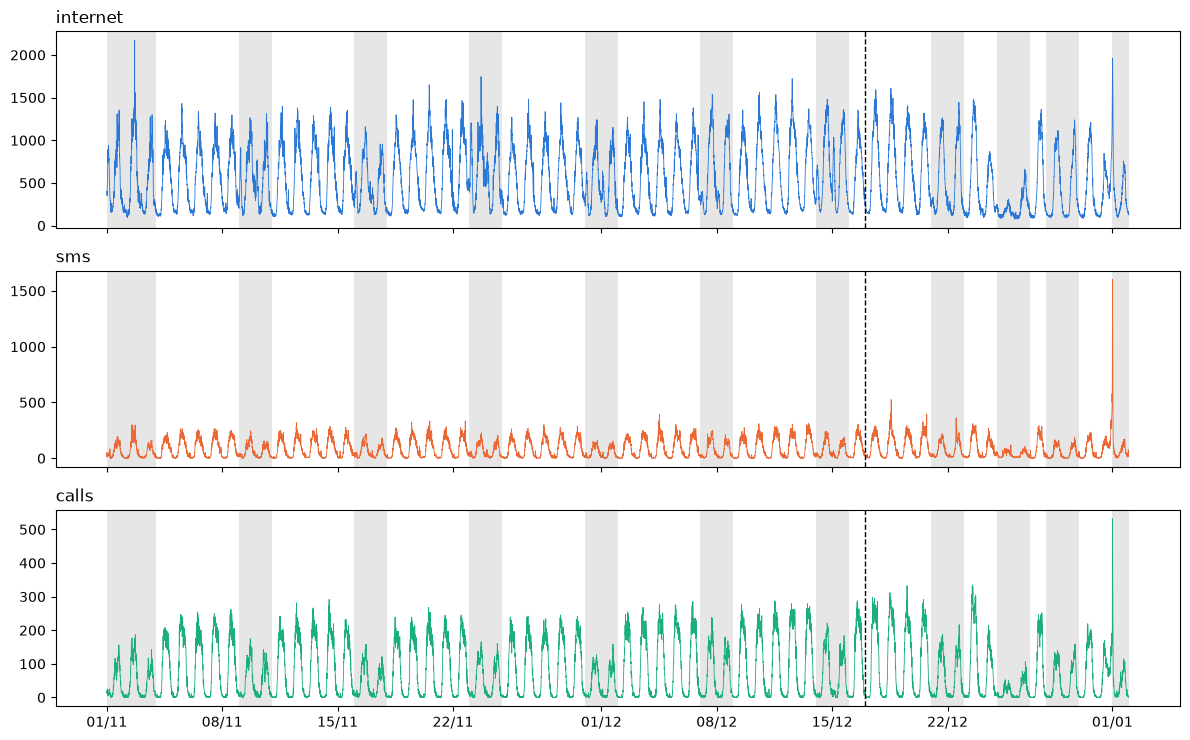

In [4]:
# Full series, weekends/holidays shaded, dashed line = start of test set
days = pd.date_range(df.index[0].normalize(), df.index[-1].normalize(), freq="D")
off_days = days[day_type(days) > 0]
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, s in zip(axes, SERIES):
    ax.plot(df.index, df[s], color=COLOR[s], lw=0.6)
    for d in off_days:
        ax.axvspan(d, d + pd.Timedelta("1D"), color="0.9", lw=0)
    ax.axvline(t_split, color="k", ls="--", lw=1)
    ax.set_title(s, loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout(); plt.show()

Η μέση εβδομάδα, από Δευτέρα έως Κυριακή. Για κάθε δεκάλεπτο της εβδομάδας παίρνουμε τη μέση τιμή στο train, χωρίς
τις αργίες (1/11, 7/12, 8/12), και η σκιά δείχνει μία τυπική απόκλιση γύρω της. Κάθε σημείο είναι μέσος όρος μόλις 6
ή 7 τιμών, οπότε η καμπύλη έχει λίγο θόρυβο.

Οι πέντε εργάσιμες μοιάζουν σχεδόν ίδιες. Το Σαββατοκύριακο αλλάζει η εικόνα: τα SMS και οι κλήσεις πέφτουν, ενώ το
Internet έχει μια δεύτερη ανύψωση τις πρώτες ώρες του Σαββάτου και της Κυριακής, με φαρδιά σκιά, δηλαδή η νυχτερινή
κίνηση αλλάζει πολύ από εβδομάδα σε εβδομάδα.


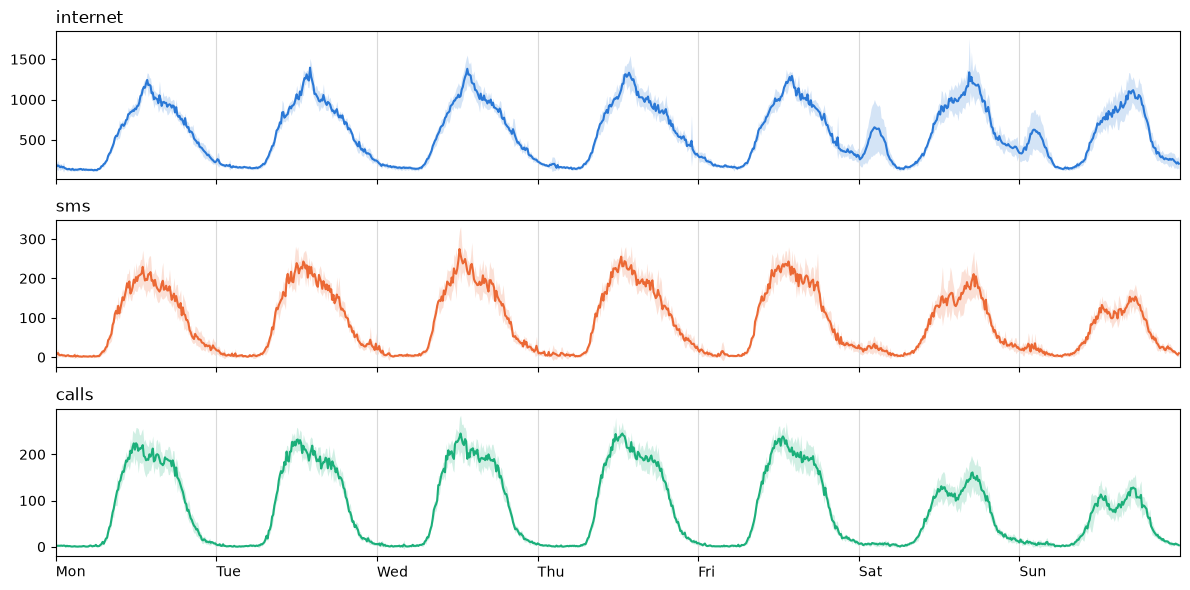

In [5]:
# Mean week (Monday to Sunday) on the train set, holidays left out. Band = one standard deviation
wk = train[~train.index.normalize().isin(HOLIDAYS)]
pos = wk.index.dayofweek + (wk.index.hour + wk.index.minute / 60) / 24   # position in the week, in days: 0 = Monday 00:00
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, s in zip(axes, SERIES):
    g = wk[s].groupby(pos).agg(["mean", "std"])
    ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], color=COLOR[s], alpha=0.2, lw=0)
    ax.plot(g.index, g["mean"], color=COLOR[s])
    ax.set_title(s, loc="left"); ax.grid(axis="x", color="0.85")
axes[-1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], ha="left")
axes[-1].set_xlim(0, 7)
fig.tight_layout(); plt.show()

Μέσο ημερήσιο προφίλ ανά τύπο ημέρας. Για κάθε δεκάλεπτο της ημέρας (slot 0 έως 143) υπολογίζουμε τη μέση τιμή,
χωριστά για εργάσιμες, Σάββατα και Κυριακές ή αργίες. Χρησιμοποιούμε μόνο το train, γιατί αυτά τα προφίλ
καθοδηγούν την επιλογή μοντέλου και δεν πρέπει να «δουν» το test.

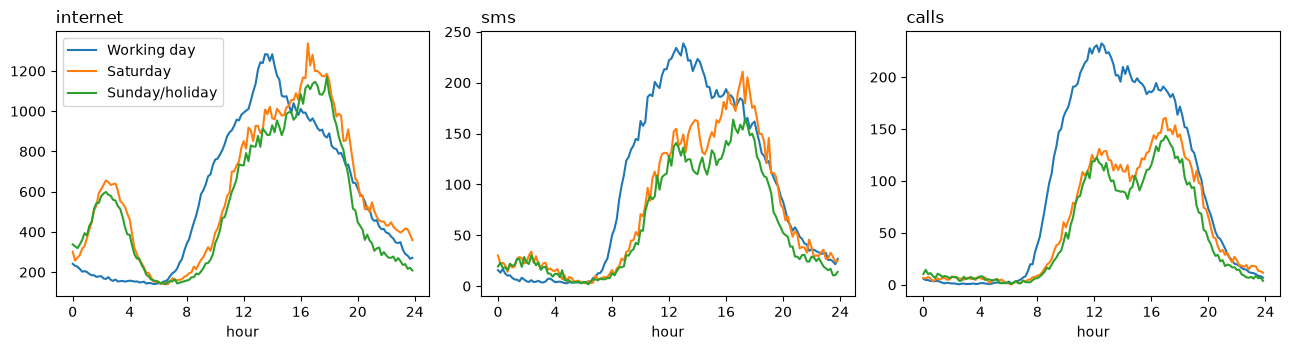

In [6]:
# Mean daily profile per day type (train set only)
key = [day_type(train.index), train.index.hour + train.index.minute / 60]   # day type, time of day in hours (13.5 = 13:30)
names = {0: "Working day", 1: "Saturday", 2: "Sunday/holiday"}
prof = train.groupby(key)[SERIES].mean()                # one mean daily profile per day type
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, s in zip(axes, SERIES):
    for k in range(3):
        ax.plot(prof.loc[k, s], label=names[k])
    ax.set_title(s, loc="left"); ax.set_xlabel("hour"); ax.set_xticks(range(0, 25, 4))
axes[0].legend()
fig.tight_layout(); plt.show()

Ημερήσια σύνολα. Αθροίζοντας ανά ημέρα εξαφανίζεται ο ημερήσιος κύκλος και μένει ο εβδομαδιαίος ρυθμός και οι
ειδικές ημέρες (γκρι: Σαββατοκύριακα και αργίες).

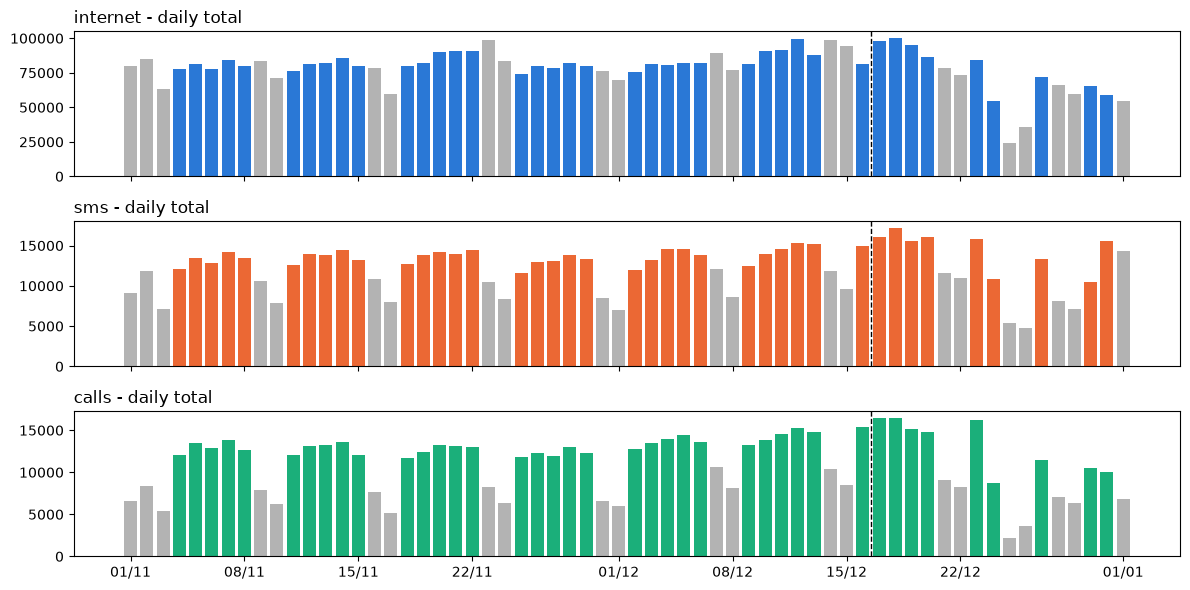

In [7]:
# Daily totals (grey = weekend/holiday)
daily = df.resample("D").sum()
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, s in zip(axes, SERIES):
    ax.bar(daily.index, daily[s], color=np.where(day_type(daily.index) > 0, "0.7", COLOR[s]).tolist(), width=0.8)
    ax.axvline(t_split - pd.Timedelta("12h"), color="k", ls="--", lw=1)
    ax.set_title(s + " - daily total", loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout(); plt.show()

Περιγραφικά στατιστικά και συσχέτιση. Η συσχέτιση Pearson δείχνει κατά πόσο υπάρχει γραμμική σχέση ανάμεσα στις σειρές. Την υπολογίζουμε μόνο στο train, όπως και τα προφίλ.


In [8]:
# Summary statistics, and correlation between the three series on the train set
display(df.describe().T)
display(train.corr().round(3).rename_axis("raw values"))

# The same after removing the daily cycle: subtract from each value the usual value
# for its day type and time of day
usual = train.groupby(key)[SERIES].transform("mean")
deviation = train[SERIES] - usual
display(deviation.corr().round(3).rename_axis("daily cycle removed"))

,count,mean,std,min,25%,50%,75%,max
internet,8928.0,547.156496,376.406598,77.226475,193.706089,438.280193,864.318821,2172.038157
sms,8928.0,84.817577,85.815283,0.003122,11.842894,52.158589,149.550749,1602.041699
calls,8928.0,76.645422,82.094554,0.000000,4.497874,36.834428,146.385241,531.921029


,internet,sms,calls
raw values,,,
internet,1.000,0.907,0.888
sms,0.907,1.000,0.955
calls,0.888,0.955,1.000


,internet,sms,calls
daily cycle removed,,,
internet,1.000,0.341,0.412
sms,0.341,1.000,0.412
calls,0.412,0.412,1.000


peak time,Working day,Saturday,Sunday/holiday
internet,13:30,16:30,17:50
sms,13:00,17:10,17:20
calls,12:30,17:00,17:00


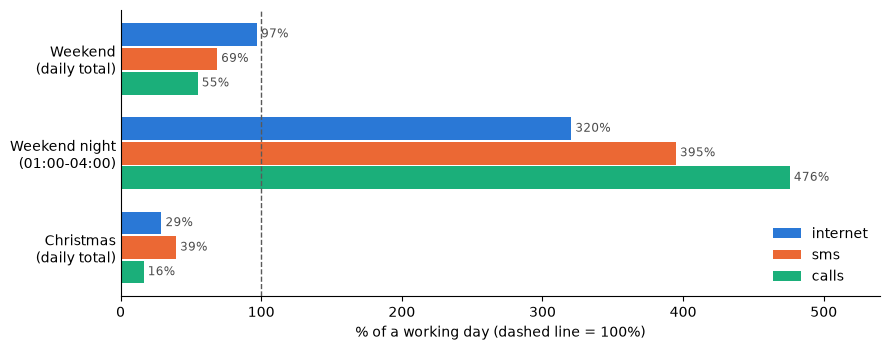

In [9]:
# Numbers used in the findings below (train set; the weekend figures leave the holidays out)
no_hol = train[~train.index.normalize().isin(HOLIDAYS)]
days = no_hol.groupby(no_hol.index.normalize()).sum()                 # daily totals
weekend, workday = days[days.index.dayofweek >= 5].mean(), days[days.index.dayofweek < 5].mean()
night = no_hol[(no_hol.index.hour >= 1) & (no_hol.index.hour < 4)]

# 1) When is the peak of the mean daily profile?
hhmm = lambda h: f"{int(h):02d}:{round(h % 1 * 60):02d}"           # 13.5 -> "13:30"
peaks = pd.DataFrame({names[k]: {s: hhmm(prof.loc[k, s].idxmax()) for s in SERIES} for k in range(3)})
display(peaks.rename_axis(columns="peak time"))

# 2) Weekend and Christmas as % of a working day (100% = a normal working day)
pct = 100 * pd.DataFrame({
    "Weekend\n(daily total)": weekend / workday,
    "Weekend night\n(01:00-04:00)": night[night.index.dayofweek >= 5].mean() / night[night.index.dayofweek < 5].mean(),
    "Christmas\n(daily total)": df.loc["2013-12-25", SERIES].sum() / workday,
})
fig, ax = plt.subplots(figsize=(9, 3.6))
for j, s in enumerate(SERIES):
    y = np.arange(pct.shape[1]) + (j - 1) * 0.26
    bars = ax.barh(y, pct.loc[s], height=0.24, color=COLOR[s], label=s)
    ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8.5, color="0.3")
ax.axvline(100, color="0.35", lw=1, ls="--")
ax.set_yticks(range(pct.shape[1]), pct.columns); ax.invert_yaxis(); ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 540); ax.set_xlabel("% of a working day (dashed line = 100%)")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout(); plt.show()

#### Παρατηρήσεις από την EDA

Οι αριθμοί προέρχονται από τα γραφήματα και τους πίνακες παραπάνω.

* Ημερήσιος κύκλος. Ισχυρός και στις τρεις σειρές: το μοτίβο επαναλαμβάνεται κάθε 144 δεκάλεπτα (μία ημέρα). Τις εργάσιμες η
  κορυφή είναι στις 12:30 έως 13:30. Στο μέσο προφίλ μιας εργάσιμης το Internet πηγαίνει από περίπου 140 τη νύχτα σε περίπου 1300
  το μεσημέρι (περίπου 9 φορές), ενώ τα SMS και τα Calls πέφτουν σχεδόν στο μηδέν. Τα Calls φτάνουν και το 0 (ελάχιστο στον πίνακα
  των στατιστικών).
* Εβδομαδιαίος κύκλος. Το Σαββατοκύριακο τα SMS και τα Calls πέφτουν στο 69% και στο 55% μιας εργάσιμης, ενώ το Internet μένει στο
  97%. Η κορυφή μετατοπίζεται στο απόγευμα (16:30 έως 17:50), και από τις 01:00 έως τις 04:00 το Internet φτάνει το 320% του επιπέδου
  των εργάσιμων.
* Τάση. Δεν φαίνεται. Θα το ελέγξουμε τυπικά αργότερα.
* Συσχέτιση. Υψηλή στο train (0.89 έως 0.96), αλλά οφείλεται κυρίως στον κοινό κύκλο: δύο σειρές που ανεβαίνουν τη μέρα και
  πέφτουν τη νύχτα συσχετίζονται έντονα ούτως ή άλλως. Για την πρόβλεψη μετράνε οι αποκλίσεις από τη συνηθισμένη τιμή κάθε
  ώρας, γιατί τον κύκλο τον ξέρουμε ήδη από το
  ιστορικό κάθε σειράς. Η συσχέτιση των αποκλίσεων είναι μόνο 0.34 έως 0.41, οπότε οι άλλες σειρές
  προσφέρουν περιορισμένη επιπλέον πληροφορία, και γι' αυτό προβλέπουμε κάθε σειρά χωριστά.
* Γιορτές (test). Τα Χριστούγεννα η κίνηση πέφτει στο 16% έως 39% μιας εργάσιμης. Τα μεσάνυχτα της Πρωτοχρονιάς τα SMS
  και τα Calls φτάνουν τη μέγιστη τιμή τους.

Για την πρόβλεψη: ο τύπος ημέρας (εργάσιμη, Σάββατο, Κυριακή ή αργία) αλλάζει πολύ το σχήμα της ημέρας και είναι γνωστός από
πριν, οπότε είναι χρήσιμη πληροφορία. Οι γιορτές του test δεν μοιάζουν με τίποτα στο train, οπότε περιμένουμε μεγαλύτερα σφάλματα εκεί.

Για το δίκτυο: η διαφορά νύχτας και μεσημεριού (περίπου 9 φορές στο Internet) είναι το περιθώριο για εξοικονόμηση ενέργειας τη νύχτα, αλλά η νυχτερινή κίνηση του
Σαββατοκύριακου δείχνει ότι ένα σταθερό πρόγραμμα δεν αρκεί και η απόφαση πρέπει να βασίζεται στην πρόβλεψη. Οι τρεις υπηρεσίες
κορυφώνονται μαζί, και αιχμές όπως της Πρωτοχρονιάς δεν προβλέπονται από το ιστορικό. Θα επανέλθουμε σε αυτό αργότερα.

## 2. ARIMA, SARIMA, ARIMA-x

### 2.1 Θεωρία

#### 2.1.1 Στασιμότητα: γιατί είναι η βασική προϋπόθεση

Ένα μοντέλο ARIMA εκτιμά σταθερές παραμέτρους από το παρελθόν και τις εφαρμόζει στο μέλλον. Αυτό έχει νόημα μόνο
αν η στατιστική συμπεριφορά της σειράς δεν αλλάζει με τον χρόνο. Αυτή η ιδιότητα λέγεται (ασθενής) στασιμότητα.
Μια σειρά $y_t$ είναι στάσιμη όταν:

$$\mathbb{E}[y_t] = \mu \;\;\text{(σταθερός μέσος)}, \qquad \operatorname{Var}(y_t) = \sigma_y^2 \;\;\text{(σταθερή διασπορά)}, \qquad \operatorname{Cov}(y_t,\, y_{t-k}) = \gamma_k \;\;\text{(εξαρτάται μόνο από το } k\text{)}$$

Αν η σειρά έχει τάση ή «περιπλανιέται» χωρίς να επιστρέφει σε ένα μέσο επίπεδο, τότε ο μέσος όρος που θα μάθει το
μοντέλο από το train δεν θα ισχύει στο test.

Τελεστής υστέρησης. Για να γράφουμε τα μοντέλα σύντομα χρησιμοποιούμε τον τελεστή $B$, που μετακινεί τη σειρά ένα
βήμα πίσω:

$$B\,y_t = y_{t-1}, \qquad B^k y_t = y_{t-k}$$

Με αυτόν ορίζονται η διαφόριση (διαφορά από το προηγούμενο βήμα) και η εποχική διαφόριση (διαφορά από το ίδιο
σημείο της προηγούμενης περιόδου $s$):

$$\Delta y_t = (1 - B)\,y_t = y_t - y_{t-1}, \qquad \Delta_s\, y_t = (1 - B^s)\,y_t = y_t - y_{t-s}$$

Η διαφόριση αφαιρεί μια τάση ή μια «περιπλάνηση» και η εποχική διαφόριση αφαιρεί ένα μοτίβο που επαναλαμβάνεται
κάθε $s$ βήματα. Και οι δύο αφαιρούν μια μορφή μη-στασιμότητας.

#### 2.1.2 Τα δομικά στοιχεία: AR, MA, ARMA

Σε όλα τα παρακάτω, $\varepsilon_t$ είναι λευκός θόρυβος: ασυσχέτιστες τυχαίες διαταραχές με μέσο 0 και
διασπορά $\sigma^2$. Είναι το «απρόβλεπτο» μέρος κάθε βήματος.

AR(p), αυτοπαλινδρόμηση. Η τρέχουσα τιμή είναι γραμμικός συνδυασμός των $p$ προηγούμενων τιμών:

$$y_t = c + \phi_1 y_{t-1} + \phi_2 y_{t-2} + \dots + \phi_p y_{t-p} + \varepsilon_t
\qquad\Longleftrightarrow\qquad
\phi(B)\,y_t = c + \varepsilon_t, \quad \phi(B) = 1 - \phi_1 B - \dots - \phi_p B^p$$

*Διαίσθηση:* η σειρά «θυμάται» πού βρισκόταν. Αν η κίνηση είναι υψηλή τώρα, θα είναι μάλλον υψηλή και σε 10 λεπτά.

MA(q), κινητός μέσος. Η τρέχουσα τιμή εξαρτάται από τις $q$ προηγούμενες διαταραχές (τα «ξαφνιάσματα»):

$$y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}
\qquad\Longleftrightarrow\qquad
y_t = \mu + \theta(B)\,\varepsilon_t, \quad \theta(B) = 1 + \theta_1 B + \dots + \theta_q B^q$$

*Διαίσθηση:* ένα απρόσμενο γεγονός (π.χ. ένα πλήθος που φτάνει ξαφνικά) επηρεάζει τα επόμενα $q$ βήματα και μετά
ξεχνιέται εντελώς.

ARMA(p, q). Συνδυάζει και τα δύο: $\;\phi(B)\,y_t = c + \theta(B)\,\varepsilon_t$.

Γιατί ARMA και όχι μόνο AR. Ένα ARMA χαμηλής τάξης μπορεί να περιγράψει μια μνήμη που θα χρειαζόταν πολύ μεγάλο
AR. Λιγότερες παράμετροι σημαίνουν πιο σταθερή εκτίμηση και μικρότερο κίνδυνο υπερπροσαρμογής.

Δύο τεχνικές συνθήκες. Το AR μέρος πρέπει να είναι στάσιμο (οι ρίζες του $\phi(z) = 0$ έξω από τον μοναδιαίο
κύκλο) ώστε οι διαταραχές να σβήνουν με τον χρόνο, και το MA μέρος πρέπει να είναι αντιστρέψιμο (οι ρίζες του
$\theta(z) = 0$ έξω από τον μοναδιαίο κύκλο) ώστε τα $\varepsilon_t$ να μπορούν να ανακτηθούν από τις παρατηρήσεις.

#### 2.1.3 ARIMA(p, d, q)

Αν η $y_t$ δεν είναι στάσιμη, τη διαφορίζουμε $d$ φορές και εφαρμόζουμε ARMA στο αποτέλεσμα. Το «I» (*Integrated*)
δηλώνει ακριβώς αυτό:

$$\phi(B)\,(1 - B)^d\, y_t = c + \theta(B)\,\varepsilon_t$$

Το $d$ είναι το πλήθος των διαφορίσεων, το $p$ η τάξη του AR μέρους και το $q$ η τάξη του MA μέρους. Τις εκτιμούμε
a priori από τα δεδομένα, με στατιστικά τεστ και γραφήματα που ορίζουμε στη συνέχεια.

#### 2.1.4 Seasonal ARIMA: SARIMA(p, d, q)(P, D, Q)$_s$

Η EDA έδειξε ότι η σειρά επαναλαμβάνεται κάθε $s = 144$ βήματα (μία ημέρα). Ένα απλό ARIMA θα χρειαζόταν όρους μέχρι
το lag 144 για να το περιγράψει. Το SARIMA (seasonal ARIMA, s-ARIMA στην εκφώνηση) προσθέτει εποχικά πολυώνυμα στο $B^s$:

$$\phi(B)\,\Phi(B^s)\,(1 - B)^d\,(1 - B^s)^D\, y_t \;=\; \theta(B)\,\Theta(B^s)\,\varepsilon_t$$

Δεν βάζουμε σταθερά: μετά την εποχική διαφόριση, μια σταθερά θα σήμαινε ότι η κίνηση αυξάνεται κατά το ίδιο ποσό κάθε μέρα.

* $\Phi(B^s) = 1 - \Phi_1 B^s - \dots - \Phi_P B^{Ps}$ και $\Theta(B^s) = 1 + \Theta_1 B^s + \dots + \Theta_Q B^{Qs}$
  συνδέουν την τιμή με τις τιμές και τις διαταραχές της ίδιας ώρας τις προηγούμενες ημέρες.
* $D$ είναι το πλήθος των εποχικών διαφορίσεων. Για παράδειγμα, με $s = 144$ και $D = 1$ μοντελοποιούμε τη διαφορά
  $\Delta_{144}\, y_t = y_t - y_{t-144}$, δηλαδή «πόσο διαφέρει η κίνηση από χθες την ίδια ώρα». Αυτό αφαιρεί το
  ημερήσιο μοτίβο.
* Το μοντέλο είναι πολλαπλασιαστικό: τα γινόμενα όπως $\theta(B)\,\Theta(B^s)$ δημιουργούν όρους αλληλεπίδρασης
  (π.χ. στο lag $s + 1$) με λίγες μόνο παραμέτρους.

#### 2.1.5 ARIMA-x: ARIMA με εξωγενείς μεταβλητές

Εδώ η σειρά γράφεται ως παλινδρόμηση σε γνωστές μεταβλητές $x_t$, με σφάλματα που ακολουθούν ARIMA:

$$y_t = c + \beta^\top x_t + u_t, \qquad u_t \sim \text{ARIMA}(p, d, q)$$

Το $\beta^\top x_t$ περιγράφει το προβλέψιμο, ντετερμινιστικό μέρος (π.χ. το ημερήσιο σχήμα) και το ARIMA περιγράφει
ό,τι μένει. Ως $x_t$ χρησιμοποιούμε δείκτες περιοδικότητας, που έχουν ένα κρίσιμο πλεονέκτημα: είναι γνωστοί
εκ των προτέρων για κάθε μελλοντική στιγμή (ξέρουμε τι ώρα και τι μέρα θα είναι), άρα δεν χρειάζεται να τους
προβλέψουμε.

Όροι Fourier. Κάθε περιοδική συνάρτηση με περίοδο $m$ προσεγγίζεται από ένα άθροισμα ημιτόνων και συνημιτόνων:

$$\sum_{k=1}^{K} \Big[\, a_k \sin\!\Big(\frac{2\pi k\, \tau_t}{m}\Big) + b_k \cos\!\Big(\frac{2\pi k\, \tau_t}{m}\Big) \Big]$$

όπου $\tau_t$ η θέση του $t$ μέσα στην περίοδο, π.χ. $m = 144$ για τον ημερήσιο κύκλο και $m = 1008$ ($7 \times 144$)
για τον εβδομαδιαίο. Το $K$ ελέγχει πόσο λεπτομερές είναι το σχήμα: μικρό $K$ δίνει ομαλή καμπύλη, μεγάλο $K$ πιάνει πιο
απότομες αλλαγές, με κόστος $2K$ παραμέτρους.

Γιατί Fourier και όχι μόνο SARIMA. Ένα SARIMA με $s = 1008$ για τον εβδομαδιαίο κύκλο θα ήταν πρακτικά αδύνατο
να εκτιμηθεί (πολυώνυμα βαθμού πάνω από 1000). Οι όροι Fourier περιγράφουν την ίδια περιοδικότητα με λίγες
παραμέτρους ($2K$ ανά περίοδο). Επιπλέον, με έναν δείκτη μη εργάσιμης ημέρας (π.χ. 1 για Κυριακή ή αργία, 0 για εργάσιμη) μπορούμε να πούμε στο μοντέλο ότι η
Κυριακή έχει διαφορετικό σχήμα από τη Δευτέρα, κάτι που το SARIMA δεν μπορεί να κάνει.

### 2.2 Έλεγχοι στασιμότητας (ADF, KPSS): εκτίμηση του $d$

#### Μοναδιαία ρίζα

Η πιο συνηθισμένη μορφή μη στασιμότητας φαίνεται στο απλό μοντέλο

$$y_t = \rho\, y_{t-1} + \varepsilon_t$$

* Αν $|\rho| < 1$, κάθε διαταραχή σβήνει σταδιακά και η σειρά επιστρέφει στον μέσο της: στάσιμη.
* Αν $\rho = 1$, κάθε διαταραχή μένει για πάντα και η σειρά περιπλανιέται (*random walk*): μη στάσιμη. Αυτό
  λέγεται μοναδιαία ρίζα και διορθώνεται με μία διαφόριση, αφού τότε $\Delta y_t = \varepsilon_t$.

Άρα το ερώτημα «χρειάζεται διαφόριση;» είναι ισοδύναμο με το «έχει η σειρά μοναδιαία ρίζα;».

#### ADF (Augmented Dickey-Fuller)

Εκτιμά την παλινδρόμηση

$$\Delta y_t = \alpha + \gamma\, y_{t-1} + \sum_{i=1}^{\ell} \delta_i\, \Delta y_{t-i} + \varepsilon_t$$

όπου $\gamma = \rho - 1$. Οι όροι $\Delta y_{t-i}$ (το «augmented») απορροφούν τη βραχυπρόθεσμη αυτοσυσχέτιση, ώστε το
τεστ να είναι έγκυρο και όταν η σειρά δεν είναι απλό AR(1). Το πλήθος τους $\ell$ επιλέγεται με AIC.

* H0: $\gamma = 0$, δηλαδή υπάρχει μοναδιαία ρίζα (μη στάσιμη).
* $p < 0.05$: απορρίπτουμε την H0, άρα η σειρά δεν έχει μοναδιαία ρίζα.

#### KPSS (Kwiatkowski-Phillips-Schmidt-Shin)

Γράφει τη σειρά ως άθροισμα ενός random walk και ενός στάσιμου μέρους:

$$y_t = r_t + \eta_t, \qquad r_t = r_{t-1} + v_t, \quad \operatorname{Var}(v_t) = \sigma_v^2$$

* H0: $\sigma_v^2 = 0$, δηλαδή το random walk είναι σταθερό και η σειρά είναι στάσιμη.
* $p < 0.05$: απορρίπτουμε την H0, άρα η σειρά είναι μη στάσιμη.

#### Γιατί χρειαζόμαστε και τα δύο

Ένα τεστ υποθέσεων μπορεί μόνο να απορρίψει την H0, ποτέ να την αποδείξει. Το ADF μάλιστα έχει μικρή ισχύ: συχνά
δεν απορρίπτει ακόμη και όταν η σειρά είναι στάσιμη. Τα δύο τεστ έχουν αντίθετες μηδενικές υποθέσεις, οπότε όταν
συμφωνούν το συμπέρασμα είναι αξιόπιστο:

| ADF $p$ | KPSS $p$ | Συμπέρασμα |
|:---:|:---:|:---|
| $< 0.05$ | $> 0.05$ | στάσιμη (συμφωνούν) |
| $> 0.05$ | $< 0.05$ | μη στάσιμη (συμφωνούν), χρειάζεται διαφόριση |
| $< 0.05$ | $< 0.05$ | αντικρουόμενα (συχνά στάσιμη γύρω από τάση) |
| $> 0.05$ | $> 0.05$ | ανεπαρκή στοιχεία |

#### Τι ελέγχουμε

Εφαρμόζουμε τα τεστ στην $y_t$, στην $\Delta y_t$, στην $\Delta_{144}\, y_t$ και στην $\Delta \Delta_{144}\, y_t$. Η
απλούστερη μορφή που βγαίνει στάσιμη δίνει το $d$. Τα τεστ γίνονται μόνο στο train set, ώστε η
επιλογή του μοντέλου να μη «βλέπει» το test.

*Τεχνική σημείωση:* το `statsmodels` δίνει p-values για το KPSS μόνο στο διάστημα $[0.01,\, 0.1]$ (από πίνακα κρίσιμων
τιμών). Μια τιμή 0.1 σημαίνει «0.1 ή μεγαλύτερη».

In [10]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

Y = {s: df[s].values.astype(float) for s in SERIES}

def stationarity_table(y):
    ys = pd.Series(y)
    rows = []
    for name, z in {"y": ys, "d1(y)": ys.diff(), "d144(y)": ys.diff(SEASON),
                    "d1(d144(y))": ys.diff(SEASON).diff()}.items():
        z = z.dropna().values
        with warnings.catch_warnings(action="ignore"):   # FutureWarnings + KPSS p-value outside the lookup table
            adf_stat, adf_p, *_ = adfuller(z, autolag="AIC")
            kpss_stat, kpss_p, *_ = kpss(z, regression="c", nlags="auto")
        rows.append({"series": name, "ADF stat": adf_stat, "ADF p": adf_p,
                     "KPSS stat": kpss_stat,
                     # statsmodels caps the KPSS p-value to [0.01, 0.1]: show the cap as a bound
                     "KPSS p": ">= 0.1" if kpss_p >= 0.1 else ("<= 0.01" if kpss_p <= 0.01 else f"{kpss_p:.3f}"),
                     "conclusion": "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else
                                   ("ambiguous" if (adf_p < 0.05) == (kpss_p < 0.05) else "non-stationary")})
    return pd.DataFrame(rows)


for s in SERIES:
    print(f"\n=== {s} ===  (KPSS p-values are bounded to [0.01, 0.1])")
    display(stationarity_table(Y[s][:n_train]))


=== internet ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.988509,8.904673e-30,0.111048,>= 0.1,stationary
1,d1(y),-13.407905,4.432758e-25,0.003744,>= 0.1,stationary
2,d144(y),-12.733859,9.250838e-24,0.017651,>= 0.1,stationary
3,d1(d144(y)),-16.435145,2.457400e-29,0.003739,>= 0.1,stationary



=== sms ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.220950,3.898405e-29,0.053198,>= 0.1,stationary
1,d1(y),-14.287563,1.292081e-26,0.007418,>= 0.1,stationary
2,d144(y),-9.587682,2.076050e-16,0.029130,>= 0.1,stationary
3,d1(d144(y)),-27.418437,0.000000e+00,0.041643,>= 0.1,stationary



=== calls ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.927188,9.838981e-30,0.139151,>= 0.1,stationary
1,d1(y),-11.247188,1.747800e-20,0.004341,>= 0.1,stationary
2,d144(y),-9.877710,3.842883e-17,0.036924,>= 0.1,stationary
3,d1(d144(y)),-16.912415,1.008316e-29,0.008494,>= 0.1,stationary


#### Ερμηνεία των τεστ στασιμότητας

Και στις τρεις σειρές τα δύο τεστ συμφωνούν. Το ADF απορρίπτει τη μοναδιαία ρίζα (p-value πρακτικά μηδέν), και το KPSS
δεν απορρίπτει τη στασιμότητα (p-value 0.1 ή μεγαλύτερη, πάνω από το όριο του 0.05). Η σειρά δεν έχει λοιπόν
μοναδιαία ρίζα, δηλαδή ούτε τάση ούτε περιπλάνηση, και δεν χρειάζεται απλή διαφόριση: $d = 0$.

Οι p-values του ADF είναι τόσο μικρές και επειδή το train έχει χιλιάδες σημεία: με τόσα δεδομένα το τεστ απορρίπτει την H0
πολύ εύκολα. Η p-value δεν δείχνει λοιπόν «πόσο στάσιμη» είναι η σειρά. Μετράει μόνο αν είναι κάτω από το 0.05.

Οι διαφορισμένες μορφές βγαίνουν επίσης στάσιμες, αλλά αυτό δεν σημαίνει ότι η διαφόριση χρειάζεται: μια ήδη
στάσιμη σειρά μένει στάσιμη αν τη διαφορίσουμε, με περιττή πολυπλοκότητα (υπερ-διαφόριση, που δημιουργεί ένα μη
αντιστρέψιμο MA). Κρατάμε τη μικρότερη διαφόριση που αρκεί.

Τα ADF και KPSS ελέγχουν μοναδιαία ρίζα στη «μηδενική συχνότητα», δηλαδή μια μακροπρόθεσμη τάση ή περιπλάνηση, και
είναι τυφλά στην εποχικότητα: μια σειρά που ανεβαίνει και κατεβαίνει κανονικά κάθε μέρα βγαίνει στάσιμη για αυτά.
Άρα «στάσιμη» εδώ σημαίνει μόνο «χωρίς μοναδιαία ρίζα». Ο μέσος της σειράς αλλάζει με την ώρα της ημέρας, οπότε
με τον αυστηρό ορισμό της 2.1.1 η $y_t$ δεν είναι στάσιμη.
Το αν χρειάζεται εποχική διαφόριση ($D$) θα το κρίνουμε παρακάτω, από την ACF.

### 2.3 Γραφήματα ACF / PACF: εκτίμηση των $D$, $P, Q$ και $p, q$

#### Ορισμοί

ACF (συνάρτηση αυτοσυσχέτισης). Η συσχέτιση της σειράς με τον εαυτό της μετατοπισμένη κατά $k$ βήματα:

$$r_k \;=\; \frac{\displaystyle\sum_{t=k+1}^{n} (y_t - \bar y)(y_{t-k} - \bar y)}{\displaystyle\sum_{t=1}^{n} (y_t - \bar y)^2}$$

Για παράδειγμα, το $r_{144}$ απαντά στο «πόσο μοιάζει η κίνηση τώρα με την κίνηση χθες την ίδια ώρα;».

PACF (μερική αυτοσυσχέτιση). Η συσχέτιση της $y_t$ με την $y_{t-k}$ αφού αφαιρεθεί η επίδραση των ενδιάμεσων
lags $1, \dots, k-1$. Τυπικά, είναι ο τελευταίος συντελεστής $\phi_{kk}$ όταν εκτιμάμε ένα AR($k$):

$$y_t = \phi_{k1}\, y_{t-1} + \dots + \phi_{kk}\, y_{t-k} + e_t$$

*Γιατί χρειάζεται:* αν το $y_{t-1}$ επηρεάζει το $y_t$ και το $y_{t-2}$ επηρεάζει το $y_{t-1}$, τότε το $y_{t-2}$ θα
φαίνεται συσχετισμένο με το $y_t$ ακόμη κι αν δεν έχει άμεση επίδραση. Η ACF μετράει και αυτή την έμμεση σύνδεση, η
PACF κρατά μόνο την άμεση.

Ζώνη εμπιστοσύνης. Η σκιασμένη ζώνη στα γραφήματα δείχνει πόσο μεγάλη μπορεί να βγει μια αυτοσυσχέτιση μόνο από τύχη, αν
η πραγματική είναι μηδέν. Τιμές μέσα στη ζώνη δεν διακρίνονται από το μηδέν, ενώ τιμές έξω από αυτήν δείχνουν πραγματική
εξάρτηση. Στην PACF η ζώνη έχει σταθερό πλάτος. Στην ACF φαρδαίνει με το lag, γιατί οι μεγάλες αυτοσυσχετίσεις των πρώτων
lags αυξάνουν την αβεβαιότητα των επόμενων.

#### Κανόνες ανάγνωσης (Box-Jenkins)

| Τι βλέπουμε | Τι σημαίνει |
|:---|:---|
| ACF φθίνει πολύ αργά, σχεδόν γραμμικά | μη στασιμότητα, χρειάζεται διαφόριση |
| ACF με κορυφές στα $s, 2s, 3s, \dots$ που φθίνουν αργά | ισχυρή εποχικότητα, χρειάζεται $D = 1$ |
| PACF μηδενίζεται απότομα μετά το lag $p$, ACF φθίνει σταδιακά | AR($p$) |
| ACF μηδενίζεται απότομα μετά το lag $q$, PACF φθίνει σταδιακά | MA($q$) |
| και οι δύο φθίνουν σταδιακά | μικτό ARMA, μικρά $p, q$ και επιβεβαίωση με BIC |
| αρνητική ακίδα στο lag $s$ της ACF (μετά από $\Delta_s$) και τίποτα στα $2s, 3s, \dots$ | εποχικό MA(1), δηλαδή $Q = 1$ |
| ACF στα $s, 2s, 3s, \dots$ που φθίνει σταδιακά, PACF με ακίδα μόνο στο $s$ (μετά από $\Delta_s$) | εποχικό AR(1), δηλαδή $P = 1$ |
| ACF στο lag 1 κοντά στο $-0.5$ μετά από διαφόριση | υπερ-διαφόριση |

#### Τι δείχνει κάθε γράφημα, και γιατί

Για κάθε σειρά σχεδιάζουμε τέσσερα πάνελ (μόνο στο train):
1. ACF της $y$ ως 3 ημέρες: υπάρχει εποχικότητα; (κορυφές στα lags 144, 288, 432, δηλαδή 1, 2, 3 ημέρες πριν)
2. ACF της $\Delta_{144}\, y$ ως μία εβδομάδα: έφυγε η εποχικότητα μετά την εποχική διαφόριση; τι γίνεται την ίδια ώρα
   1, 2, ..., 7 ημέρες πριν;
3. ACF και 4. PACF της $\Delta_{144}\, y$ για lags 0 έως 36: η βραχυπρόθεσμη δομή, από την οποία διαβάζουμε
   τα $p$ και $q$.

Διαβάζουμε τα $p, q$ από την $\Delta_{144}\, y$ και όχι από την $y$, γιατί στην $y$ το ισχυρό ημερήσιο μοτίβο κυριαρχεί
στην ACF και κρύβει τη βραχυπρόθεσμη δομή.

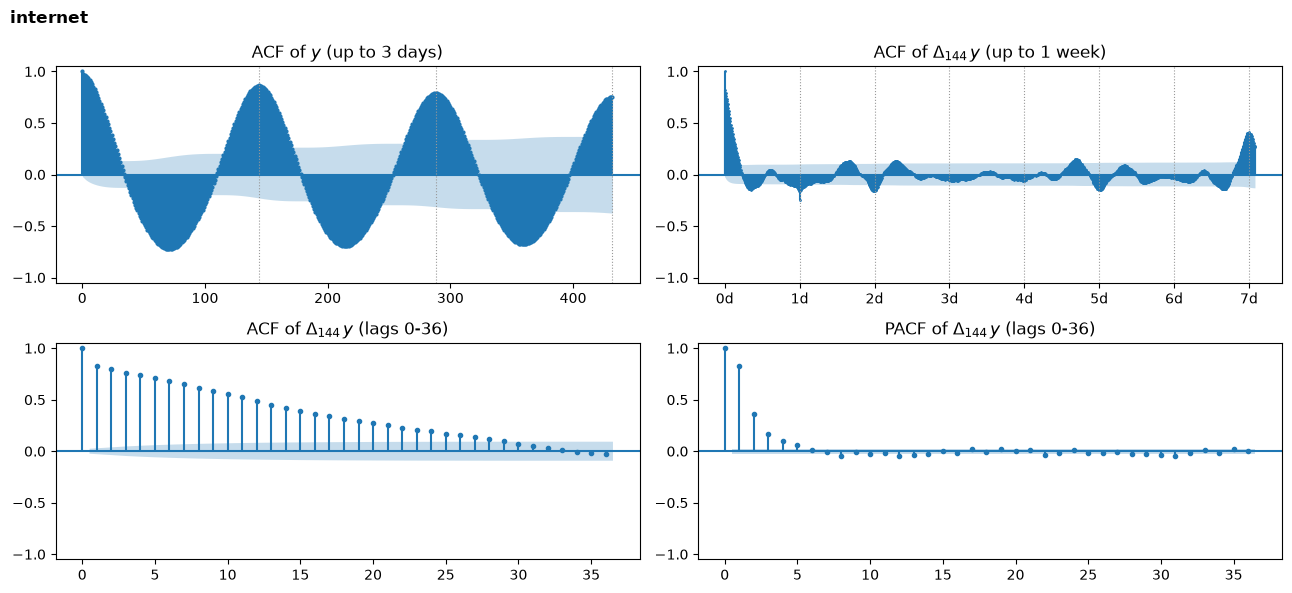

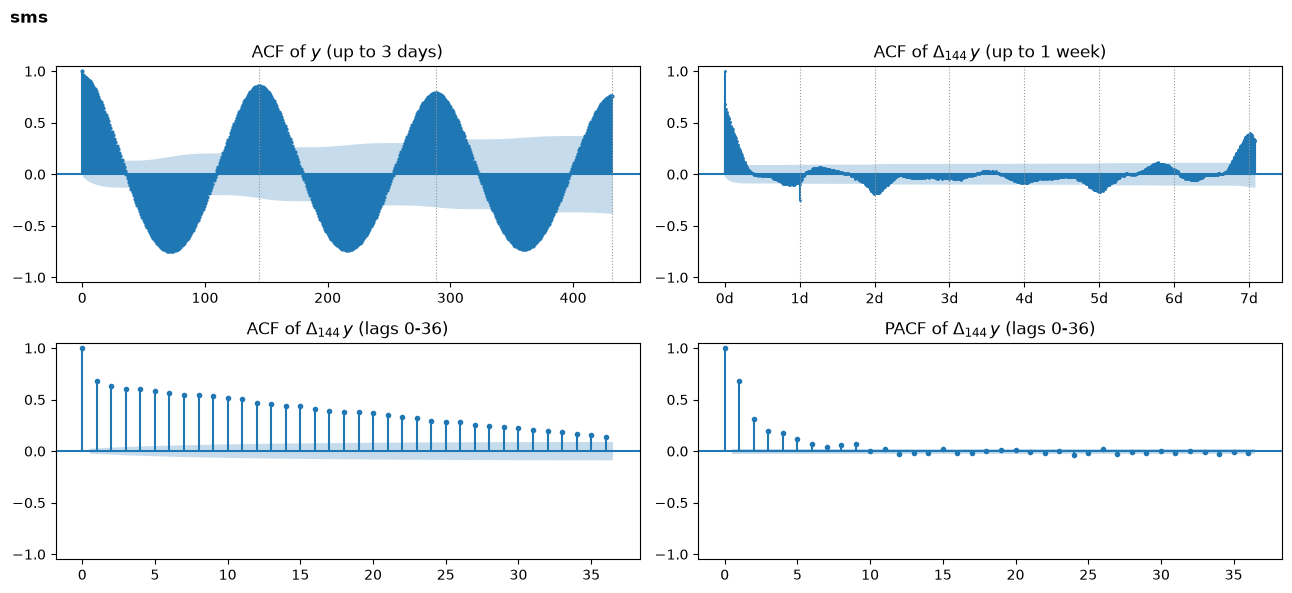

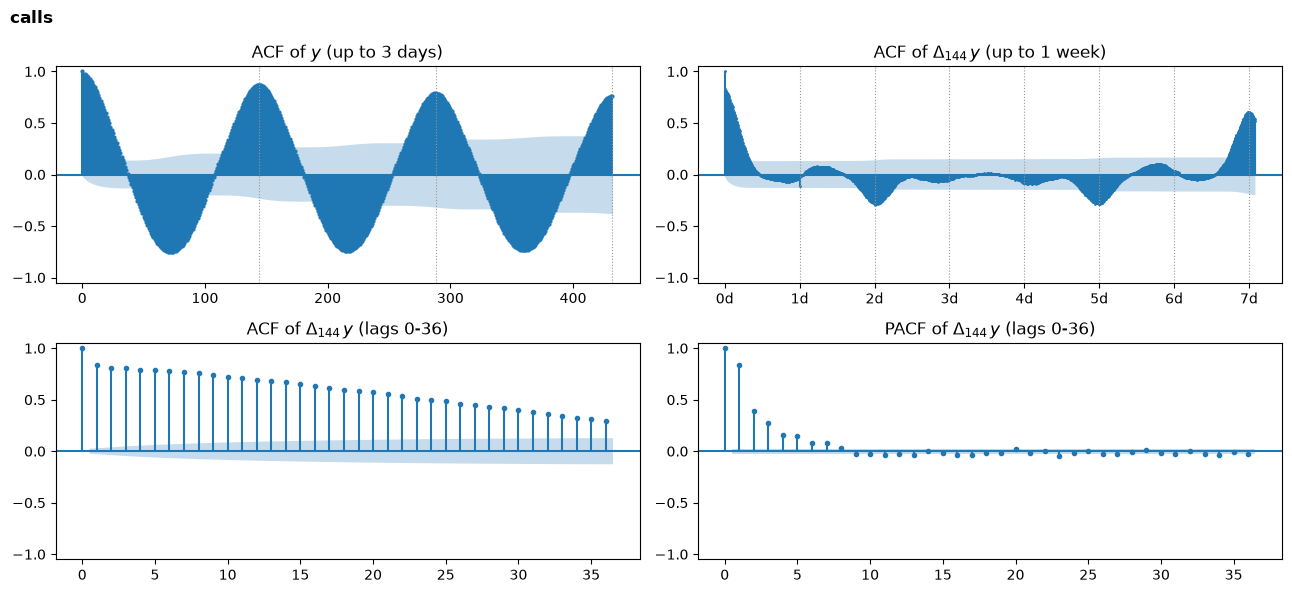

In [11]:
# y: daily seasonality? Delta_144 y: what is left after removing it (p, q, P, Q)
WEEK = 7 * SEASON                                  # 1008 ten-minute steps
for s in SERIES:
    y = pd.Series(Y[s][:n_train])
    ds = y.diff(SEASON).dropna()
    fig, axes = plt.subplots(2, 2, figsize=(13, 6))
    plot_acf(y, lags=3 * SEASON, ax=axes[0, 0], markersize=2, title=r"ACF of $y$ (up to 3 days)")
    plot_acf(ds, lags=WEEK + 12, ax=axes[0, 1], markersize=1, title=r"ACF of $\Delta_{144}\,y$ (up to 1 week)")
    plot_acf(ds, lags=36, ax=axes[1, 0], markersize=3, title=r"ACF of $\Delta_{144}\,y$ (lags 0-36)")
    plot_pacf(ds, lags=36, ax=axes[1, 1], markersize=3, method="ywm", title=r"PACF of $\Delta_{144}\,y$ (lags 0-36)")
    for ax in axes.flat:
        ax.set_ylim(-1.05, 1.05)
    for ax in axes[0]:                             # dotted lines: same time 1, 2, 3, ... days earlier
        for k in range(SEASON, int(ax.get_xlim()[1]), SEASON):
            ax.axvline(k, color="0.6", ls=":", lw=0.8)
    axes[0, 1].set_xticks(range(0, WEEK + 1, SEASON), [f"{d}d" for d in range(8)])
    fig.suptitle(s, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

#### Ερμηνεία των ACF / PACF

Η εικόνα είναι ίδια και στις τρεις σειρές.

Εποχική διαφόριση ($D$). Η ACF της $y$ έχει κορυφές την ίδια ώρα κάθε προηγούμενης ημέρας, που σχεδόν δεν μειώνονται από
ημέρα σε ημέρα. Το ημερήσιο μοτίβο επαναλαμβάνεται σχεδόν ίδιο και ένα ARMA χαμηλής τάξης δεν μπορεί να το περιγράψει. Χρειάζεται
λοιπόν εποχική διαφόριση, $D = 1$ με $s = 144$, ή όροι Fourier όπως στο ARIMA-x. Γι' αυτό δεν εκτιμούμε καθαρό ARIMA: θα έπρεπε να
περιγράψει το ημερήσιο μοτίβο με όρους που φτάνουν μία ολόκληρη ημέρα πίσω.

Απλή διαφόριση ($d$). Η ACF της $\Delta_{144}\, y$ φθίνει ομαλά και σβήνει μέσα σε λίγες ώρες, άρα δεν χρειάζεται επιπλέον απλή
διαφόριση, σε συμφωνία με τα ADF και KPSS.

Εποχικοί όροι ($P, Q$). Στην ACF της $\Delta_{144}\, y$ υπάρχει μια σύντομη αρνητική ακίδα ακριβώς στη μία ημέρα, όπως θα έδινε ένα
εποχικό MA(1). Στις 2, 3 και 4 ημέρες η ACF δεν φθίνει σταδιακά, οπότε δεν υπάρχει ένδειξη για εποχικό AR. Κρατάμε $P = 0$ και
$Q = 1$, που είναι και το εποχικό μέρος του κλασικού «airline» μοντέλου των Box-Jenkins. Άλλες τιμές δεν δοκιμάζουμε, γιατί κάθε
fit του SARIMA είναι πολύ αργό, όπως θα δούμε.

Εβδομαδιαίο μοτίβο. Στις 7 ημέρες η ACF έχει μεγάλη θετική κορυφή, και στις 2 και 5 ημέρες αρνητικές βυθίσεις. Η $\Delta_{144}$
συγκρίνει κάθε ημέρα με την προηγούμενη, οπότε η άνοδος της Δευτέρας (σε σχέση με την Κυριακή) και η πτώση του Σαββάτου (σε σχέση
με την Παρασκευή) επαναλαμβάνονται κάθε εβδομάδα. Οι βυθίσεις στις 2 και 5 ημέρες είναι η ίδια επίδραση: η Δευτέρα και το Σάββατο
απέχουν 2 και 5 ημέρες. Ένα SARIMA με περίοδο μία ημέρα δεν μπορεί να το περιγράψει, και ένα SARIMA με περίοδο μία εβδομάδα δεν
είναι πρακτικά εφικτό. Το μοτίβο αυτό θα μείνει λοιπόν στα σφάλματα του SARIMA, και είναι ο λόγος που το ARIMA-x έχει εβδομαδιαίους
όρους Fourier και δείκτη μη εργάσιμης ημέρας.

Βραχυπρόθεσμη δομή ($p, q$). Η PACF της $\Delta_{144}\, y$ έχει μεγάλες τιμές στα πρώτα 4 έως 6 lags (40 έως 60 λεπτά) και μετά
σχεδόν μηδέν, ενώ η ACF φθίνει σταδιακά. Η εικόνα μοιάζει με AR($p$) με $p \approx 4$ έως $6$ και $q = 0$, αλλά η PACF δεν
μηδενίζεται απότομα, οπότε ένα μικρό ARMA δεν αποκλείεται. Την τελική επιλογή την κάνει το BIC.

#### ARIMA-x: ACF / PACF των καταλοίπων της παλινδρόμησης

Τα παραπάνω γραφήματα αφορούν το SARIMA, που μοντελοποιεί την $\Delta_{144}\, y$. Το ARIMA-x δεν κάνει διαφόριση. Χωρίζει την
$y$ σε δύο μέρη:

$$y_t = \underbrace{\beta^\top x_t}_{\text{παλινδρόμηση: ημερήσιος και εβδομαδιαίος κύκλος}} + \underbrace{u_t}_{\text{ό,τι μένει: ARMA}(p, q)}$$

Τα $p, q$ αφορούν λοιπόν την $u_t$, μια διαφορετική σειρά από την $\Delta_{144}\, y$, και τα διαβάζουμε από τη δική της ACF και PACF.

Οι εξωτερικές μεταβλητές $x_t$ είναι:

* ημερήσιοι όροι Fourier ($K = 4$, περίοδος μία ημέρα), για το σχήμα της ημέρας,
* εβδομαδιαίοι όροι Fourier ($K = 2$, περίοδος μία εβδομάδα), για τις διαφορές ανάμεσα στις ημέρες,
* ο δείκτης `offday`: 1 για Κυριακή ή αργία, 0.5 για Σάββατο, 0 για εργάσιμη,
* τα γινόμενα του `offday` με τους 2 πρώτους ημερήσιους όρους, ώστε τις μη εργάσιμες να αλλάζει το σχήμα της ημέρας
  και όχι μόνο το επίπεδο.

Οι εβδομαδιαίοι όροι και το `offday` υπάρχουν για το εβδομαδιαίο μοτίβο που βρήκαμε στην ACF της $\Delta_{144}\, y$ και που το
SARIMA δεν μπορεί να περιγράψει.

Τα $K$, το πλήθος των γινομένων και το 0.5 για το Σάββατο είναι δικές μας επιλογές, ώστε το μοντέλο να έχει λίγες παραμέτρους, και
δεν τις βελτιστοποιήσαμε. Το 0.5 είναι μια απλή υπόθεση ότι το Σάββατο βρίσκεται ανάμεσα σε εργάσιμη και Κυριακή. Στην EDA είναι
μάλιστα πιο κοντά στην Κυριακή.

Οι αργίες του test (25/12, 26/12, 1/1) μπαίνουν στο `offday` χωρίς να χρησιμοποιούμε πληροφορία από το μέλλον, γιατί το ημερολόγιο
είναι γνωστό από πριν. Τους όρους Fourier τους δίνει το `CalendarFourier` του statsmodels.

In [12]:
from statsmodels.tsa.deterministic import CalendarFourier


def exog_matrix(idx, k_day=4, k_week=2, k_off=2):
    """Periodicity regressors for ARIMA-x, all known in advance for any future time."""
    day = CalendarFourier("D", k_day).in_sample(idx).values     # sin/cos pairs with period one day
    week = CalendarFourier("W", k_week).in_sample(idx).values   # sin/cos pairs with period one week
    off = np.array([0, 0.5, 1])[day_type(idx)]                 # working day = 0, Saturday = 0.5, Sunday/holiday = 1
    cols = {"const": np.ones(len(idx)), "offday": off}
    for k in range(1, k_day + 1):
        sd, cd = day[:, 2 * k - 2], day[:, 2 * k - 1]
        cols[f"d_sin{k}"], cols[f"d_cos{k}"] = sd, cd
        if k <= k_off:                                          # on days off the shape of the day changes too
            cols[f"off_sin{k}"], cols[f"off_cos{k}"] = off * sd, off * cd
    for k in range(1, k_week + 1):
        cols[f"w_sin{k}"], cols[f"w_cos{k}"] = week[:, 2 * k - 2], week[:, 2 * k - 1]
    return pd.DataFrame(cols, index=idx)


EXOG = exog_matrix(df.index)
X_EXOG = EXOG.values
print("ARIMA-x inputs:", list(EXOG.columns))

ARIMA-x inputs: ['const', 'offday', 'd_sin1', 'd_cos1', 'off_sin1', 'off_cos1', 'd_sin2', 'd_cos2', 'off_sin2', 'off_cos2', 'd_sin3', 'd_cos3', 'd_sin4', 'd_cos4', 'w_sin1', 'w_cos1', 'w_sin2', 'w_cos2']


Εκτιμούμε πρώτα μόνο την παλινδρόμηση $y_t = \beta^\top x_t + u_t$ με ελάχιστα τετράγωνα στο train, και κοιτάμε την ACF και
την PACF των καταλοίπων $u_t$.

internet: the periodicity terms explain 90% of the variation
sms: the periodicity terms explain 91% of the variation
calls: the periodicity terms explain 94% of the variation


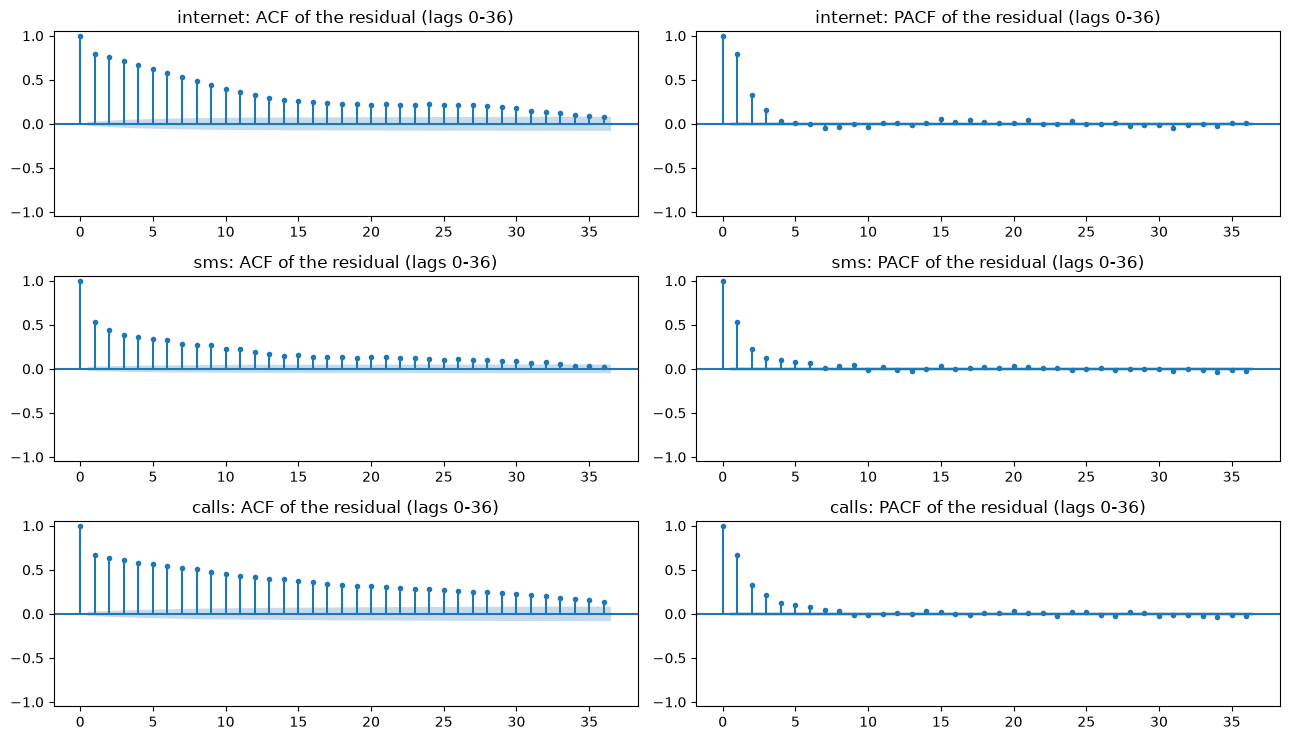

In [13]:
# ARIMA-x, first step: regression on the periodicity terms only (least squares, train set).
# The ACF / PACF of what is left (the residual u) give p and q.
import statsmodels.api as sm

fig, axes = plt.subplots(len(SERIES), 2, figsize=(13, 7.5))
for i, s in enumerate(SERIES):
    ols = sm.OLS(Y[s][:n_train], X_EXOG[:n_train]).fit()
    u = ols.resid
    print(f"{s}: the periodicity terms explain {100 * ols.rsquared:.0f}% of the variation")
    plot_acf(u, lags=36, ax=axes[i, 0], markersize=3, title=f"{s}: ACF of the residual (lags 0-36)")
    plot_pacf(u, lags=36, ax=axes[i, 1], markersize=3, method="ywm", title=f"{s}: PACF of the residual (lags 0-36)")
    for ax in axes[i]:
        ax.set_ylim(-1.05, 1.05)
fig.tight_layout(); plt.show()

Οι όροι περιοδικότητας εξηγούν περίπου το 90% της μεταβολής και στις τρεις σειρές. Αυτό που μένει έχει όμως ακόμη μνήμη: η
PACF έχει λίγες μεγάλες τιμές στα πρώτα lags (τα πρώτα 20 έως 40 λεπτά) και μετά σχεδόν μηδέν, ενώ η ACF φθίνει σταδιακά. Η
εικόνα μοιάζει με AR($p$) με $p \approx 2$ έως $4$ και $q = 0$. Η ACF όμως πέφτει απότομα από το lag 0 στο 1 και μετά φθίνει πολύ
αργά, κάτι που ταιριάζει και σε ένα μικρό ARMA(1, 1). Δοκιμάζουμε λοιπόν και τις δύο μορφές και αφήνουμε το BIC να διαλέξει.

### 2.4 Υποψήφια μοντέλα

Συνοψίζοντας τις ενότητες 2.2 και 2.3, κάθε υπερπαράμετρος εκτιμάται a priori ως εξής:

| Υπερπαράμετρος | Σημασία | Πώς την εκτιμούμε |
|:---|:---|:---|
| $d$ | πόσες διαφορίσεις χρειάζονται για στασιμότητα | τεστ ADF και KPSS, και η μορφή της ACF |
| $D$ | πόσες εποχικές διαφορίσεις χρειάζονται | κορυφές της ACF στα $s, 2s, 3s, \dots$ που φθίνουν αργά |
| $p$ | πόσες προηγούμενες τιμές (AR) | η PACF της στάσιμης σειράς |
| $q$ | πόσες προηγούμενες διαταραχές (MA) | η ACF της στάσιμης σειράς |
| $P, Q$ | το ίδιο, για τιμές και διαταραχές μία ή περισσότερες περιόδους πίσω | PACF και ACF στα lags $s, 2s, \dots$ |

Οι γραφικές εκτιμήσεις δίνουν ένα εύρος τιμών. Η τελική επιλογή μέσα σε αυτό το εύρος γίνεται με το κριτήριο πληροφορίας BIC,
που ορίζουμε στη συνέχεια.

Η καθαρή ARIMA δεν μπορεί να περιγράψει το ημερήσιο μοτίβο, οπότε εξετάζουμε τις δύο μορφές που το περιλαμβάνουν:

| Μοντέλο | $d$ | $D$ | $P$ | $Q$ | $p$ | $q$ | Από πού |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|:---|
| SARIMA | 0 | 1 | 0 | 1 | 4 έως 6 | 0 (ή μικρό) | ADF/KPSS και ACF/PACF της $\Delta_{144}\, y$ |
| ARIMA-x | 0 | – | – | – | 2 έως 4, ή ARMA(1, 1) | 0 ή 1 | ACF/PACF των καταλοίπων της παλινδρόμησης |

Οι τιμές του πίνακα είναι κοινές και για τις τρεις σειρές, γιατί η εικόνα των τεστ και των γραφημάτων ήταν ίδια. Κάθε σειρά όμως
εκτιμάται ξεχωριστά: έχει τις δικές της παραμέτρους, και το BIC διαλέγει για καθεμία τα δικά της $p, q$.

Στο ARIMA-x δεν υπάρχουν $D, P, Q$, γιατί τον ημερήσιο και τον εβδομαδιαίο κύκλο τους καλύπτουν οι εξωτερικές μεταβλητές $x_t$.

Με αυτές τις τιμές το SARIMA γράφεται:

$$\phi(B)\,(1 - B^{144})\, y_t \;=\; \theta(B)\,(1 + \Theta_1 B^{144})\,\varepsilon_t$$

Στον κώδικα κάνουμε πρώτα τη διαφόριση, $z_t = (1 - B^{144})\, y_t = y_t - y_{t-144}$, και εκτιμούμε στη $z_t$ το υπόλοιπο μέρος,
$\phi(B)\, z_t = \theta(B)\,(1 + \Theta_1 B^{144})\,\varepsilon_t$.

Το ARIMA-x γράφεται $y_t = \beta^\top x_t + u_t$, με $\phi(B)\, u_t = \theta(B)\,\varepsilon_t$.

### 2.5 Εκτίμηση των παραμέτρων και επιλογή τάξης με BIC

Για κάθε υποψήφια τάξη $(p, q)$ μένει να βρούμε τις τιμές των $\phi, \theta, \Theta$ (και των $\beta$ στο ARIMA-x). Το
`SARIMAX` του `statsmodels` τις εκτιμά με μέγιστη πιθανοφάνεια (MLE): διαλέγει τις παραμέτρους με τις οποίες τα δεδομένα που
παρατηρήσαμε είναι πιο πιθανά. Με κανονικά σφάλματα αυτό είναι περίπου το ίδιο με το να ελαχιστοποιούμε τα τετράγωνα των σφαλμάτων
πρόβλεψης ενός βήματος στο train.

Την εποχική διαφόριση του SARIMA την κάνουμε μόνοι μας και δίνουμε στο μοντέλο τη σειρά $y_t - y_{t-144}$, γιατί έτσι το μοντέλο
έχει περίπου το μισό μέγεθος. Ακόμη κι έτσι κάθε fit του SARIMA είναι πολύ αργό, ενώ του ARIMA-x γρήγορο (ο κώδικας τυπώνει τους
χρόνους). Γι' αυτό κάθε fit αποθηκεύεται στο `results/arima_grid` και το κελί ξανατρέχει άμεσα.

Τα ACF/PACF δίνουν ένα εύρος και όχι μία τιμή, οπότε η τελική τάξη επιλέγεται με το BIC στο train:

$$\text{BIC} = -2 \ln L + k \ln n$$

Το $L$ είναι η πιθανοφάνεια, το $k$ το πλήθος των παραμέτρων και το $n$ το πλήθος των σημείων. Μικρότερο BIC σημαίνει καλύτερη
ισορροπία ανάμεσα στην προσαρμογή και στην πολυπλοκότητα. Δοκιμάζουμε ένα μικρό πλέγμα γύρω από τα εύρη που βρήκαμε:
$p \in \{2, 4, 6\}$, $q \in \{0, 1\}$ για το SARIMA (το $p = 2$ για την περίπτωση που αρκεί ένα μικρό ARMA) και
$p \in \{1, 2, 4\}$, $q \in \{0, 1\}$ για το ARIMA-x.

In [14]:
import glob, json, os, time
from pathlib import Path
from joblib import Parallel, delayed
from statsmodels.tsa.statespace.sarimax import SARIMAX

GRID_DIR = "results/arima_grid"                       # one JSON per fit: a rerun only reads them
RETRAIN_ARIMA = False
N_JOBS = min(12, os.cpu_count())                      # parallel workers (12 on the server that produced the results)
FAMILIES = {"SARIMA": (None, (2, 4, 6), (0, 1)),      # name: (inputs, p values, q values)
            "ARIMA-x": (X_EXOG, (1, 2, 4), (0, 1))}


def make_model(y, family, p, q, X=None):
    if family == "SARIMA":                            # D = 1 done by hand: the model sees y[t] - y[t-144]
        return SARIMAX(y[SEASON:] - y[:-SEASON], order=(p, 0, q), seasonal_order=(0, 0, 1, SEASON))
    return SARIMAX(y, exog=X[:len(y)], order=(p, 0, q))


def fit_one(s, family, p, q):
    path = f"{GRID_DIR}/{s}_{family}_{p}_{q}.json"
    if os.path.exists(path) and not RETRAIN_ARIMA:
        return
    warnings.filterwarnings("ignore")
    t0 = time.perf_counter()
    r = make_model(Y[s][:n_train], family, p, q, FAMILIES[family][0]).fit(
        disp=False, maxiter=60 if family == "SARIMA" else 300, cov_type="none")
    with open(path, "w") as f:
        json.dump({"series": s, "model": family, "p": p, "q": q, "BIC": float(r.bic), "params": r.params.tolist(),
                   "names": list(r.param_names), "converged": bool(r.mle_retvals.get("converged")),
                   "fit_seconds": time.perf_counter() - t0}, f)


os.makedirs(GRID_DIR, exist_ok=True)
jobs = [(s, fam, p, q) for s in SERIES for fam, (_, ps, qs) in FAMILIES.items() for p in ps for q in qs]
Parallel(n_jobs=N_JOBS)(delayed(fit_one)(*j) for j in jobs)       # slow only the first time

GRID = pd.DataFrame([json.loads(Path(f).read_text()) for f in glob.glob(f"{GRID_DIR}/*.json")])
BEST = GRID.loc[GRID.groupby(["series", "model"])["BIC"].idxmin()].set_index(["series", "model"])   # lowest BIC
print(f"{len(GRID)} fits, {GRID['converged'].sum()} converged")
print("mean fit time (s):", GRID.groupby("model")["fit_seconds"].mean().round().to_dict())

# BIC of every order (rows: model, p / columns: series, q)
display(GRID.pivot_table(index=["model", "p"], columns=["series", "q"], values="BIC")
        .reindex(list(FAMILIES), level=0).reindex(SERIES, axis=1, level=0).round(1))
# Chosen order (p, d, q)
display(BEST.apply(lambda b: f"({b.p},0,{b.q})", axis=1).unstack("model").reindex(SERIES)[list(FAMILIES)])

36 fits, 36 converged
mean fit time (s): {'ARIMA-x': 11.0, 'SARIMA': 1313.0}


series    internet               sms             calls         
q                0        1        0        1        0        1
model   p                                                      
SARIMA  2  73674.2  73468.1  57780.3  57230.2  53010.5  52373.3
        4  73470.6  73477.1  57392.6  57239.4  52467.6  52379.5
        6  73483.8  73493.2  57272.7  57252.6  52371.4  52377.7
ARIMA-x 1  75641.6  74733.6  58558.3  57988.3  54157.3  52883.6
        2  74888.0  74737.8  58212.6  57964.0  53408.5  52887.8
        4  74748.6  74756.7  58048.7  57977.7  53011.8  52904.7

model,SARIMA,ARIMA-x
series,,
internet,"(2,0,1)","(1,0,1)"
sms,"(2,0,1)","(2,0,1)"
calls,"(6,0,0)","(1,0,1)"


#### Επιλογή με BIC

Ο πρώτος πίνακας δείχνει το BIC κάθε τάξης και ο δεύτερος την τάξη με το μικρότερο BIC, που επιλέγεται.

* Το BIC προσθέτει σχεδόν παντού ένα MA ($q = 1$). Στο ARIMA-x αυτό συμφωνεί με το ARMA(1, 1) που έδειξαν τα κατάλοιπα. Στο SARIMA,
  ένα μικρό $p$ με $q = 1$ κάνει τη δουλειά ενός μεγαλύτερου AR με λιγότερες παραμέτρους.
* Στα Calls οι τάξεις (6,0,0) και (2,0,1) του SARIMA έχουν πρακτικά ίδιο BIC.
* Στο SARIMA οι επιλογές πέφτουν στις άκρες του πλέγματος: το μικρότερο $p$ για Internet και SMS, το μεγαλύτερο για Calls. Μια τάξη
  λίγο έξω από το πλέγμα μπορεί να είναι οριακά καλύτερη, αλλά δεν τη δοκιμάζουμε, γιατί κάθε fit του SARIMA είναι πολύ αργό.
* Το BIC δεν συγκρίνει το SARIMA με το ARIMA-x, γιατί εκτιμώνται σε διαφορετικά δεδομένα (διαφορισμένη και αρχική σειρά). Τα
  συγκρίνουμε αργότερα στο test.

### 2.6 Διαγνωστικός έλεγχος των καταλοίπων (train)

Πριν αξιολογήσουμε τις προβλέψεις στο test, ελέγχουμε αν τα μοντέλα έχουν πιάσει τη δομή της σειράς. Αν ναι, τα κατάλοιπά
τους (τα σφάλματα ενός βήματος στο train) πρέπει να μοιάζουν με λευκό θόρυβο, χωρίς αυτοσυσχέτιση. Το ελέγχουμε με την ACF
των καταλοίπων και το τεστ Ljung-Box, με H0 ότι δεν υπάρχει αυτοσυσχέτιση ως το lag $h$. Το Q-Q plot δείχνει αν είναι
κανονικά, κάτι που χρειάζεται για τα διαστήματα πρόβλεψης που θα δούμε αργότερα. Ο έλεγχος αυτός δείχνει μόνο αν ένα μοντέλο
αφήνει κάτι έξω, όχι πόσο καλά προβλέπει.

In [15]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats


def filter_model(y, s, family, X=None):
    """Run the fitted model over y without changing its parameters."""
    b = BEST.loc[(s, family)]
    return make_model(y, family, int(b["p"]), int(b["q"]), X).filter(b["params"], cov_type="none")


diag, RESID = [], {}
for (s, fam), b in BEST.iterrows():
    # one-step errors on the train set; the first two days are skipped while the filter warms up
    e = filter_model(Y[s][:n_train], s, fam, FAMILIES[fam][0]).resid[2 * SEASON:]
    RESID[(s, fam)] = e
    t = df.index[n_train - len(e):n_train]
    day = (t.hour >= 8) & (t.hour < 20)
    params = dict(zip(b["names"], b["params"]))
    diag.append({"series": s, "model": fam,
                 "order": f"({b['p']},0,{b['q']})" + ("(0,1,1)_144" if fam == "SARIMA" else ""),
                 "Θ1": round(params["ma.S.L144"], 3) if fam == "SARIMA" else None,
                 "max |ACF|": round(np.abs(acf(e, nlags=SEASON + 10)[1:]).max(), 3),
                 "Ljung-Box p (lag 10)": round(acorr_ljungbox(e, lags=[10])["lb_pvalue"].iloc[0], 4),
                 "excess kurtosis": round(stats.kurtosis(e), 1),
                 "std day / night": round(e[day].std() / e[~day].std(), 1)})
pd.DataFrame(diag).set_index(["series", "model"]).reindex(SERIES, level=0)

order     Θ1  max |ACF|  Ljung-Box p (lag 10)  \
series   model                                                                 
internet ARIMA-x             (1,0,1)    NaN      0.083                0.0000   
         SARIMA   (2,0,1)(0,1,1)_144 -0.998      0.066                0.0000   
sms      ARIMA-x             (2,0,1)    NaN      0.066                0.2365   
         SARIMA   (2,0,1)(0,1,1)_144 -0.986      0.064                0.0346   
calls    ARIMA-x             (1,0,1)    NaN      0.070                0.0164   
         SARIMA   (6,0,0)(0,1,1)_144 -0.994      0.072                0.0000   

                  excess kurtosis  std day / night  
series   model                                      
internet ARIMA-x              8.0              1.6  
         SARIMA               6.8              1.6  
sms      ARIMA-x              3.9              2.5  
         SARIMA               3.4              2.6  
calls    ARIMA-x              2.9              3.2  
         SARIMA               2.7              3.3

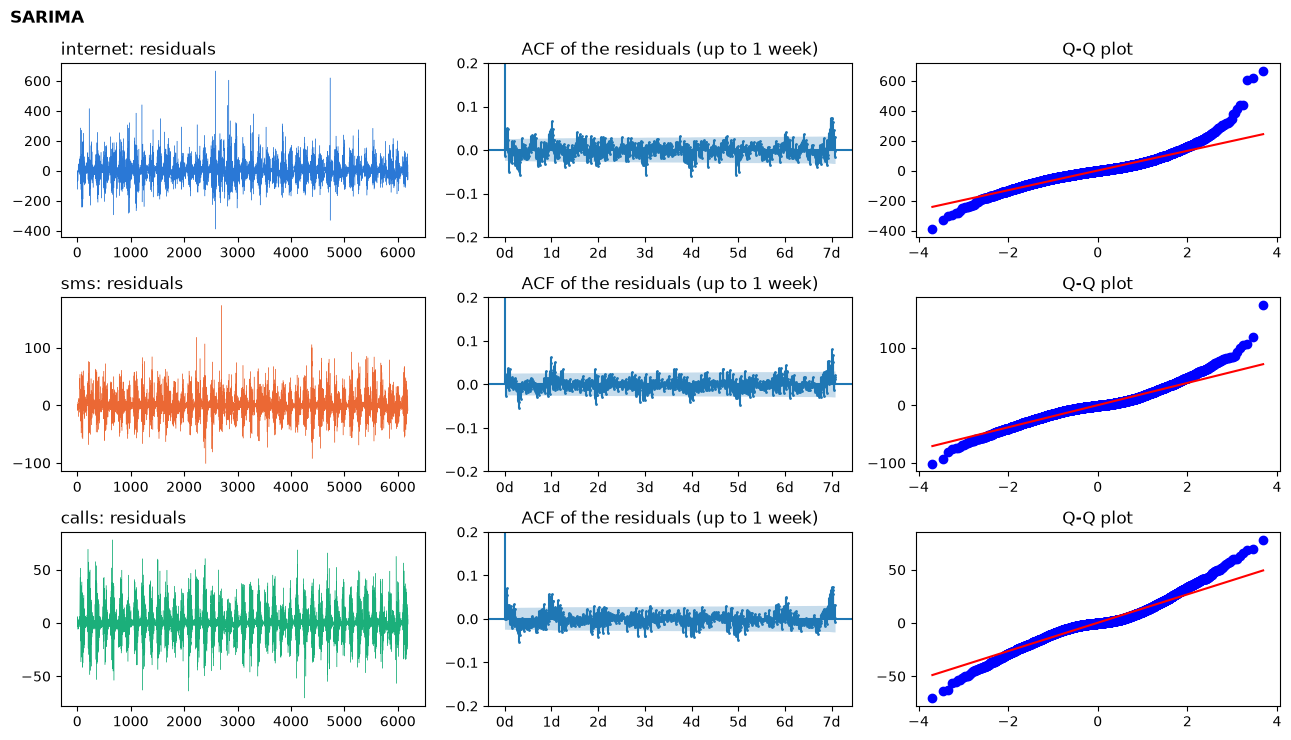

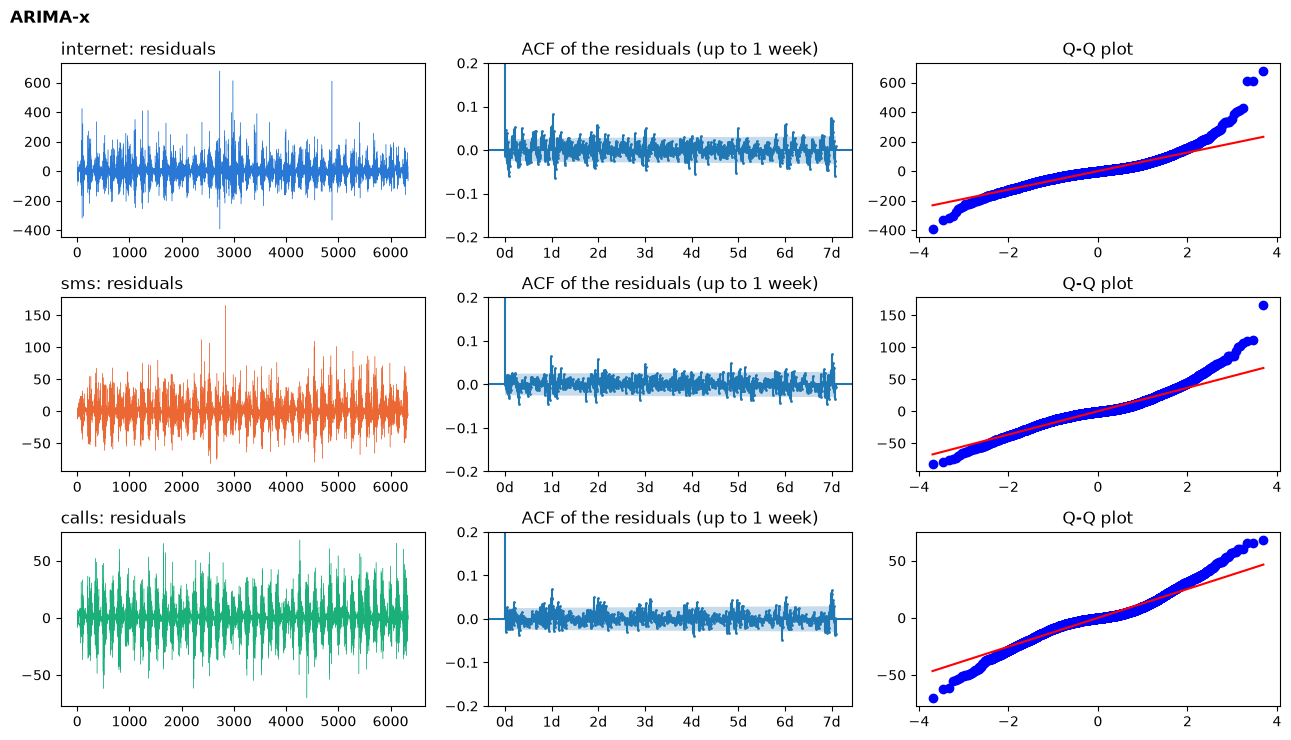

In [16]:
# Residuals of each model: time plot, ACF up to one week, Q-Q plot
for fam in FAMILIES:
    fig, axes = plt.subplots(len(SERIES), 3, figsize=(13, 7.5))
    for i, s in enumerate(SERIES):
        e = RESID[(s, fam)]
        axes[i, 0].plot(e, lw=0.3, color=COLOR[s]); axes[i, 0].set_title(f"{s}: residuals", loc="left")
        plot_acf(e, lags=WEEK + 12, ax=axes[i, 1], markersize=1, title="ACF of the residuals (up to 1 week)")
        axes[i, 1].set_ylim(-0.2, 0.2)
        axes[i, 1].set_xticks(range(0, WEEK + 1, SEASON), [f"{d}d" for d in range(8)])
        stats.probplot(e, plot=axes[i, 2]); axes[i, 2].set_title("Q-Q plot"); axes[i, 2].set_xlabel(""); axes[i, 2].set_ylabel("")
    fig.suptitle(fam, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

#### Ερμηνεία

Τα κατάλοιπα είναι κοντά στον λευκό θόρυβο: η μεγαλύτερη απόλυτη αυτοσυσχέτιση μένει κάτω από 0.1. Το Ljung-Box απορρίπτει παρ'
όλα αυτά τη λευκότητα σχεδόν παντού, γιατί με χιλιάδες σημεία ανιχνεύει και πολύ μικρές αυτοσυσχετίσεις. Οι μεγαλύτερες βρίσκονται
γύρω από τη μία ημέρα και τη μία εβδομάδα (στο 1d και στο 7d της ACF): το σφάλμα μοιάζει λίγο με το σφάλμα της ίδιας ώρας χθες και
την ίδια ημέρα της προηγούμενης εβδομάδας. Το εβδομαδιαίο μοτίβο το περιγράφει μόνο κατά προσέγγιση το ARIMA-x, με λίγους
εβδομαδιαίους όρους Fourier, και καθόλου το SARIMA. Οι αυτοσυσχετίσεις αυτές είναι μικρές, άρα και το κέρδος από ένα πιο σύνθετο
μοντέλο θα ήταν μικρό.

Τα κατάλοιπα δεν είναι κανονικά: το Q-Q plot δείχνει βαριές ουρές (θετική υπερβάλλουσα κύρτωση), πιο έντονες στο Internet. Είναι
επίσης ετεροσκεδαστικά: η διασπορά τους είναι μεγαλύτερη τη μέρα (08:00 έως 20:00) από ό,τι τη νύχτα, ιδίως στα SMS και στα Calls.

Οι βαριές ουρές έχουν δύο αιτίες, και καμία δεν είναι λάθος του μοντέλου. Η πρώτη είναι αυτή η διαφορά μέρας και νύχτας: όταν
ανακατεύονται μικρά νυχτερινά και μεγάλα ημερήσια σφάλματα, η συνολική κατανομή έχει βαριές ουρές ακόμη κι αν κάθε ώρα χωριστά
είναι σχεδόν κανονική. Η δεύτερη είναι οι απρόβλεπτες αιχμές, που κανένα μοντέλο δεν μπορεί να προβλέψει από το παρελθόν.

Η μη κανονικότητα δεν επηρεάζει τις σημειακές προβλέψεις, αλλά επηρεάζει τα διαστήματα πρόβλεψης: ένα διάστημα σταθερού πλάτους θα
είναι πολύ φαρδύ τη νύχτα και πολύ στενό στις αιχμές. Αυτό θα το δούμε αργότερα, στα διαστήματα πρόβλεψης.

Τα γραφήματα δείχνουν πρώτα το SARIMA και μετά το ARIMA-x. Τα κατάλοιπα των δύο μοντέλων μοιάζουν πολύ.

Στο SARIMA και στις τρεις σειρές το $\Theta_1$ είναι πολύ κοντά στο $-1$ (στήλη Θ1). Τότε ο όρος $(1 + \Theta_1 B^{144})$ σχεδόν
αναιρεί την εποχική διαφόριση $(1 - B^{144})$, δηλαδή το μοντέλο δεν αντιγράφει τη χθεσινή ημέρα αλλά μαθαίνει ένα σχεδόν σταθερό
ημερήσιο σχήμα από πολλές ημέρες. Είναι ουσιαστικά η ίδια ιδέα με τους ημερήσιους όρους Fourier του ARIMA-x. Η τιμή είναι κοντά
στο όριο της αντιστρεψιμότητας ($|\Theta_1| < 1$), αλλά δεν το ξεπερνά.

### 2.7 Rolling-window πρόβλεψη ($h = 1$ και $H = 5$)

Ακολουθούμε τη διαδικασία των Siami-Namini et al. (ICMLA 2018):

```
history <- train
for t in test:
    model   <- ARIMA(history)        # νέο fit σε κάθε βήμα
    y_hat_t <- model.forecast()
    history.append(y_t)           # προσθέτουμε την ΠΡΑΓΜΑΤΙΚΗ τιμή, όχι την πρόβλεψη
```

Μετά από κάθε πρόβλεψη το μοντέλο μαθαίνει την πραγματική τιμή και ξαναεκτιμάται σε όλο το ιστορικό ως εκείνη τη στιγμή, όπως
ένα δίκτυο που μετρά συνεχώς το φορτίο. Το παράθυρο στην πράξη μεγαλώνει (expanding window): το μοντέλο κρατά όλο το ιστορικό.

Γιατί μόνο το ARIMA-x. Η διαδικασία χρειάζεται ένα νέο fit για κάθε σημείο του test. Κάθε fit του SARIMA κρατά πολλά λεπτά: ο
εποχικός όρος MA στο lag 144 αναγκάζει το μοντέλο να κρατά στη μνήμη του τις τελευταίες 144 διαταραχές, και η πιθανοφάνεια
υπολογίζεται σε κάθε σημείο με πίνακες αυτού του μεγέθους. Για όλο το test θα χρειαζόταν περίπου έναν μήνα υπολογισμού ανά σειρά.
Το SARIMA είναι λοιπόν πολύ αργό για να είναι πρακτικό, και από εδώ και πέρα συνεχίζουμε μόνο με το ARIMA-x. Αυτό περιγράφει τον
ημερήσιο κύκλο με όρους Fourier αντί για εποχικό MA, η μνήμη του είναι πολύ μικρή, και κάθε fit του είναι γρήγορο, ιδίως όταν
ξεκινά από τις παραμέτρους του προηγούμενου βήματος.

Από κάθε σημείο του test προβλέπουμε 5 βήματα. Το πρώτο δίνει το $h = 1$. Για το $H = 5$ κρατάμε τα 5 βήματα από κάθε πέμπτο
σημείο, ώστε κάθε σημείο του test να μετρά μία φορά. Το `res.forecast` προβλέπει αναδρομικά: βάζει 0 στις άγνωστες μελλοντικές
διαταραχές και χρησιμοποιεί κάθε πρόβλεψη ως είσοδο για την επόμενη. Οι όροι $x_{t+j}$ είναι γνωστοί από πριν, οπότε
$\hat y_{t+j} = \beta^\top x_{t+j} + \hat u_{t+j}$.

Η εκφώνηση αναφέρει ιστορικό παράθυρο π.χ. $w = 10$. Στο ARIMA-x το παράθυρο δεν είναι ελεύθερη επιλογή, αλλά προκύπτει από το
μοντέλο, που βλέπει όλο το ιστορικό μέσα από τη μνήμη του. Ένα μοντέλο εκτιμημένο σε 10 σημεία δεν θα έβλεπε καν την ημερήσια
περίοδο.

In [17]:
H_SHORT, H_LONG = 1, 5
idx1 = np.arange(n_train, N)                               # h = 1: every test point
origins5 = np.arange(n_train, N - H_LONG + 1, H_LONG)      # H = 5: every 5th test point
idx5 = (origins5[:, None] + np.arange(H_LONG)).ravel()

ROLL_DIR = "results/arima_roll"                            # one file per series: the refits take a while
RETRAIN_ROLL = False
ARIMA_MODELS = ["ARIMA-x"]                                 # SARIMA is too slow to refit at every step


def refit_chunk(s, origins, start_params):
    """At each origin t: refit on everything before t, then forecast H_LONG steps ahead."""
    warnings.filterwarnings("ignore")
    p, q = int(BEST.loc[(s, "ARIMA-x"), "p"]), int(BEST.loc[(s, "ARIMA-x"), "q"])
    params, out = np.asarray(start_params), []
    for t in origins:
        t0 = time.perf_counter()
        res = make_model(Y[s][:t], "ARIMA-x", p, q, X_EXOG).fit(start_params=params, disp=False, maxiter=300,
                                                                  cov_type="none")
        params = res.params                                # warm start for the next origin
        steps = int(min(H_LONG, N - t))                    # a plain int: forecast() reads a numpy int as an end index
        path = np.full(H_LONG, np.nan)
        path[:steps] = res.forecast(steps, exog=X_EXOG[t:t + steps])
        out.append((path, np.sqrt(params[-1]), time.perf_counter() - t0))
    return out


def rolling_forecast(s, n_jobs=N_JOBS):
    file = f"{ROLL_DIR}/{s}.npz"
    if not os.path.exists(file) or RETRAIN_ROLL:
        chunks = np.array_split(idx1, n_jobs)              # each worker takes a block of consecutive origins
        parts = Parallel(n_jobs=n_jobs)(delayed(refit_chunk)(s, c, BEST.loc[(s, "ARIMA-x"), "params"]) for c in chunks)
        out = [r for part in parts for r in part]
        np.savez(file, paths=np.array([r[0] for r in out]), sigma=np.array([r[1] for r in out]),
                 seconds=np.array([r[2] for r in out]))
    d = np.load(file)                                      # paths[i, j]: forecast from test point i, j+1 steps ahead
    return {"h1": d["paths"][:, 0], "H5": d["paths"][origins5 - n_train].ravel(), "sigma_h1": d["sigma"],
            "seconds_per_forecast": d["seconds"].mean()}


os.makedirs(ROLL_DIR, exist_ok=True)
ARIMA_ROLL = {(s, "ARIMA-x"): rolling_forecast(s) for s in SERIES}      # slow only the first time
print(pd.Series({s: 1e3 * ARIMA_ROLL[(s, "ARIMA-x")]["seconds_per_forecast"] for s in SERIES},
                name="ARIMA-x: ms per forecast (refit + forecast)").round().to_string())

internet    1025.0
sms         1724.0
calls       1496.0


### 2.8 Σύνοψη

Τα ADF/KPSS έδωσαν $d = 0$ και η ACF ισχυρή ημερήσια εποχικότητα. Την περιγράψαμε με δύο τρόπους:

* SARIMA: εποχική διαφόριση ($D = 1$, $s = 144$) με $P = 0$, $Q = 1$, και μικρά $p, q$ από το BIC. Είναι πολύ αργό για τη
  rolling πρόβλεψη με νέο fit σε κάθε βήμα, οπότε δεν το κρατάμε στη σύγκριση.
* ARIMA-x: όροι Fourier για την ημέρα και την εβδομάδα, δείκτης μη εργάσιμης ημέρας, και ένα μικρό ARMA για ό,τι μένει. Αυτό
  εκπροσωπεί την οικογένεια ARIMA στη σύγκριση.

Τα κατάλοιπα και των δύο είναι κοντά στον λευκό θόρυβο, με βαριές ουρές και μεγαλύτερη διασπορά τη μέρα. Την αποτίμηση στο test
την κάνουμε αργότερα, μαζί με όλα τα υπόλοιπα μοντέλα.

## 3. Deep learning: LSTM

Η ενότητα αυτή εφαρμόζει ένα αναδρομικό νευρωνικό δίκτυο (LSTM) στο ίδιο πρόβλημα, με την ίδια διαδικασία
αποτίμησης (ίδιο train/test, ίδιοι ορίζοντες, ίδια σημεία του test, ίδιες μετρικές), ώστε η σύγκριση με την
οικογένεια ARIMA να είναι δίκαιη. Αυτό είναι και το ζητούμενο του άρθρου των Siami-Namini et al.

### 3.1 Θεωρία

#### 3.1.1 Από τα γραμμικά μοντέλα στα νευρωνικά δίκτυα

Η ARIMA είναι γραμμική: η πρόβλεψη είναι ένα σταθμισμένο άθροισμα προηγούμενων τιμών και διαταραχών. Ένα
νευρωνικό δίκτυο μαθαίνει μια μη γραμμική συνάρτηση $\hat y = f_\theta(\text{ιστορικό})$, με παραμέτρους $\theta$
που εκτιμώνται ελαχιστοποιώντας ένα σφάλμα στο train με gradient descent. Έτσι μπορεί, κατ' αρχήν, να μάθει σχέσεις
που η ARIMA δεν μπορεί να εκφράσει (π.χ. «η άνοδος είναι πιο απότομη τα πρωινά των εργάσιμων»). Το τίμημα είναι
πολλές περισσότερες παράμετροι, ανάγκη για περισσότερα δεδομένα και κίνδυνος υπερπροσαρμογής.

#### 3.1.2 Αναδρομικά δίκτυα (RNN)

Ένα RNN διαβάζει την ακολουθία ένα βήμα τη φορά και κρατά μια κρυφή κατάσταση $h_t$, που λειτουργεί σαν μνήμη
όσων έχει δει ως τώρα:

$$h_t = \tanh\!\big(W x_t + U h_{t-1} + b\big)$$

Οι ίδιοι πίνακες $W, U$ χρησιμοποιούνται σε κάθε βήμα, οπότε το δίκτυο εφαρμόζει τον ίδιο «κανόνα ενημέρωσης» σε
όλη την ακολουθία, όπως ακριβώς η ARIMA εφαρμόζει τους ίδιους συντελεστές σε κάθε $t$. Η πρόβλεψη βγαίνει από την
τελευταία κατάσταση: $\hat y = V h_t + c$.

Το πρόβλημα των vanishing gradients. Η εκπαίδευση γίνεται με *Backpropagation Through Time*: το gradient του
σφάλματος ως προς μια κατάσταση $k$ βήματα πίσω είναι γινόμενο $k$ Ιακωβιανών:

$$\frac{\partial h_t}{\partial h_{t-k}} \;=\; \prod_{j=0}^{k-1} \frac{\partial h_{t-j}}{\partial h_{t-j-1}} \;=\; \prod_{j=0}^{k-1} \operatorname{diag}\!\big(1 - h_{t-j}^2\big)\, U$$

Αν οι παράγοντες έχουν μέτρο μικρότερο από 1, το γινόμενο μηδενίζεται εκθετικά (vanishing gradient) και το δίκτυο
δεν μπορεί να μάθει εξαρτήσεις από μακρινό παρελθόν. Αν έχουν μέτρο μεγαλύτερο από 1, εκρήγνυται (exploding
gradient) και η εκπαίδευση γίνεται ασταθής. Στο πρόβλημά μας αυτό έχει σημασία: όταν το δίκτυο βλέπει μια ολόκληρη ημέρα (144 βήματα),
πρέπει να συνδέσει την τρέχουσα τιμή με τιμές 144 βημάτων πριν.

#### 3.1.3 LSTM (Hochreiter και Schmidhuber, 1997)

Το LSTM λύνει το πρόβλημα προσθέτοντας μια δεύτερη κατάσταση, την κατάσταση κελιού $c_t$ (μακροπρόθεσμη μνήμη), και
τρεις πύλες που αποφασίζουν τι ξεχνιέται, τι γράφεται και τι διαβάζεται. Κάθε πύλη είναι ένα διάνυσμα με τιμές στο
$(0, 1)$, μέσω της σιγμοειδούς $\sigma(x) = 1 / (1 + e^{-x})$, και πολλαπλασιάζεται στοιχείο προς στοιχείο ($\odot$):

$$
\begin{aligned}
f_t &= \sigma\big(W_f x_t + U_f h_{t-1} + b_f\big) && \text{forget gate: πόσο από την παλιά μνήμη κρατάμε} \\[3pt]
i_t &= \sigma\big(W_i x_t + U_i h_{t-1} + b_i\big) && \text{input gate: πόση νέα πληροφορία γράφουμε} \\[3pt]
\tilde c_t &= \tanh\big(W_c x_t + U_c h_{t-1} + b_c\big) && \text{υποψήφια νέα πληροφορία} \\[3pt]
c_t &= f_t \odot c_{t-1} \;+\; i_t \odot \tilde c_t && \text{ενημέρωση της μνήμης} \\[3pt]
o_t &= \sigma\big(W_o x_t + U_o h_{t-1} + b_o\big) && \text{output gate: τι από τη μνήμη δίνουμε ως έξοδο} \\[3pt]
h_t &= o_t \odot \tanh(c_t) && \text{νέα κρυφή κατάσταση}
\end{aligned}
$$

Γιατί δουλεύει. Η ενημέρωση της μνήμης $c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$ είναι προσθετική. Στον άμεσο δρόμο
μέσω της μνήμης, το gradient από το $c_t$ προς το $c_{t-1}$ είναι απλώς $f_t$, όχι γινόμενο με έναν πίνακα βαρών και μια παράγωγο
$\tanh$. Όταν το δίκτυο μάθει $f_t \approx 1$, η πληροφορία και το gradient περνούν πολλά βήματα σχεδόν
αναλλοίωτα. Οι πύλες μαθαίνονται από τα δεδομένα, οπότε το δίκτυο αποφασίζει μόνο του τι αξίζει να θυμάται (π.χ. «η
κίνηση ανεβαίνει εδώ και μία ώρα») και τι να ξεχάσει.

### 3.2 Διατύπωση ως πρόβλημα επιβλεπόμενης μάθησης

Κόβουμε τη σειρά σε παράθυρα: είσοδος οι τελευταίες $w$ τιμές, στόχος οι επόμενες $h$.

$$(y_{t-w},\; \dots,\; y_{t-1}) \;\longmapsto\; (y_t,\; \dots,\; y_{t+h-1})$$

Εδώ, σε αντίθεση με την ARIMA, το $w$ είναι πραγματική επιλογή, γιατί το δίκτυο βλέπει μόνο ό,τι είναι μέσα στο
παράθυρο. Δοκιμάζουμε $w = 10$ (100 λεπτά), την τιμή της εκφώνησης, και $w = 144$ (24 ώρες), όπου το παράθυρο περιέχει
ολόκληρη την προηγούμενη ημέρα και το δίκτυο μπορεί να μάθει την ημερήσια περιοδικότητα.

Για $H = 5$ το δίκτυο έχει 5 εξόδους και τις βγάζει όλες μαζί. Έτσι ένα λάθος στο βήμα 1 δεν γίνεται είσοδος για το βήμα 2,
όπως στην αναδρομική πρόβλεψη της ARIMA. Για $h = 1$ οι δύο τρόποι ταυτίζονται.


### 3.3 Κανονικοποίηση min-max στο $[0, 1]$

Στην είσοδο οι τιμές μετασχηματίζονται ώστε το train να πιάνει ακριβώς το $[0, 1]$, και στην έξοδο γίνεται το αντίστροφο:

$$\tilde y_t = \frac{y_t - y_{\min}}{y_{\max} - y_{\min}} \qquad\qquad \hat y_t = \hat{\tilde y}_t \,\big(y_{\max} - y_{\min}\big) + y_{\min}$$

Η ARIMA δεν το χρειάζεται, γιατί είναι γραμμική: μια αλλαγή κλίμακας απλώς αλλάζει την κλίμακα των συντελεστών. Το LSTM το χρειάζεται, γιατί οι πύλες του έχουν παράγωγο σχεδόν μηδέν για
μεγάλες εισόδους: με τιμές της τάξης του 1000 θα κολλούσαν στο 0 ή στο 1 και το δίκτυο δεν θα μάθαινε.

Τα $y_{\min}, y_{\max}$ υπολογίζονται μόνο στο τμήμα του train με το οποίο εκπαιδεύεται το δίκτυο, χωρίς το validation
(ενότητα 3.5) και φυσικά χωρίς το test. Αν τα υπολογίζαμε σε όλη τη σειρά, η κανονικοποίηση θα «ήξερε» την αιχμή της
Πρωτοχρονιάς, δηλαδή πληροφορία από το μέλλον. Γι' αυτό στο test οι τιμές μπορεί να βγουν έξω από το $[0, 1]$, και όχι λίγο: τα μεσάνυχτα της Πρωτοχρονιάς τα SMS φτάνουν
περίπου το τετραπλάσιο και τα Calls σχεδόν το διπλάσιο του μέγιστου του train. Το δίκτυο δεν έχει δει ποτέ τέτοιες τιμές, οπότε
αναμένεται να τις υποεκτιμήσει.

### 3.4 Από-περιοδικοποίηση (deseasonalisation)

Ορίζουμε το προφίλ $S_t$ ως τη μέση τιμή για τον ίδιο τύπο ημέρας και το ίδιο δεκάλεπτο (το προφίλ της EDA), υπολογισμένη
στο τμήμα του train πριν από το validation. Αν το validation έμπαινε στο προφίλ, κάθε ημέρα του validation θα ήταν ένα από τα
λίγα σημεία του μέσου όρου με τον οποίο τη συγκρίνουμε (για το Σάββατο, π.χ., μόνο όσα Σάββατα έχει το train). Το υπόλοιπο
$r_t$ θα έβγαινε τότε τεχνητά μικρό, και η από-περιοδικοποίηση θα φαινόταν στο validation καλύτερη από ό,τι είναι.
Το δίκτυο μαθαίνει το υπόλοιπο, και στο τέλος προσθέτουμε πίσω το προφίλ, που είναι γνωστό για κάθε μελλοντική στιγμή:

$$r_t = y_t - S_t \qquad\longrightarrow\qquad \text{LSTM} \qquad\longrightarrow\qquad \hat y_t = \hat r_t + S_t$$

Βοηθά γιατί το δίκτυο δεν χρειάζεται να μάθει το ημερήσιο σχήμα και εστιάζει στις αποκλίσεις. Για $w = 10$ είναι ο μόνος
τρόπος να «ξέρει» ότι σε μία ώρα έρχεται η μεσημεριανή αιχμή. Είναι η ίδια ιδέα με το ARIMA-x.

Μπορεί όμως να βλάψει όταν το μοτίβο του test διαφέρει από του train, γιατί τότε το $S_t$ είναι λάθος. Η εορταστική περίοδος
του test είναι ακριβώς τέτοια περίπτωση.

### 3.5 Αρχιτεκτονική και εκπαίδευση

Το δίκτυο έχει 2 στρώματα LSTM με 64 μονάδες και ένα γραμμικό στρώμα εξόδου, συνολικά περίπου 50 χιλιάδες παραμέτρους.
Η πρόβλεψη βγαίνει από την κατάσταση του τελευταίου βήματος του παραθύρου.

Εκπαιδεύεται με MSE και Adam (learning rate $10^{-3}$, batch 128). Το dropout 0.1 ανάμεσα στα στρώματα περιορίζει την
υπερπροσαρμογή, και το gradient clipping προστατεύει από τα exploding gradients. Οι τιμές αυτές (μέγεθος δικτύου, learning rate,
batch, dropout) είναι συνηθισμένες επιλογές και δεν τις βελτιστοποιήσαμε.

Γιατί χρειάζεται validation. Κατά την κατασκευή του LSTM παίρνουμε δύο αποφάσεις: πόσες εποχές θα εκπαιδευτεί κάθε δίκτυο, και
ποια από τις τέσσερις εκδοχές θα εκπροσωπήσει το LSTM στην ενότητα 5. Για να τις πάρουμε πρέπει να μετρήσουμε ποια επιλογή
προβλέπει καλύτερα δεδομένα που το δίκτυο δεν έχει δει. Το σφάλμα στο train δεν βοηθά: πέφτει πάντα όσο συνεχίζεται η
εκπαίδευση, ακόμη και όταν το δίκτυο έχει αρχίσει να απομνημονεύει τα σημεία του train αντί να μαθαίνει γενικά μοτίβα
(υπερπροσαρμογή, *overfitting*). Το test δεν επιτρέπεται: αν διαλέγαμε με βάση το test, το σφάλμα που αναφέρουμε σε αυτό θα
ήταν αισιόδοξο, γιατί θα είχαμε διαλέξει την εκδοχή που έτυχε να ταιριάζει σε αυτές ακριβώς τις ημέρες. Κρατάμε λοιπόν ένα τρίτο
κομμάτι, το validation: τις τελευταίες ημέρες του train, με τις οποίες το δίκτυο δεν εκπαιδεύεται, οπότε παίζουν τον ρόλο των
άγνωστων δεδομένων χωρίς να αγγίζουμε το test. Είναι χρήσιμο μόνο όσο μοιάζει με το test, κάτι που εδώ δεν ισχύει για τις
γιορτές (ενότητα 5.4).

Το τελευταίο 10% των παραθύρων του train, χρονολογικά, είναι το validation (περίπου οι 4.5 τελευταίες ημέρες, από τις 12/12).
Το προφίλ $S_t$ και τα $y_{\min}, y_{\max}$ υπολογίζονται μόνο από τα σημεία πριν από αυτό, και κανένας στόχος εκπαίδευσης δεν
πέφτει μέσα του. Μετά από κάθε εποχή μετράμε το σφάλμα στο validation. Στην αρχή πέφτει μαζί με του train, γιατί το δίκτυο μαθαίνει μοτίβα που
ισχύουν παντού. Όταν αρχίζει η απομνημόνευση, το σφάλμα του train συνεχίζει να πέφτει, ενώ του validation σταματά να βελτιώνεται.
Σταματάμε λοιπόν όταν το validation loss δεν βελτιώνεται για 8 εποχές και κρατάμε τα βάρη της καλύτερης εποχής (early stopping).
Το test δεν χρησιμοποιείται για καμία απόφαση.

Συνολικά εκπαιδεύονται 3 σειρές $\times$ 2 παράθυρα $\times$ 2 εκδοχές (raw, από-περιοδικοποιημένη) $\times$ 2 ορίζοντες $= 24$
δίκτυα. Τα αποτελέσματα αποθηκεύονται στο `results/lstm_notebook_v2.pkl`, και για νέα εκπαίδευση βάζουμε `RETRAIN = True`.

In [18]:
import joblib
import torch
import torch.nn as nn
from joblib import parallel_config

SEED = 0
LSTM_WINDOWS = (10, 144)


def seasonal_profile(idx, y, n_fit):
    """S_t: mean per (day type, time of day), computed on the first n_fit points (the train set)."""
    key = pd.MultiIndex.from_arrays([day_type(idx), idx.hour + idx.minute / 60])
    return pd.Series(y[:n_fit], index=key[:n_fit]).groupby(level=[0, 1]).mean().reindex(key).values


class LSTMNet(nn.Module):
    def __init__(self, horizon, hidden=64, layers=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, layers, batch_first=True, dropout=dropout)
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x):                      # x: (batch, w, 1)
        out, _ = self.lstm(x)
        return self.head(out[:, -1])           # state of the last time step -> h outputs


def make_windows(z, targets, w, h):
    """Inputs z[t-w:t] and targets z[t:t+h] for every t in targets."""
    X = np.stack([z[t - w:t] for t in targets])[..., None].astype(np.float32)
    Yw = np.stack([z[t:t + h] for t in targets]).astype(np.float32)
    return torch.from_numpy(X), torch.from_numpy(Yw)

In [19]:
def run_lstm(s, w, deseason, h, seed=SEED, max_epochs=80, patience=8, threads=4):
    torch.set_num_threads(threads); torch.manual_seed(seed); np.random.seed(seed)
    y = Y[s]
    # training windows; the last 10% (in time) is the validation set
    targets = np.arange(w, n_train - h + 1)
    n_val = int(0.1 * len(targets))
    val_t = targets[-n_val:]
    n_fit = int(val_t[0])                                   # S_t, min and max see only the points before the validation set
    fit_t = targets[targets + h <= n_fit]                   # no training target falls inside the validation set

    S = seasonal_profile(df.index, y, n_fit) if deseason else np.zeros_like(y)
    r = y - S
    lo, hi = r[:n_fit].min(), r[:n_fit].max()
    z = (r - lo) / (hi - lo)
    Xtr, Ytr = make_windows(z, fit_t, w, h)
    Xva, Yva = make_windows(z, val_t, w, h)

    net = LSTMNet(h)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    lossf = nn.MSELoss()
    best, best_state, bad, hist = np.inf, None, 0, []
    t0 = time.perf_counter()
    for ep in range(max_epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 128):
            b = perm[i:i + 128]
            opt.zero_grad()
            loss = lossf(net(Xtr[b]), Ytr[b])
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        with torch.no_grad():
            tr_loss = lossf(net(Xtr), Ytr).item()
            va_loss = lossf(net(Xva), Yva).item()
        hist.append((tr_loss, va_loss))
        if va_loss < best - 1e-7:                             # early stopping on the validation loss
            best, bad = va_loss, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    train_seconds = time.perf_counter() - t0
    net.load_state_dict(best_state); net.eval()

    # Rolling evaluation on the test set: the input is always the last w ACTUAL values
    origins = np.arange(n_train, N) if h == 1 else np.arange(n_train, N - h + 1, h)
    Xte, _ = make_windows(np.r_[z, np.zeros(h)], origins, w, h)
    with torch.no_grad():
        zhat = net(Xte).numpy()
    tidx = origins[:, None] + np.arange(h)[None, :]
    yhat = (zhat * (hi - lo) + lo + S[tidx]).ravel()          # inverse min-max, then add the profile back
    return {"pred": yhat, "origins": origins, "history": hist, "epochs": len(hist), "n_fit": n_fit, "scale": hi - lo,
            "best_epoch": int(np.argmin([v for _, v in hist])) + 1, "train_seconds": train_seconds,
            "params": sum(p.numel() for p in net.parameters())}

In [20]:
RETRAIN = False
LSTM_FILE = "results/lstm_notebook_v2.pkl"     # v2: profile and min-max fitted without the validation set
LSTM_JOBS = [(s, w, ds, h) for s in SERIES for w in LSTM_WINDOWS for ds in (False, True) for h in (H_SHORT, H_LONG)]

if RETRAIN or not os.path.exists(LSTM_FILE):
    t0 = time.perf_counter()
    with parallel_config(backend="loky", inner_max_num_threads=4):    # one worker per network, 4 threads each
        out = Parallel(n_jobs=min(len(LSTM_JOBS), max(1, os.cpu_count() // 4)))(delayed(run_lstm)(*j) for j in LSTM_JOBS)
    LSTM_RES = dict(zip(LSTM_JOBS, out))
    joblib.dump(LSTM_RES, LSTM_FILE)
    print(f"trained {len(LSTM_JOBS)} networks in {time.perf_counter() - t0:.0f}s")
else:
    LSTM_RES = joblib.load(LSTM_FILE)
    print("loaded", LSTM_FILE)

pd.DataFrame([{"series": s, "w": w, "deseason": ds, "h": h, "params": v["params"], "epochs": v["epochs"],
               "best epoch": v["best_epoch"], "train (s)": round(v["train_seconds"])}
              for (s, w, ds, h), v in LSTM_RES.items()]).set_index(["series", "w", "deseason", "h"])

loaded results/lstm_notebook_v2.pkl


params  epochs  best epoch  train (s)
series   w   deseason h                                       
internet 10  False    1   50497      64          56        319
                      5   50757      55          47        290
             True     1   50497      59          51        287
                      5   50757      47          39        263
         144 False    1   50497      46          38       1085
                      5   50757      37          29        985
             True     1   50497      58          50       1156
                      5   50757      43          35       1053
sms      10  False    1   50497      43          35        256
                      5   50757      40          32        237
             True     1   50497      57          49        275
                      5   50757      20          12        139
         144 False    1   50497      67          59       1183
                      5   50757      23          15        689
             True     1   50497      45          37       1039
                      5   50757      23          15        720
calls    10  False    1   50497      40          32        232
                      5   50757      35          27        215
             True     1   50497      53          45        307
                      5   50757      35          27        215
         144 False    1   50497      53          45       1120
                      5   50757      45          37       1089
             True     1   50497      54          46       1116
                      5   50757      44          36       1065

Καμπύλες εκμάθησης. Το validation loss ανά εποχή (λογαριθμική κλίμακα) για $h = 1$. Δείχνει αν η εκπαίδευση
συγκλίνει, πόσο γρήγορα, και πού σταμάτησε το early stopping. Οι καμπύλες της από-περιοδικοποιημένης
εκδοχής είναι ψηλότερα, αλλά αυτό δεν σημαίνει μεγαλύτερο σφάλμα. Κάθε εκδοχή κανονικοποιείται στο $[0, 1]$ με το δικό της εύρος:
η raw με το εύρος της κίνησης $y$, από τη νύχτα ως την κορυφή, και η από-περιοδικοποιημένη με το μικρότερο εύρος των
αποκλίσεων $r$ από την τυπική ημέρα (περίπου τα δύο τρίτα). Το ίδιο σφάλμα σε μονάδες κίνησης διαιρείται έτσι με μικρότερο αριθμό
και φαίνεται μεγαλύτερο, και επειδή το MSE είναι το τετράγωνο του σφάλματος, η διαφορά στο γράφημα φτάνει περίπου το διπλάσιο.
Η δίκαιη σύγκριση γίνεται στον πίνακα του επόμενου κελιού, όπου τα σφάλματα έχουν μετατραπεί πίσω στις αρχικές μονάδες.

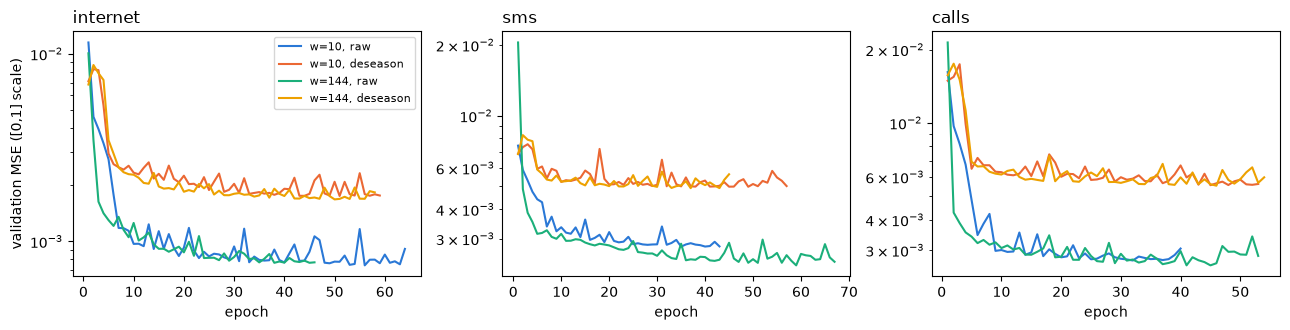

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, s in zip(axes, SERIES):
    for (w, ds), c in zip([(10, False), (10, True), (144, False), (144, True)],
                          ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]):
        hst = np.array(LSTM_RES[(s, w, ds, 1)]["history"])
        ax.plot(np.arange(1, len(hst) + 1), hst[:, 1], color=c, label=f"w={w}, {'deseason' if ds else 'raw'}")
    ax.set_yscale("log"); ax.set_title(s, loc="left"); ax.set_xlabel("epoch")
axes[0].set_ylabel("validation MSE ([0,1] scale)"); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

In [22]:
# Best validation RMSE converted back to the original units, so raw and deseason are comparable
# (with deseasonalisation S_t is added back exactly, so the error of r equals the error of y)
val = {}
for (s, w, ds, h), v in LSTM_RES.items():
    val[(s, h, f"LSTM w={w}" + (" deseason" if ds else ""))] = np.sqrt(min(va for _, va in v["history"])) * v["scale"]
VAL_RMSE = pd.Series(val).unstack().rename_axis(["series", "h"])
display(VAL_RMSE.round(1))

# The LSTM that represents the family in section 5, chosen on the validation set only: the version whose
# validation RMSE is, on average over series and horizons, closest to the best version of that row
LSTM_MAIN = VAL_RMSE.div(VAL_RMSE.min(axis=1), axis=0).mean().idxmin()
print("LSTM chosen on the validation set:", LSTM_MAIN)

LSTM w=10  LSTM w=10 deseason  LSTM w=144  LSTM w=144 deseason
series   h                                                                
calls    1       15.2                13.6        14.9                 13.5
         5       19.3                14.9        16.5                 14.7
internet 1       56.6                55.4        57.5                 54.3
         5       84.1                65.5        78.9                 64.0
sms      1       20.8                18.9        19.0                 18.8
         5       25.5                19.9        21.6                 19.8

LSTM chosen on the validation set: LSTM w=144 deseason


#### Ερμηνεία της εκπαίδευσης

Όλα τα δίκτυα συγκλίνουν, και το early stopping σταματά την εκπαίδευση πολύ πριν από το όριο των εποχών. Το $w = 144$ κοστίζει
πολλές φορές περισσότερο από το $w = 10$ (στήλη `train (s)`), γιατί το backpropagation through time ξετυλίγει το δίκτυο σε 144
βήματα αντί για 10.

Ο δεύτερος πίνακας δίνει το καλύτερο validation RMSE στις αρχικές μονάδες, ώστε raw και από-περιοδικοποιημένη εκδοχή να
συγκρίνονται άμεσα. Από αυτόν επιλέγεται, πριν δούμε το test, η εκδοχή που εκπροσωπεί το LSTM στην ενότητα 5: αυτή που, κατά
μέσο όρο σε όλες τις σειρές και τους ορίζοντες, είναι πιο κοντά στην καλύτερη εκδοχή κάθε γραμμής (το κελί τυπώνει ποια είναι).
Το validation όμως είναι κανονικές ημέρες του Δεκεμβρίου, ενώ το test περιέχει τις γιορτές, οπότε η επιλογή δεν είναι
απαραίτητα η καλύτερη στο test.

Στο test ακολουθούμε τον ψευδοκώδικα του LSTM των Siami-Namini et al.: το δίκτυο εκπαιδεύεται μία φορά στο train, και κάθε
πρόβλεψη παίρνει ως είσοδο τις τελευταίες $w$ πραγματικές τιμές, χωρίς επανεκπαίδευση. Οι αφετηρίες είναι ίδιες με του ARIMA-x.
Διαφέρουμε από το άρθρο στο μέγεθος του δικτύου (εκεί ένα στρώμα με 4 μονάδες), στις εποχές (εκεί μία) και στην είσοδο (εκεί μόνο
η προηγούμενη τιμή). Τα αλλάξαμε γιατί η σειρά μας είναι πολύ μεγαλύτερη, έχει ισχυρό ημερήσιο κύκλο, και η εκφώνηση ζητά ιστορικό
παράθυρο $w$. Όπως και στο άρθρο, κάθε δίκτυο εκπαιδεύεται μία φορά με σταθερό seed, οπότε μικρές διαφορές ανάμεσα στις εκδοχές
μπορεί να οφείλονται και στην τυχαία αρχικοποίηση. Οι προβλέψεις αποτιμώνται αργότερα.

## 4. Foundation model: TimesFM 3.0

### 4.1 Θεωρία

Τα ARIMA και LSTM ξέρουν μόνο ό,τι έμαθαν από το train. Ένα foundation model ακολουθεί τη λογική των LLMs:
ένα μεγάλο transformer εκπαιδεύεται μία φορά σε τεράστιο όγκο χρονοσειρών από πολλά πεδία και μαθαίνει γενικά μοτίβα,
όπως επίπεδα, τάσεις, περιοδικότητες και αιχμές.

Το χρησιμοποιούμε με δύο τρόπους. Στο zero-shot δεν εκπαιδεύεται καθόλου στα δεδομένα μας: του δίνουμε το ιστορικό ως
context, όπως ένα prompt, και το συνεχίζει. Στο fine-tuning συνεχίζουμε την εκπαίδευση με μικρό learning rate σε δικά μας
δεδομένα.

| | ARIMA / LSTM | Foundation model |
|:---|:---|:---|
| Γνώση | μόνο από τη συγκεκριμένη σειρά | από πολλές σειρές, μεταφέρεται (*transfer learning*) |
| Εκπαίδευση στα δεδομένα μας | απαραίτητη | προαιρετική (zero-shot ή fine-tuning) |
| Παράμετροι | από μερικές έως περίπου 50 χιλιάδες | εκατοντάδες εκατομμύρια |
| Κόστος | στην εκπαίδευση (το ARIMA-x και σε κάθε πρόβλεψη, γιατί ξαναεκτιμάται) | κυρίως στο inference |

Το TimesFM (Google Research, Das et al., ICML 2024) είναι decoder-only transformer, όπως τα GPT:

* Η σειρά κόβεται σε κομμάτια (patches) των 32 σημείων, και κάθε κομμάτι παίζει τον ρόλο ενός token. Έτσι 1024 τιμές γίνονται
  32 tokens.
* Κάθε context κανονικοποιείται με τον δικό του μέσο και τυπική απόκλιση (RevIN), οπότε Internet και SMS αντιμετωπίζονται
  με τον ίδιο τρόπο.
* Η προσοχή (attention) συγκρίνει άμεσα το τρέχον κομμάτι με οποιοδήποτε παλαιότερο, π.χ. την ίδια ώρα πριν από μία
  εβδομάδα, ενώ ένα LSTM πρέπει να το κουβαλήσει στη μνήμη του.
* Η έξοδος είναι πιθανοτική: για κάθε βήμα δίνει τα ποσοστημόρια $0.1, \dots, 0.9$. Ως πρόβλεψη παίρνουμε τη διάμεσο.

Το TimesFM 3.0 έχει περίπου 331 εκατομμύρια παραμέτρους και 20 στρώματα. Προβλέπουμε κάθε σειρά μόνη της, όπως και με τα
άλλα μοντέλα. Τα βάρη του TimesFM 3.0 έχουν άδεια μη εμπορικής χρήσης, και η εμπορική χρήση γίνεται μόνο μέσω του Google Cloud, κάτι που
μετράει αν ένας πάροχος θέλει να το χρησιμοποιήσει. Οι εκδόσεις ως την 2.5 έχουν ανοιχτή άδεια Apache 2.0.


### 4.2 Ρύθμιση των πειραμάτων

Zero-shot. Σε κάθε σημείο $t$ του test δίνουμε ως context τις 1024 πραγματικές τιμές πριν από το $t$ (λίγο πάνω από
μία εβδομάδα) και παίρνουμε πρόβλεψη 5 βημάτων. Τα σημεία είναι ίδια με της ενότητας 2.7, και καμία
προεπεξεργασία δεν χρειάζεται. Όλες οι προβλέψεις του test τρέχουν σε batches των 128, σε CPU.

Fine-tuning. Εκπαιδεύουμε μόνο τα 2 τελευταία από τα 20 στρώματα και το output head, περίπου το 10% του μοντέλου. Με
λίγες χιλιάδες σημεία, ένα πλήρες fine-tuning θα κινδύνευε να «ξεχάσει» όσα έμαθε το μοντέλο. Χρησιμοποιούμε την ίδια
loss με την προεκπαίδευση (pinball loss), AdamW με learning rate $3 \cdot 10^{-5}$, 30 φορές μικρότερο από το LSTM, batch 16 και
έως 1000 βήματα, σε τυχαία παράθυρα του train. Κάθε 20 βήματα μετράμε το validation loss.

Οι τελευταίες 5 ημέρες του train είναι το validation, και κρατάμε τα βάρη με το μικρότερο validation loss. Αν κανένα
βήμα δεν βελτιώσει το zero-shot, μένουν τα αρχικά βάρη.

Για κάθε σειρά αξιολογούμε zero-shot, κάνουμε fine-tuning και αξιολογούμε ξανά. Η εκτέλεση παίρνει περίπου μιάμιση ώρα, οπότε τα
αποτελέσματα αποθηκεύονται στο `results/timesfm_ft1000.pkl`. Για νέα εκτέλεση βάζουμε `RETRAIN_TFM = True`.


In [23]:
TFM_CONTEXT = 1024            # context: the last 1024 values (~7.1 days)
TFM_THREADS = min(32, os.cpu_count())   # the series run one after the other (in parallel they compete for the cores)


def tfm_rolling(fc, y, batch=128):
    """Rolling evaluation: at every test origin t the context is the last TFM_CONTEXT ACTUAL values."""
    origins = np.arange(n_train, N)
    ctx = [y[t - TFM_CONTEXT:t] for t in origins]
    fc.config.per_core_batch_size = batch
    t0 = time.perf_counter()
    outs = list(fc.predict_batch(ctx, horizon=H_LONG, return_quantiles=True))
    seconds = time.perf_counter() - t0
    paths = np.stack([o.forecast for o in outs])               # (n_test, 5): median per lead
    quant = np.stack([o.quantiles for o in outs])              # (n_test, 5, 9): quantiles 0.1 ... 0.9
    return {"h1": paths[:, 0],                                 # lead 1 from every origin
            "H5": paths[origins5 - n_train].ravel(),           # leads 1..5 from every 5th origin
            "q_h1": quant[:, 0], "quantiles": list(fc.config.quantiles),
            "seconds_per_forecast": seconds / len(origins)}


def finetune_tfm(fc, y, steps=1000, lr=3e-5, n_layers=2, batch=16, horizon_ft=16, eval_every=20, seed=SEED):
    """Partial fine-tuning: only the last n_layers transformer layers and the output head are trained."""
    from timesfm3 import TimesFM3Torch
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    m = fc.model
    decode = TimesFM3Torch.decode.__wrapped__                  # decode without @torch.no_grad, so gradients flow
    for p in m.parameters():
        p.requires_grad_(False)
    params = list(m.output_head.parameters())
    for layer in m.transformer_stack.layers[-n_layers:]:
        params += list(layer.parameters())
    for p in params:
        p.requires_grad_(True)
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    q = torch.tensor(m.quantiles, dtype=torch.float32)
    scale = float(np.std(y[:n_train]))                         # loss in units of the train std
    n_val = 5 * SEASON                                         # validation: the last 5 days of the train set
    fit_starts = np.arange(TFM_CONTEXT, n_train - n_val - horizon_ft + 1)
    val_starts = np.linspace(n_train - n_val, n_train - horizon_ft, 48).astype(int)

    def loss_on(starts):
        X = torch.from_numpy(np.stack([y[t - TFM_CONTEXT:t] for t in starts]).astype(np.float32))[:, None, :]
        T = torch.from_numpy(np.stack([y[t:t + horizon_ft] for t in starts]).astype(np.float32))
        out = decode(m, target=X, horizon=horizon_ft)[:, 0]    # (batch, horizon, quantiles)
        e = (T[..., None] - out) / scale
        return torch.maximum(q * e, (q - 1) * e).mean()       # pinball loss over all quantiles

    def val_loss():
        with torch.no_grad():
            return float(np.mean([loss_on(val_starts[i:i + 16]).item() for i in range(0, len(val_starts), 16)]))

    snapshot = lambda: [p.detach().clone() for p in params]
    best, best_state, best_step = val_loss(), snapshot(), 0  # step 0 = the pretrained weights
    log = [(0, np.nan, best)]
    t0 = time.perf_counter()
    for step in range(1, steps + 1):
        loss = loss_on(rng.choice(fit_starts, batch, replace=False))
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(params, 1.0); opt.step()
        if step % eval_every == 0:
            v = val_loss()
            log.append((step, loss.item(), v))
            if v < best:                                       # early stopping: keep the best weights
                best, best_state, best_step = v, snapshot(), step
    with torch.no_grad():
        for p, b in zip(params, best_state):
            p.copy_(b)
    for p in m.parameters():
        p.requires_grad_(False)
    return {"log": log, "zero_shot_val": log[0][2], "best_val": best, "best_step": best_step,
            "train_seconds": time.perf_counter() - t0, "trainable_params": sum(p.numel() for p in params),
            "total_params": sum(p.numel() for p in m.parameters())}


def run_timesfm(s):
    from timesfm3 import TimesFM3Forecaster
    torch.set_num_threads(TFM_THREADS)
    fc = TimesFM3Forecaster.from_pretrained(device="cpu")      # fresh pretrained weights for every series
    out = {"zero": tfm_rolling(fc, Y[s])}
    out["ft_info"] = finetune_tfm(fc, Y[s])
    out["ft"] = tfm_rolling(fc, Y[s])
    return out

In [24]:
RETRAIN_TFM = False
TFM_FILE = "results/timesfm_ft1000.pkl"            # fine-tuning with up to 1000 steps

if RETRAIN_TFM or not os.path.exists(TFM_FILE):
    t0 = time.perf_counter()
    TFM_RES = {s: run_timesfm(s) for s in SERIES}              # series one after the other, all threads each
    joblib.dump(TFM_RES, TFM_FILE)
    print(f"TimesFM: 3 series in {time.perf_counter() - t0:.0f}s")
else:
    TFM_RES = joblib.load(TFM_FILE)
    print("loaded", TFM_FILE)

pd.DataFrame([{"series": s, "trainable params": v["ft_info"]["trainable_params"],
               "total params": v["ft_info"]["total_params"],
               "val loss zero-shot": v["ft_info"]["zero_shot_val"], "val loss fine-tuned": v["ft_info"]["best_val"],
               "val change %": 100 * (v["ft_info"]["best_val"] / v["ft_info"]["zero_shot_val"] - 1),
               "best step": v["ft_info"]["best_step"], "fine-tune (s)": round(v["ft_info"]["train_seconds"]),
               "ms / forecast": 1000 * v["zero"]["seconds_per_forecast"]}
              for s, v in TFM_RES.items()]).set_index("series").round(4)

TimesFM: 3 series in 5585s


,trainable params,total params,val loss zero-shot,val loss fine-tuned,val change %,best step,fine-tune (s),ms / forecast
series,,,,,,,,
internet,33522176,330710976,0.0924,0.0631,-31.6658,820,1608,46.2256
sms,33522176,330710976,0.0823,0.0709,-13.8362,480,1650,49.1592
calls,33522176,330710976,0.0595,0.0466,-21.7824,860,1634,48.6852


Καμπύλες fine-tuning. Το validation loss κάθε 20 βήματα, ως λόγος προς το zero-shot (βήμα 0). Τιμή κάτω από 1
σημαίνει ότι το fine-tuning βελτίωσε το μοντέλο στις τελευταίες 5 ημέρες του train.

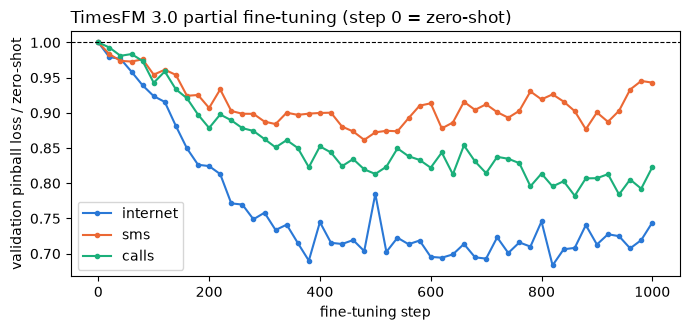

In [25]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for s, c in zip(SERIES, ["#2a78d6", "#eb6834", "#1baf7a"]):
    lg = np.array(TFM_RES[s]["ft_info"]["log"])
    ax.plot(lg[:, 0], lg[:, 2] / lg[0, 2], color=c, marker="o", ms=3, label=s)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xlabel("fine-tuning step"); ax.set_ylabel("validation pinball loss / zero-shot")
ax.set_title("TimesFM 3.0 partial fine-tuning (step 0 = zero-shot)", loc="left"); ax.legend()
fig.tight_layout(); plt.show()

#### Ερμηνεία του fine-tuning

Εκπαιδεύεται περίπου το 10% του μοντέλου: τα 2 τελευταία στρώματα και το output head.

Το validation loss μειώθηκε σε όλες τις σειρές (πίνακας και γράφημα). Η μείωση αυτή είναι όμως αισιόδοξη εκτίμηση της
πραγματικής βελτίωσης: από όλα τα σημεία ελέγχου (ένα κάθε 20 βήματα) κρατάμε αυτό με το μικρότερο loss στα ίδια 48 παράθυρα
του validation, και αν κανένα δεν είναι καλύτερο μένουν τα αρχικά βάρη. Έτσι η fine-tuned εκδοχή είναι εκ κατασκευής τουλάχιστον
όσο καλή όσο το zero-shot στο validation. Με βάση όσα ξέρουμε πριν από το test, η fine-tuned εκδοχή
είναι λοιπόν η λογική επιλογή. Όπως όμως και με την από-περιοδικοποίηση του LSTM, το validation είναι κανονικές ημέρες του
Δεκεμβρίου, ενώ το test όχι.

Το inference του TimesFM είναι πολύ ακριβότερο από του LSTM (στήλη ms / forecast), αλλά το zero-shot δεν χρειάζεται καμία
εκπαίδευση. Τα κόστη όλων των μοντέλων τα συγκρίνουμε αργότερα.

Οι προβλέψεις αποτιμώνται αργότερα, με τις ίδιες αφετηρίες όπως τα υπόλοιπα μοντέλα.

## 5. Αποτίμηση και σύγκριση: RMSE, MAE, MAPE, MASE

Όλα τα μοντέλα αποτιμώνται στα ίδια σημεία του test. Μαζί τους βάζουμε δύο απλούς κανόνες που ένα μοντέλο πρέπει να νικά:

* Naive (persistence): «η κίνηση θα μείνει όπως είναι τώρα»,
* Seasonal naive: «η κίνηση θα είναι όπως χθες την ίδια ώρα».

Όλες οι εκδοχές κάθε οικογένειας (τα τέσσερα LSTM, TimesFM zero-shot και fine-tuned) εμφανίζονται στον πρώτο πίνακα και στις
συγκρίσεις των ενοτήτων 5.3, 5.4 και 5.6. Στους πίνακες με όλες τις μετρικές, στην κρίση επιτυχίας και στα διαστήματα πρόβλεψης
κάθε οικογένεια εκπροσωπείται από ένα μοντέλο, που επιλέγεται πριν δούμε το test:

* ARIMA: το ARIMA-x, το μόνο της οικογένειας με rolling πρόβλεψη (ενότητα 2.7).
* LSTM: η εκδοχή που στο validation είναι κατά μέσο όρο πιο κοντά στην καλύτερη, σε όλες τις σειρές και τους ορίζοντες (ενότητα 3.5).
* TimesFM: η fine-tuned εκδοχή, που στο validation είναι εκ κατασκευής τουλάχιστον όσο καλή όσο το zero-shot (ενότητα 4.2).

Το validation όμως είναι κανονικές ημέρες, ενώ το test περιέχει τις γιορτές, οπότε ο εκπρόσωπος δεν είναι απαραίτητα η
καλύτερη εκδοχή στο test. Αυτό ακριβώς συμβαίνει και για το LSTM και για το TimesFM (ενότητα 5.4).

### 5.1 Ορισμοί και τι μετράει κάθε μετρική

Με $e_t = y_t - \hat y_t$ τα σφάλματα στα $n$ σημεία του test, και $m = 144$:

| Μετρική | Τύπος | Μονάδα | Τι μετράει |
|:---|:---|:---|:---|
| RMSE | $\sqrt{\tfrac1n \sum_t e_t^2}$ | μονάδες της σειράς | τετραγωνικό σφάλμα: τα μεγάλα σφάλματα μετράνε δυσανάλογα. Ελαχιστοποιείται από τη μέση τιμή της κατανομής πρόβλεψης |
| MAE | $\tfrac1n \sum_t \lvert e_t\rvert$ | μονάδες της σειράς | τυπικό μέγεθος σφάλματος, ανθεκτικό σε ακραίες τιμές. Ελαχιστοποιείται από τη διάμεσο |
| MAPE | $\tfrac{100}{n} \sum_t \lvert e_t / y_t\rvert$ | % | μέσο σχετικό σφάλμα ανά σημείο |
| MASE | $\dfrac{\tfrac1n \sum_t \lvert e_t\rvert}{\tfrac{1}{n_{tr}-m} \sum_{t=m+1}^{n_{tr}} \lvert y_t - y_{t-m}\rvert}$ | αδιάστατη | MAE του μοντέλου ως πολλαπλάσιο του MAE της seasonal naive στο train |

Ο λόγος RMSE / MAE δείχνει πόσο «βαριές» είναι οι ουρές των σφαλμάτων: για κανονικά σφάλματα είναι
$\sqrt{\pi/2} \approx 1.25$. Τιμές πάνω από αυτό σημαίνουν ότι λίγα, μεγάλα σφάλματα (οι αιχμές) κυριαρχούν.

#### MASE: γιατί χρησιμοποιείται και τι μας προσφέρει παραπάνω

$$\text{MASE} = \frac{\tfrac1n \sum_t \lvert e_t\rvert}{\tfrac{1}{n_{tr}-144} \sum_{t=145}^{n_{tr}} \lvert y_t - y_{t-144}\rvert}$$

Ο παρονομαστής είναι το σφάλμα του κανόνα «όπως χθες» στο train. Έτσι MASE $= 0.3$ σημαίνει ότι το μοντέλο κάνει το 30% του
σφάλματος αυτού του κανόνα, και κάτω από 1 σημαίνει ότι τον νικά. Τα RMSE, MAE και MAPE δεν λένε από μόνα τους αν μια
τιμή είναι καλή.

Είναι ανεξάρτητη της κλίμακας, οπότε συγκρίνει σειρές μεταξύ τους: ένα MAE 30 είναι εξαιρετικό στο Internet αλλά τεράστιο
στα SMS. Η MAPE το πετυχαίνει διαιρώντας με το $y_t$, και γι' αυτό εκρήγνυται όταν $y_t \to 0$. Η MASE διαιρεί με μία σταθερά,
οπότε δεν έχει αυτό το πρόβλημα. Είναι επίσης συμμετρική, ενώ η MAPE τιμωρεί περισσότερο την υπερεκτίμηση: αν $y_t = 100$, η
πρόβλεψη 300 δίνει 200%, ενώ καμία υποεκτίμηση δεν ξεπερνά το 100%.

Τέλος, είναι ανεξάρτητη από τη σταθερά ανωνυμοποίησης $k$, που απλοποιείται, όπως και στη MAPE αλλά όχι
στις RMSE και MAE. Επιτρέπει έτσι σύγκριση μεταξύ σειρών και οριζόντων με έναν αριθμό, άρα και μέσο όρο πάνω σε όλα
τα κελιά ενός δικτύου.

Ένα λεπτό σημείο: ο παρονομαστής υπολογίζεται στο train, όχι στο test. Γι' αυτό η MASE συγκρίνει το μοντέλο με
μια σταθερή κλίμακα αναφοράς που δεν αλλάζει από μοντέλο σε μοντέλο, και όχι με το πόσο καλά τα πήγε η seasonal
naive στο ίδιο test (εκεί η seasonal naive έχει MASE πάνω από 1). Για το πραγματικό «κατώφλι»
χρήσιμου μοντέλου κοιτάμε επιπλέον τη σύγκριση με το Naive, που εξετάζουμε παρακάτω.

Ο πρώτος πίνακας δίνει τη MASE όλων των μοντέλων. Ο δεύτερος δείχνει τα δύο σημεία αναφοράς και τα τρία βασικά μοντέλα με όλες
τις μετρικές, μαζί με τον λόγο RMSE / MAE. Μετά μετράμε πόσες τιμές του test είναι κοντά στο μηδέν, για να φανεί η συμπεριφορά της MAPE.

In [26]:
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)   # .loc on the unsorted index
warnings.filterwarnings("ignore", message="Mean of empty slice")
MASE_SCALE = {s: np.mean(np.abs(Y[s][SEASON:n_train] - Y[s][:n_train - SEASON])) for s in SERIES}


def metrics(y, yhat, s):
    e = y - yhat
    pos = y > 0                                                # MAPE is undefined where y = 0
    rmse, mae = np.sqrt(np.mean(e ** 2)), np.mean(np.abs(e))
    return {"RMSE": rmse, "MAE": mae, "RMSE / MAE": rmse / mae,
            "MAPE %": 100 * np.mean(np.abs(e[pos] / y[pos])),
            "MASE": mae / MASE_SCALE[s]}


# All forecasts: PRED[(series, horizon)][model] = (test indices, predictions)
PRED = {}
for s in SERIES:
    y = Y[s]
    P1 = {"Naive": (idx1, y[idx1 - 1]), "Seasonal naive": (idx1, y[idx1 - SEASON])}
    P5 = {"Naive": (idx5, np.repeat(y[origins5 - 1], H_LONG)), "Seasonal naive": (idx5, y[idx5 - SEASON])}
    for fam in ARIMA_MODELS:
        P1[fam], P5[fam] = (idx1, ARIMA_ROLL[(s, fam)]["h1"]), (idx5, ARIMA_ROLL[(s, fam)]["H5"])
    for key, name in [("zero", "TimesFM zero-shot"), ("ft", "TimesFM fine-tuned")]:
        P1[name], P5[name] = (idx1, TFM_RES[s][key]["h1"]), (idx5, TFM_RES[s][key]["H5"])
    PRED[(s, 1)], PRED[(s, 5)] = P1, P5
for (s, w, ds, h), v in LSTM_RES.items():
    PRED[(s, h)][f"LSTM w={w}" + (" deseason" if ds else "")] = (idx1 if h == 1 else idx5, v["pred"])
ORDER = ["Naive", "Seasonal naive", *ARIMA_MODELS, "LSTM w=10", "LSTM w=144", "LSTM w=10 deseason", "LSTM w=144 deseason",
         "TimesFM zero-shot", "TimesFM fine-tuned"]

rows = [{"series": s, "h": h, "model": m, **metrics(Y[s][idx], yhat, s)}
        for (s, h), models in PRED.items() for m, (idx, yhat) in models.items()]
FINAL = pd.DataFrame(rows).set_index(["series", "h", "model"])


# The model that represents each family in the comparisons: the version with the lowest validation error
# (sections 3 and 4), chosen before looking at the test set
MAIN = {"ARIMA": "ARIMA-x", "LSTM": LSTM_MAIN, "TimesFM": "TimesFM fine-tuned"}
GROUP_COLOR = {"ARIMA": "#eb6834", "LSTM": "#2a78d6", "TimesFM": "#1baf7a"}

# MASE of every model (lowest per column highlighted)
columns = [(s, h) for s in SERIES for h in (1, 5)]
display(FINAL["MASE"].unstack(["series", "h"])[columns].loc[ORDER].style.format("{:.3f}").highlight_min(color="#d6e6f9"))

# Per series and horizon: the two baselines and the best model of each family, with every metric
show = [(s, h, m) for s, h in columns
        for m in ["Naive", "Seasonal naive", *MAIN.values()]]
display(FINAL.loc[show].style.format({"RMSE": "{:.1f}", "MAE": "{:.1f}", "RMSE / MAE": "{:.2f}", "MAPE %": "{:.1f}", "MASE": "{:.3f}"}))

# Why MAPE misbehaves: how many test values are (close to) zero, and the MAPE on them
for s in SERIES:
    y = Y[s][n_train:]
    m = MAIN["TimesFM"]
    ape = np.abs(y - PRED[(s, 1)][m][1]) / np.where(y > 0, y, np.nan)
    print(f"{s:9s} test values = 0: {np.sum(y == 0):3d}, < 1: {np.sum(y < 1):3d} | MAPE ({m}, h=1): "
          f"on y < 1 {100 * np.nanmean(ape[y < 1]):7.0f}%, on y >= 1 {100 * np.nanmean(ape[y >= 1]):5.1f}%")

internet  test values = 0:   0, < 1:   0 | MAPE (TimesFM fine-tuned, h=1): on y < 1     nan%, on y >= 1   8.0%
sms       test values = 0:   0, < 1:  80 | MAPE (TimesFM fine-tuned, h=1): on y < 1   12812%, on y >= 1  35.0%
calls     test values = 0: 120, < 1: 311 | MAPE (TimesFM fine-tuned, h=1): on y < 1   19039%, on y >= 1  29.9%


### 5.2 Συγκριτικός σχολιασμός των αποτελεσμάτων

Η seasonal naive είναι παντού τελευταία, με MASE πάνω από 1, γιατί ο κανόνας «όπως χθες» αποτυγχάνει στις γιορτές και στη
μετάβαση από εργάσιμη σε Σαββατοκύριακο. Το Naive είναι πολύ πιο δύσκολος αντίπαλος: σε 10 λεπτά η τελευταία τιμή είναι ήδη
καλή πρόβλεψη.

Το TimesFM, και στις δύο εκδοχές του, έχει τη μικρότερη MASE σε όλες τις σειρές και στους δύο ορίζοντες. Πρώτο είναι το
zero-shot και δεύτερο το fine-tuned. Το προβάδισμά του μεγαλώνει από το $h = 1$ στο $H = 5$, όπου η τελευταία τιμή χάνει
γρηγορότερα την αξία της. Η δυσκολία ανά σειρά είναι ίδια σε όλα τα μοντέλα:
Internet < Calls < SMS (στήλη MASE).

Ο λόγος RMSE / MAE είναι περίπου 1.25 για κανονικά σφάλματα. Είναι λίγο πάνω από αυτή την τιμή στο Internet (περίπου 1.5) και
στα Calls (περίπου 1.8), και πολύ πάνω στα SMS (από 2 έως σχεδόν 3), γιατί λίγες απότομες αιχμές δίνουν πολύ μεγάλα σφάλματα.
Ένα μοντέλο μπορεί έτσι να έχει μικρότερο MAE από το Naive αλλά μεγαλύτερο RMSE, όπως το ARIMA-x στα SMS: τις περισσότερες
στιγμές είναι λίγο καλύτερο, αλλά στις αιχμές κάνει μεγαλύτερα λάθη.

Η MAPE αποτυγχάνει, όπως αναμενόταν. Δίνει το ίδιο βάρος σε ένα σχετικό σφάλμα τη νύχτα και το μεσημέρι, οπότε μπορεί να
αλλάξει την κατάταξη σε σχέση με τη MASE: στα Calls το ARIMA-x έχει μικρότερη MASE από το Naive αλλά μεγαλύτερη MAPE. Στα SMS και Calls οι τιμές της, εκατοντάδες ή χιλιάδες τοις εκατό, δεν έχουν νόημα: το
test έχει 80 δεκάλεπτα SMS και 311 Calls με $y_t < 1$, όπου η MAPE εκρήγνυται, ενώ στα υπόλοιπα σημεία είναι λογική (έξοδος του
κελιού). Ένα σφάλμα 2 μονάδων στις 4 το πρωί μετράει όσο εκατοντάδες σφάλματα το μεσημέρι. Η MASE δεν έχει αυτό το πρόβλημα,
γιατί διαιρεί με μία σταθερά και όχι με κάθε τιμή χωριστά (ενότητα 5.1).

### 5.3 Σύγκριση ARIMA και LSTM

Οι Siami-Namini et al. βρήκαν ότι το LSTM μείωσε το σφάλμα κατά 84% έως 87% σε σχέση με την ARIMA, σε μηνιαίες οικονομικές
σειρές. Ο πίνακας δείχνει τη διαφορά της MASE κάθε εκδοχής του LSTM από το ARIMA-x (αρνητική τιμή: το LSTM είναι καλύτερο).

In [27]:
# MASE of every LSTM version relative to ARIMA-x, % (negative = LSTM better)
lstm_versions = [m for m in ORDER if m.startswith("LSTM")]
mase = FINAL["MASE"].unstack(["series", "h"])[columns]
display((100 * (mase.loc[lstm_versions] / mase.loc["ARIMA-x"] - 1)).style.format("{:+.1f}")
        .background_gradient(cmap="RdYlGn_r", vmin=-30, vmax=30))

Τα raw LSTM είναι κοντά στο ARIMA-x: λίγο καλύτερα στο Internet (έως περίπου 9% μικρότερη MASE), λίγο χειρότερα στα SMS, και
ίσα ή χειρότερα στα Calls. Οι από-περιοδικοποιημένες εκδοχές, από τις οποίες το validation διάλεξε τον εκπρόσωπο του LSTM, είναι
παντού χειρότερες από το ARIMA-x, κατά 9% έως 38%. Σε κάθε περίπτωση οι διαφορές είναι πολύ μικρότερες από του άρθρου, για
αρκετούς λόγους. Οι σειρές μας είναι κυρίως γραμμικές και περιοδικές,
οπότε το ARIMA-x τις περιγράφει ήδη καλά, και στα 10 λεπτά η τελευταία τιμή είναι από μόνη της πολύ καλή πρόβλεψη. Οι οικονομικές
σειρές του άρθρου έχουν τάσεις και αλλαγές επιπέδου, όπου η ARIMA δυσκολεύεται πολύ περισσότερο. Επίσης το εορταστικό test
δυσκολεύει όλα τα μοντέλα, γιατί κανένα δεν έχει δει Χριστούγεννα.

Δύο ακόμη λόγοι αφορούν τον τρόπο σύγκρισης και ευνοούν το ARIMA-x. Πρώτον, το ARIMA-x ξέρει το ημερολόγιο: οι όροι
Fourier περιγράφουν την ημέρα και την εβδομάδα, και ο δείκτης μη εργάσιμης ημέρας περιλαμβάνει τις αργίες, οπότε ξέρει από πριν
ότι τα Χριστούγεννα είναι αργία. Το raw LSTM βλέπει μόνο τις τελευταίες $w$ τιμές, οπότε καταλαβαίνει ότι η ημέρα είναι
ασυνήθιστη μόνο αφού αρχίσει. Το από-περιοδικοποιημένο LSTM ξέρει κι αυτό το ημερολόγιο μέσω του $S_t$, αλλά το προφίλ του είναι
σταθερό, ενώ στην εορταστική περίοδο ακόμη και οι εργάσιμες δεν μοιάζουν με κανονικές εργάσιμες (ενότητα 5.4). Δεύτερον, το
ARIMA-x ξαναεκτιμάται σε κάθε βήμα του test με όλο το ιστορικό ως εκείνη τη στιγμή, οπότε προσαρμόζεται μέσα στις γιορτές, ενώ
το LSTM εκπαιδεύεται μία φορά και μένει σταθερό, όπως στο άρθρο. Τέλος, κάθε δίκτυο έχει περίπου 50 χιλιάδες παραμέτρους και
μόλις λίγες χιλιάδες σημεία train, χωρίς βελτιστοποίηση των υπερπαραμέτρων, ενώ τα LSTM συνήθως ξεχωρίζουν με πολύ
περισσότερα δεδομένα ή με πολλές σειρές μαζί.

Κανένα μέγεθος παραθύρου δεν είναι παντού καλύτερο (γραμμές $w = 10$ και $w = 144$): για $H = 5$ το $w = 10$ κερδίζει στο
Internet και το $w = 144$ στα Calls, ενώ το $w = 144$ κοστίζει περίπου τετραπλάσιο χρόνο εκπαίδευσης. Οι από-περιοδικοποιημένες εκδοχές εξετάζονται στην επόμενη ενότητα.

### 5.4 Από-περιοδικοποίηση και fine-tuning: κανονικές ημέρες ή γιορτές;

Η από-περιοδικοποίηση και το fine-tuning βελτίωσαν το validation, αλλά όχι το test. Για να φανεί γιατί, χωρίζουμε το test σε κανονικές
ημέρες (17/12 έως 23/12) και εορταστική περίοδο (24/12 έως 01/01).

In [28]:
# MASE on normal days (17/12 - 23/12) and on the holidays (24/12 - 01/01)
cut = df.index.get_loc(pd.Timestamp("2013-12-24"))
rows = []
for s in SERIES:
    for h in (1, 5):
        for m in ORDER[2:]:
            idx, yhat = PRED[(s, h)][m]
            e = np.abs(Y[s][idx] - yhat) / MASE_SCALE[s]
            rows.append({"series": s, "h": h, "model": m,
                         "normal days": e[idx < cut].mean(), "holidays": e[idx >= cut].mean()})
split = pd.DataFrame(rows).set_index(["series", "h", "model"]).unstack(["series", "h"])
display(split.loc[ORDER[2:]].round(3))

# How much wider is the residual r_t = y_t - S_t in the test set than in the part of the train set it was fitted on?
for s in SERIES:
    n_fit = LSTM_RES[(s, 144, True, 1)]["n_fit"]                 # S_t, min and max: the points before the validation set
    S = seasonal_profile(df.index, Y[s], n_fit)
    r = Y[s] - S
    lo, hi = r[:n_fit].min(), r[:n_fit].max()
    z = (r[n_train:] - lo) / (hi - lo)
    print(f"{s:9s} std(r): fit {r[:n_fit].std():6.1f}, test {r[n_train:].std():6.1f} "
          f"(x{r[n_train:].std() / r[:n_fit].std():.1f}); test points outside [0, 1]: {100 * np.mean((z < 0) | (z > 1)):.1f}%")

normal days                                    holidays  \
series                 internet           sms         calls        internet   
h                             1      5      1      5      1      5        1   
model                                                                         
ARIMA-x                   0.298  0.370  0.541  0.605  0.425  0.479    0.295   
LSTM w=10                 0.316  0.439  0.584  0.730  0.465  0.610    0.246   
LSTM w=144                0.308  0.410  0.560  0.688  0.460  0.546    0.251   
LSTM w=10 deseason        0.316  0.401  0.550  0.630  0.443  0.490    0.438   
LSTM w=144 deseason       0.320  0.392  0.550  0.619  0.434  0.478    0.479   
TimesFM zero-shot         0.279  0.345  0.537  0.579  0.403  0.429    0.206   
TimesFM fine-tuned        0.274  0.349  0.540  0.576  0.404  0.428    0.230   

                                                        
series                        sms         calls         
h                        5      1      5      1      5  
model                                                   
ARIMA-x              0.483  0.610  0.816  0.398  0.553  
LSTM w=10            0.358  0.608  0.766  0.376  0.550  
LSTM w=144           0.496  0.642  0.837  0.384  0.523  
LSTM w=10 deseason   0.733  0.717  0.970  0.567  0.683  
LSTM w=144 deseason  0.748  0.720  0.924  0.544  0.657  
TimesFM zero-shot    0.287  0.510  0.648  0.328  0.411  
TimesFM fine-tuned   0.352  0.533  0.698  0.337  0.442

internet  std(r): fit   97.2, test  224.5 (x2.3); test points outside [0, 1]: 4.6%
sms       std(r): fit   21.2, test   73.7 (x3.5); test points outside [0, 1]: 2.2%
calls     std(r): fit   15.7, test   39.8 (x2.5); test points outside [0, 1]: 5.9%


Από-περιοδικοποίηση. Ο πίνακας χωρίζει τη MASE σε κανονικές ημέρες και γιορτές. Στις κανονικές ημέρες οι από-περιοδικοποιημένες
εκδοχές είναι για $H = 5$ οι καλύτερες εκδοχές του LSTM σε όλες τις σειρές, όπως προέβλεπε το validation. Στις γιορτές όμως είναι
πολύ χειρότερες: στο Internet για $H = 5$ η MASE τους είναι μιάμιση έως δύο φορές αυτή των raw εκδοχών. Στις γιορτές το προφίλ $S_t$ περιμένει
κανονικές ημέρες, οπότε κάθε πρόβλεψη ξεκινά από λάθος βάση: το υπόλοιπο $r_t$ έχει στο test πολλαπλάσια τυπική απόκλιση από ό,τι
στο τμήμα του train όπου εκτιμήθηκε το προφίλ, και ένα μέρος του πέφτει έξω από το $[0, 1]$ (έξοδος του κελιού). Το raw LSTM,
αντίθετα, ακολουθεί το πρόσφατο επίπεδο. Η απάντηση στο ερώτημα της εκφώνησης είναι λοιπόν ότι η από-περιοδικοποίηση βοηθά όταν
το μέλλον μοιάζει με το παρελθόν και βλάπτει όταν αλλάζει.

Fine-tuning. Το fine-tuning δεν βελτίωσε το test, παρότι βελτίωσε το validation. Το fine-tuned είναι χειρότερο από το zero-shot
σε όλες τις περιπτώσεις, από περίπου 1% (Calls, $h = 1$) έως 12% (Internet, $H = 5$). Ο πίνακας δείχνει από πού έρχεται η
διαφορά: στις κανονικές ημέρες οι δύο εκδοχές έχουν πρακτικά την ίδια MASE, ενώ στις γιορτές το fine-tuned είναι παντού
χειρότερο, στο Internet για $H = 5$ κατά περίπου ένα τέταρτο, γιατί προσαρμόστηκε στο μοτίβο των κανονικών ημερών Νοεμβρίου και
Δεκεμβρίου. Για αυτό το test το zero-shot όχι μόνο αρκεί, αλλά είναι και η καλύτερη επιλογή.

Το TimesFM αντέχει τις γιορτές καλύτερα από τα άλλα μοντέλα (στήλη holidays), γιατί ακολουθεί το επίπεδο της τελευταίας
εβδομάδας, που βρίσκεται μέσα στο context του. Και στις δύο περιπτώσεις η αιτία είναι ίδια: ένα μοντέλο που ταιριάζει καλύτερα
στο παρελθόν δεν προβλέπει απαραίτητα καλύτερα ένα μέλλον που συμπεριφέρεται διαφορετικά (*distribution shift*).

### 5.5 Απεικονίσεις: πραγματική σειρά και προβλέψεις στο test set

Πρώτα ολόκληρο το test με τα τρία βασικά μοντέλα, και μετά μεγεθύνσεις για $H = 5$ σε κανονικές ημέρες και στις γιορτές.


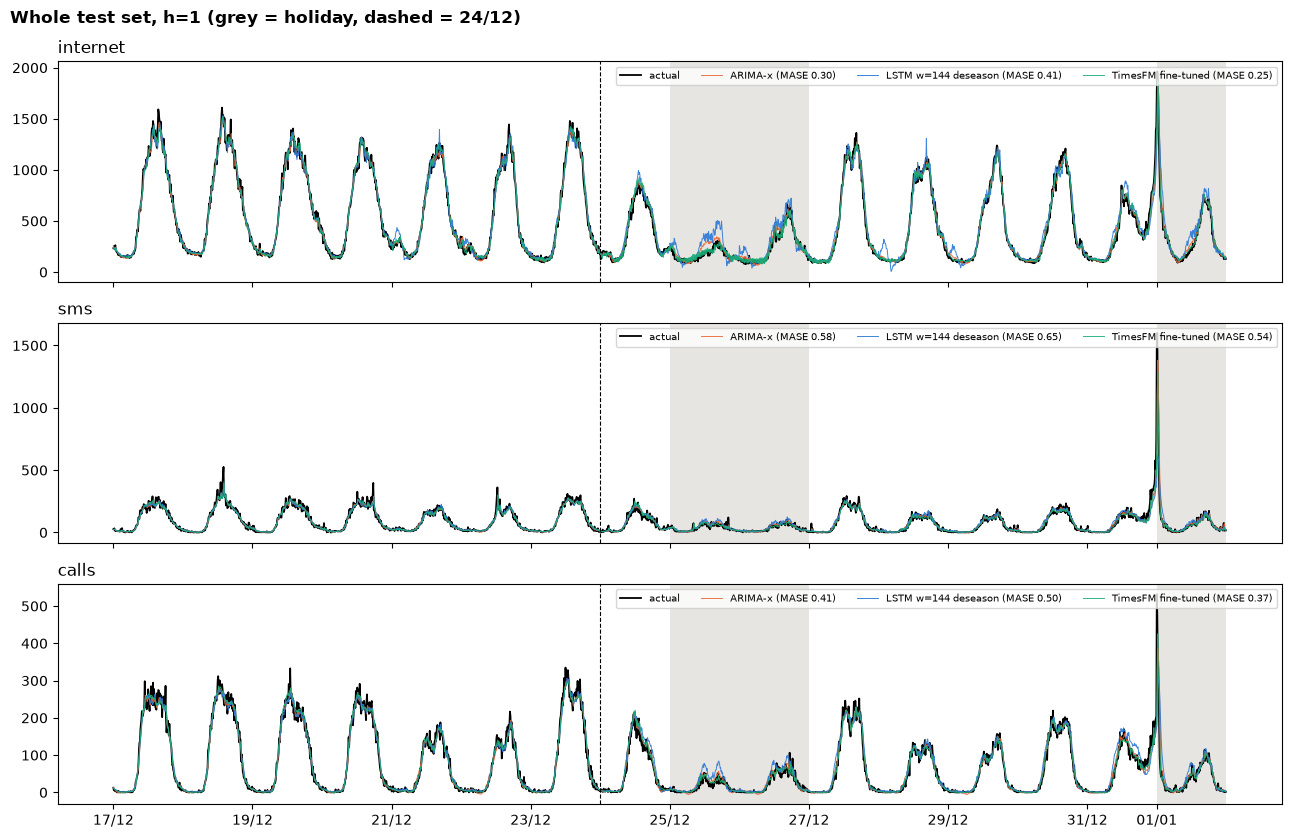

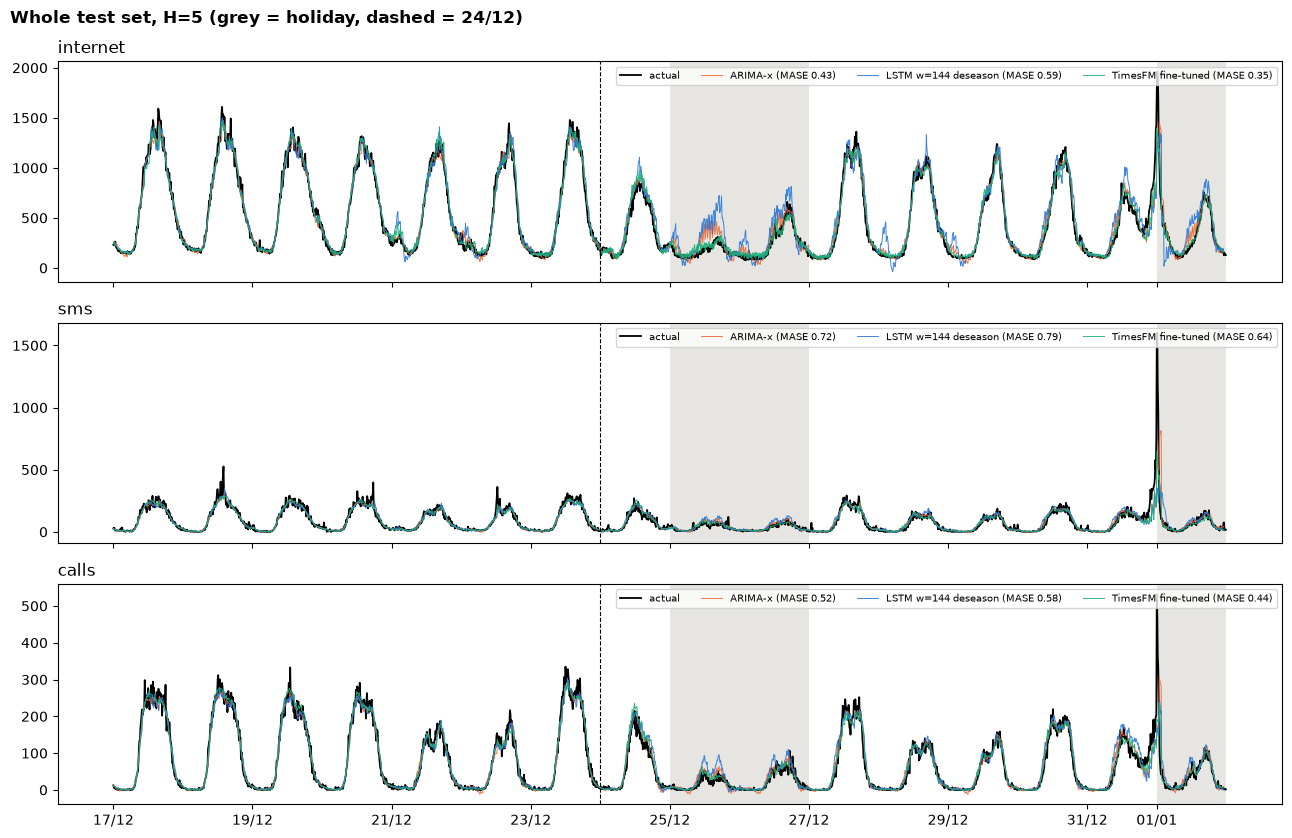

In [29]:
# Whole test set, best model of each family
for h in (1, 5):
    fig, axes = plt.subplots(len(SERIES), 1, figsize=(13, 8.5), sharex=True)
    for ax, s in zip(axes, SERIES):
        ax.plot(df.index[n_train:], Y[s][n_train:], color="k", lw=1.3, label="actual")
        for fam, m in MAIN.items():
            idx, yhat = PRED[(s, h)][m]
            ax.plot(df.index[idx], yhat, color=GROUP_COLOR[fam], lw=0.7, alpha=0.9,
                    label=f"{m} (MASE {FINAL.loc[(s, h, m), 'MASE']:.2f})")
        for d in HOLIDAYS[HOLIDAYS >= df.index[n_train]]:
            ax.axvspan(d, d + pd.Timedelta("1D"), color="#e6e5e1", lw=0)
        ax.axvline(pd.Timestamp("2013-12-24"), color="k", lw=0.8, ls="--")
        ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=4, loc="upper right")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    fig.suptitle(f"Whole test set, {'h=1' if h == 1 else 'H=5'} (grey = holiday, dashed = 24/12)",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

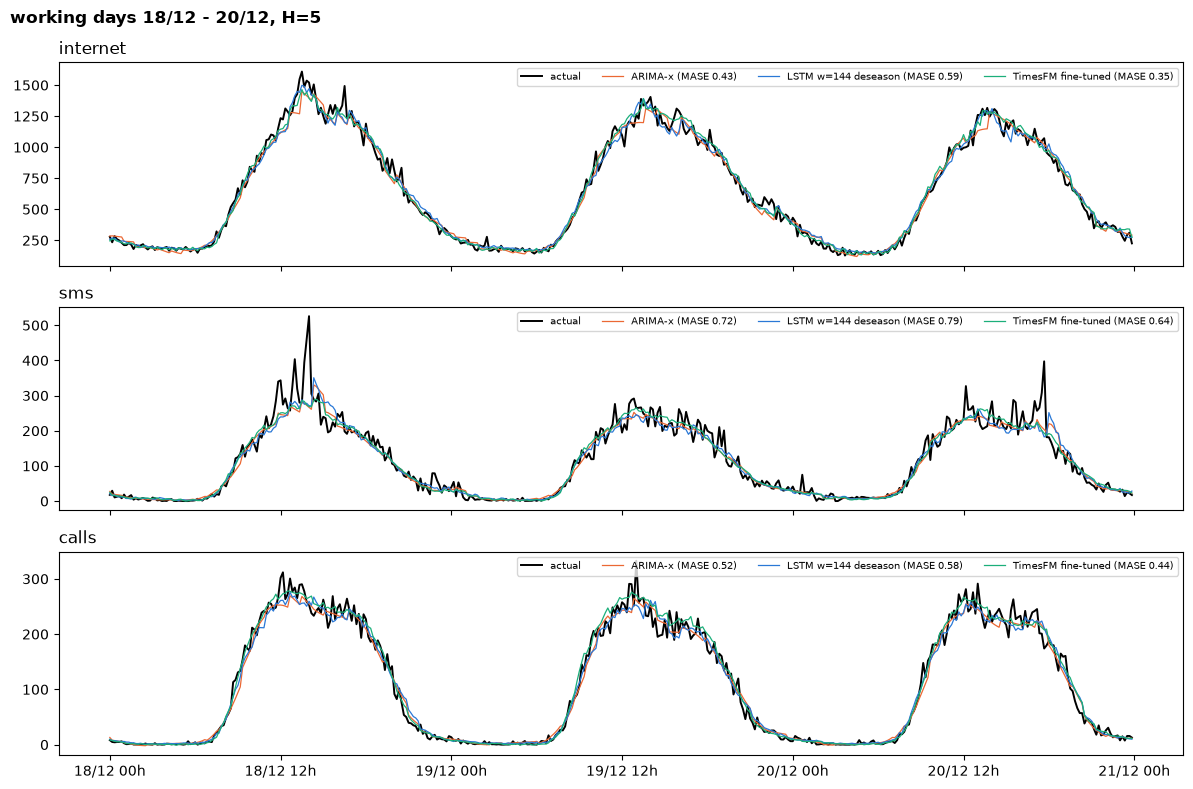

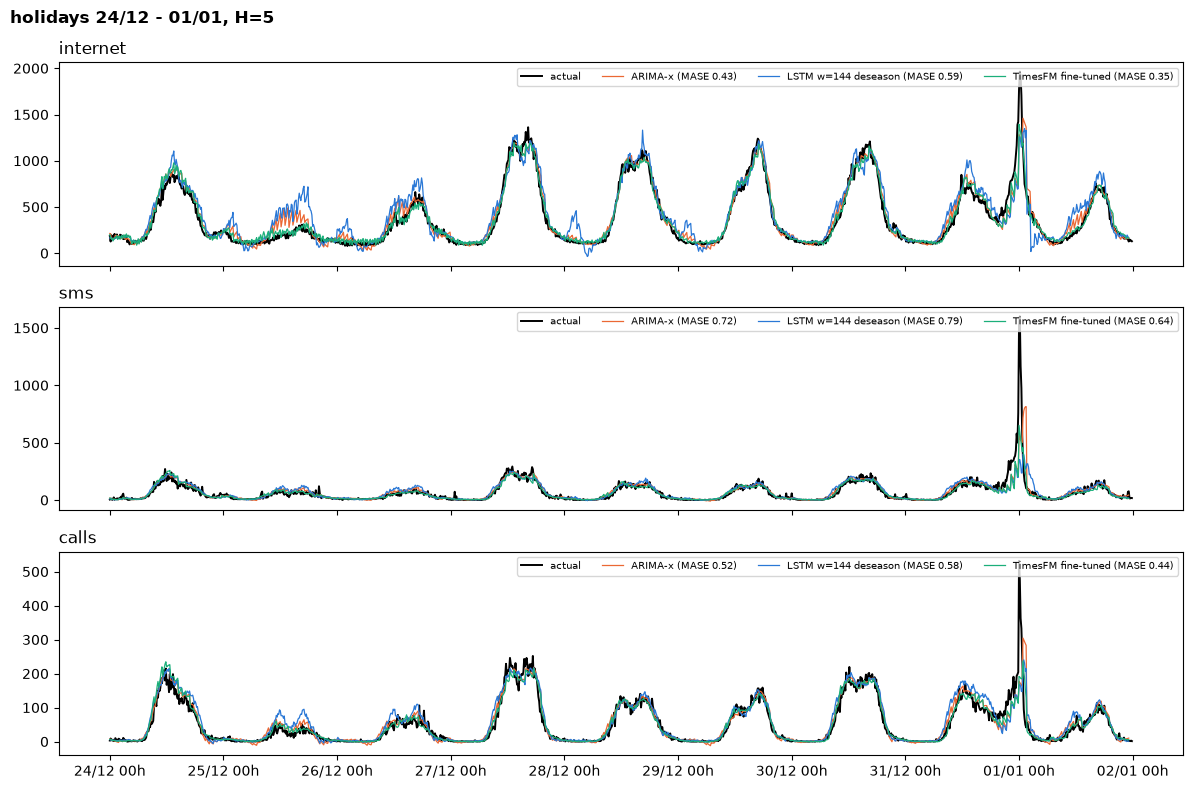

In [30]:
# Close-ups (H=5): the three main models on normal working days and on the holidays
for period, title in [(slice("2013-12-18", "2013-12-20"), "working days 18/12 - 20/12"),
                      (slice("2013-12-24", "2014-01-01"), "holidays 24/12 - 01/01")]:
    fig, axes = plt.subplots(len(SERIES), 1, figsize=(12, 8), sharex=True)
    for ax, s in zip(axes, SERIES):
        act_ = df[s].loc[period]
        ax.plot(act_.index, act_.values, color="k", lw=1.4, label="actual")
        for grp, m in MAIN.items():
            idx, yhat = PRED[(s, 5)][m]
            ser = pd.Series(yhat, index=df.index[idx]).loc[period]
            ax.plot(ser.index, ser.values, color=GROUP_COLOR[grp], lw=0.9,
                    label=f"{m} (MASE {FINAL.loc[(s, 5, m), 'MASE']:.2f})")
        ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=4, loc="upper right")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
    fig.suptitle(f"{title}, H=5", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()


#### Τι δείχνουν οι απεικονίσεις

Όλα τα μοντέλα πιάνουν πολύ καλά το ημερήσιο σχήμα. Στις κανονικές ημέρες οι προβλέψεις σχεδόν καλύπτουν την πραγματική
σειρά, και οι διαφορές των μετρικών αφορούν το ύψος της κορυφής και τις απότομες μεταβολές. Τη νύχτα το σφάλμα είναι πολύ
μικρό, και τα μεγάλα σφάλματα εμφανίζονται στις ώρες κίνησης, όπου ένα λάθος προκαλεί συμφόρηση.

Τις αιχμές δεν τις προβλέπει κανένα μοντέλο. Η Πρωτοχρονιά (Internet περίπου 2000, SMS περίπου 1600, Calls περίπου 500)
υποεκτιμάται από όλα και πιάνεται μόνο μερικώς, με καθυστέρηση: μια αιχμή χωρίς προηγούμενο εμφανίζεται στην πρόβλεψη ένα
βήμα αργότερα (*lag effect*).

Στις γιορτές τα μοντέλα του train περιμένουν κανονική ημέρα και υπερεκτιμούν, ενώ το TimesFM προσαρμόζεται πιο γρήγορα στο
χαμηλό επίπεδο.

### 5.6 Πότε το forecasting «έχει επιτύχει»;

Μία τιμή μετρικής από μόνη της δεν λέει αν η πρόβλεψη πέτυχε. Χρειάζεται σύγκριση με κάτι. Προτείνουμε τρία κριτήρια:

1. MASE $< 1$. Είναι πολύ χαλαρό: εδώ το περνούν όλα εκτός από τη seasonal naive, ακόμη και το Naive, γιατί σε 10 λεπτά η
   τελευταία τιμή είναι πολύ καλύτερη πρόβλεψη από την τιμή χθες.
2. Βελτίωση έναντι του Naive. Αυτό είναι το πραγματικό κατώφλι, γιατί το Naive δεν κοστίζει τίποτα. Μιλάμε για επιτυχία αν το
   MAE είναι τουλάχιστον 10% μικρότερο από του Naive, για οριακή βελτίωση από 0% έως 10%, και για αποτυχία αν δεν υπάρχει
   βελτίωση. Το όριο του 10% είναι επιλογή μας.
3. Τηλεπικοινωνιακό κριτήριο. Το σφάλμα πρέπει να είναι μικρό σε σχέση με το περιθώριο χωρητικότητας (headroom) που κρατά ο
   πάροχος, συνήθως 15% έως 30% πάνω από την αναμενόμενη ζήτηση. Αυτό το κρίνουμε συγκρίνοντας το MAE με το μέγεθος της κίνησης
   και με τα διαστήματα πρόβλεψης που εξετάζουμε στη συνέχεια.

Ο πρώτος πίνακας δίνει τη βελτίωση κάθε μοντέλου έναντι του Naive και ο δεύτερος εφαρμόζει το κριτήριο 2 στα τρία βασικά μοντέλα.


In [31]:
# Improvement over the persistence (Naive) forecast, % of its MAE (positive = better than Naive)
gain = {}
for (s, h, m), v in FINAL["MASE"].items():
    if m not in ("Naive", "Seasonal naive"):
        gain[(m, s, h)] = 100 * (1 - v / FINAL.loc[(s, h, "Naive"), "MASE"])
gain = pd.Series(gain).unstack([1, 2])[columns].loc[ORDER[2:]]
display(gain.style.format("{:+.1f}").background_gradient(cmap="RdYlGn", vmin=-30, vmax=30))


def verdict(g):
    return "fail" if g <= 0 else ("success" if g >= 10 else "marginal")


pd.DataFrame({(s, h): {m: f"{verdict(gain.loc[m, (s, h)])} ({gain.loc[m, (s, h)]:+.1f}%)" for m in MAIN.values()}
              for s, h in columns})


internet                                 sms  \
                                    1                 5                 1   
ARIMA-x              marginal (+1.9%)  marginal (+9.6%)  marginal (+3.6%)   
LSTM w=144 deseason     fail (-35.6%)     fail (-23.4%)      fail (-7.4%)   
TimesFM fine-tuned   success (+17.5%)  success (+26.9%)  success (+10.8%)   

                                                  calls                    
                                    5                 1                 5  
ARIMA-x              marginal (+4.7%)  marginal (+6.4%)  success (+13.1%)  
LSTM w=144 deseason      fail (-4.1%)     fail (-13.2%)  marginal (+3.4%)  
TimesFM fine-tuned   success (+15.1%)  success (+16.4%)  success (+27.2%)

#### Αποτίμηση ανά περίπτωση

Το TimesFM πετυχαίνει σε όλες τις περιπτώσεις, με βελτίωση έναντι του Naive που μεγαλώνει από το $h = 1$ στο $H = 5$. Το
ARIMA-x είναι οριακό παντού εκτός από τα Calls για $H = 5$, όπου πετυχαίνει. Η εκδοχή του LSTM που διάλεξε το validation
αποτυγχάνει παντού εκτός από τα Calls για $H = 5$, όπου είναι οριακή. Οι raw εκδοχές του LSTM τα πάνε καλύτερα (το $w = 10$
πετυχαίνει στο Internet για $H = 5$, πρώτος πίνακας), αλλά αυτό το βλέπουμε μόνο εκ των υστέρων. Στο short-term είναι δύσκολο
να ξεπεράσει κανείς το οριακό, γιατί σε 10 λεπτά η persistence είναι πολύ δυνατή. Τα SMS είναι η πιο δύσκολη σειρά, λόγω των απρόβλεπτων αιχμών.

Με το κριτήριο 3, στο Internet το TimesFM έχει MAPE περίπου 8% για $h = 1$ και 12% για $H = 5$, κάτω από ένα τυπικό
headroom. Εδώ η MAPE είναι αξιόπιστη, γιατί η κίνηση του Internet δεν πλησιάζει ποτέ το μηδέν. Στα SMS και Calls η MAPE δεν έχει
νόημα (ενότητα 5.2), οπότε το κριτήριο 3 το κρίνουμε από τα διαστήματα πρόβλεψης της επόμενης ενότητας.

### 5.7 Έχουν οι μετρικές φυσική ερμηνεία;

Τα RMSE και MAE εκφράζονται στις μονάδες της σειράς, αλλά οι τιμές του dataset είναι κλιμακωμένες με μια άγνωστη σταθερά
$k$. Επιπλέον το Internet μετρά CDRs και όχι bytes, οπότε ένα MAE 29 δεν είναι 29 MB. Ερμηνεύονται μόνο σχετικά: MAE 29 όταν η κορυφή της ημέρας είναι 1200 έως 1600 είναι περίπου
2% της κορυφής.

Η MAPE έχει θεωρητικά ερμηνεία (μέσο σχετικό σφάλμα), αλλά εδώ εκρήγνυται στις νυχτερινές τιμές κοντά στο μηδέν. Η MASE δεν
είναι φυσικό μέγεθος, αλλά σύγκριση με έναν απλό κανόνα, και γι' αυτό είναι η κατάλληλη κύρια μετρική για τη σύγκριση μοντέλων. Η
κάλυψη ενός διαστήματος, που εξετάζουμε στη συνέχεια, έχει επίσης φυσικό νόημα: δείχνει πόσο συχνά η ζήτηση ξεπερνά το όριο που διαστασιολογήσαμε.


### 5.8 Bonus: διαστήματα πρόβλεψης 95% για το short-term

Για τη διαστασιολόγηση πόρων χρειαζόμαστε ένα εύρος που περιέχει τη μελλοντική τιμή με πιθανότητα 95%. (Αυστηρά λέγεται διάστημα
πρόβλεψης, γιατί αφορά μια μελλοντική τιμή και όχι μια παράμετρο.) Το υπολογίζουμε για το ARIMA-x και το TimesFM fine-tuned.

ARIMA-x. Για $h = 1$ το σφάλμα πρόβλεψης είναι ακριβώς το $\varepsilon_{t+1}$. Αν είναι κανονικό, το διάστημα είναι
$\hat y_{t+1} \pm 1.96\, \hat\sigma$, με $\hat\sigma$ από το fit του ίδιου βήματος. Το $\hat\sigma$ αλλάζει ελάχιστα από βήμα σε
βήμα, οπότε το πλάτος είναι πρακτικά ίδιο τη νύχτα και στην κορυφή.

TimesFM. Το μοντέλο δίνει τα ποσοστημόρια $q_{0.1}, \dots, q_{0.9}$, αλλά για το 95% χρειαζόμαστε τα $q_{0.025}$ και $q_{0.975}$. Τα
προσεγγίζουμε θεωρώντας κανονική κατανομή γύρω από τη διάμεσο:

$$\hat\sigma_t = \frac{q_{0.9} - q_{0.1}}{2 \cdot 1.2816}, \qquad q_{0.5} \;\pm\; 1.96 \, \hat\sigma_t$$

Το 1.2816 είναι το ποσοστημόριο 0.9 της τυπικής κανονικής. Εδώ το $\hat\sigma_t$ αλλάζει σε κάθε σημείο, δηλαδή το μοντέλο εκτιμά
διαφορετική αβεβαιότητα για κάθε πρόβλεψη.

Μετράμε την κάλυψη, δηλαδή το ποσοστό των σημείων του test που πέφτουν μέσα στο διάστημα (στόχος περίπου 95%), το μέσο πλάτος
(στενότερο είναι καλύτερο, αν η κάλυψη είναι σωστή) και πόσο συχνά το κάτω όριο είναι αρνητικό.


In [32]:
Z95 = 1.959964                                                 # standard normal 97.5% quantile
PI = {}
for s in SERIES:
    # ARIMA-x: the one-step error is the innovation; sigma from the refit at each test point
    roll = ARIMA_ROLL[(s, "ARIMA-x")]
    PI[(s, "ARIMA-x")] = (roll["h1"] - Z95 * roll["sigma_h1"], roll["h1"] + Z95 * roll["sigma_h1"])

    # TimesFM: Gaussian approximation around the median, sigma from the 10%-90% quantile spread
    t = TFM_RES[s]["ft"]
    qs = list(np.round(t["quantiles"], 3))
    q10, q50, q90 = (t["q_h1"][:, qs.index(q)] for q in (0.1, 0.5, 0.9))
    sig = (q90 - q10) / (2 * 1.281552)
    PI[(s, "TimesFM fine-tuned")] = (q50 - Z95 * sig, q50 + Z95 * sig)

rows = []
for (s, m), (lo, hi) in PI.items():
    y = Y[s][idx1]
    inside = (y >= lo) & (y <= hi)
    rows.append({"series": s, "model": m, "coverage %": 100 * inside.mean(),
                 "normal days %": 100 * inside[idx1 < cut].mean(), "holidays %": 100 * inside[idx1 >= cut].mean(),
                 "below lower %": 100 * np.mean(y < lo), "above upper %": 100 * np.mean(y > hi),
                 "mean width / MASE scale": np.mean(hi - lo) / MASE_SCALE[s],
                 "lower bound < 0 %": 100 * np.mean(lo < 0)})
COVERAGE = pd.DataFrame(rows).set_index(["series", "model"])
COVERAGE.round(2)


coverage %  normal days %  holidays %  \
series   model                                                       
internet ARIMA-x                  97.61          97.72       97.53   
         TimesFM fine-tuned       93.36          94.25       92.67   
sms      ARIMA-x                  92.49          91.27       93.44   
         TimesFM fine-tuned       91.32          92.26       90.59   
calls    ARIMA-x                  92.75          90.87       94.21   
         TimesFM fine-tuned       95.01          95.83       94.37   

                             below lower %  above upper %  \
series   model                                              
internet ARIMA-x                      0.87           1.52   
         TimesFM fine-tuned           3.08           3.56   
sms      ARIMA-x                      2.60           4.90   
         TimesFM fine-tuned           1.78           6.90   
calls    ARIMA-x                      2.99           4.25   
         TimesFM fine-tuned           1.56           3.43   

                             mean width / MASE scale  lower bound < 0 %  
series   model                                                           
internet ARIMA-x                                2.08              11.94  
         TimesFM fine-tuned                     1.20               0.00  
sms      ARIMA-x                                2.91              45.70  
         TimesFM fine-tuned                     2.19              17.32  
calls    ARIMA-x                                2.29              47.09  
         TimesFM fine-tuned                     1.79              39.06

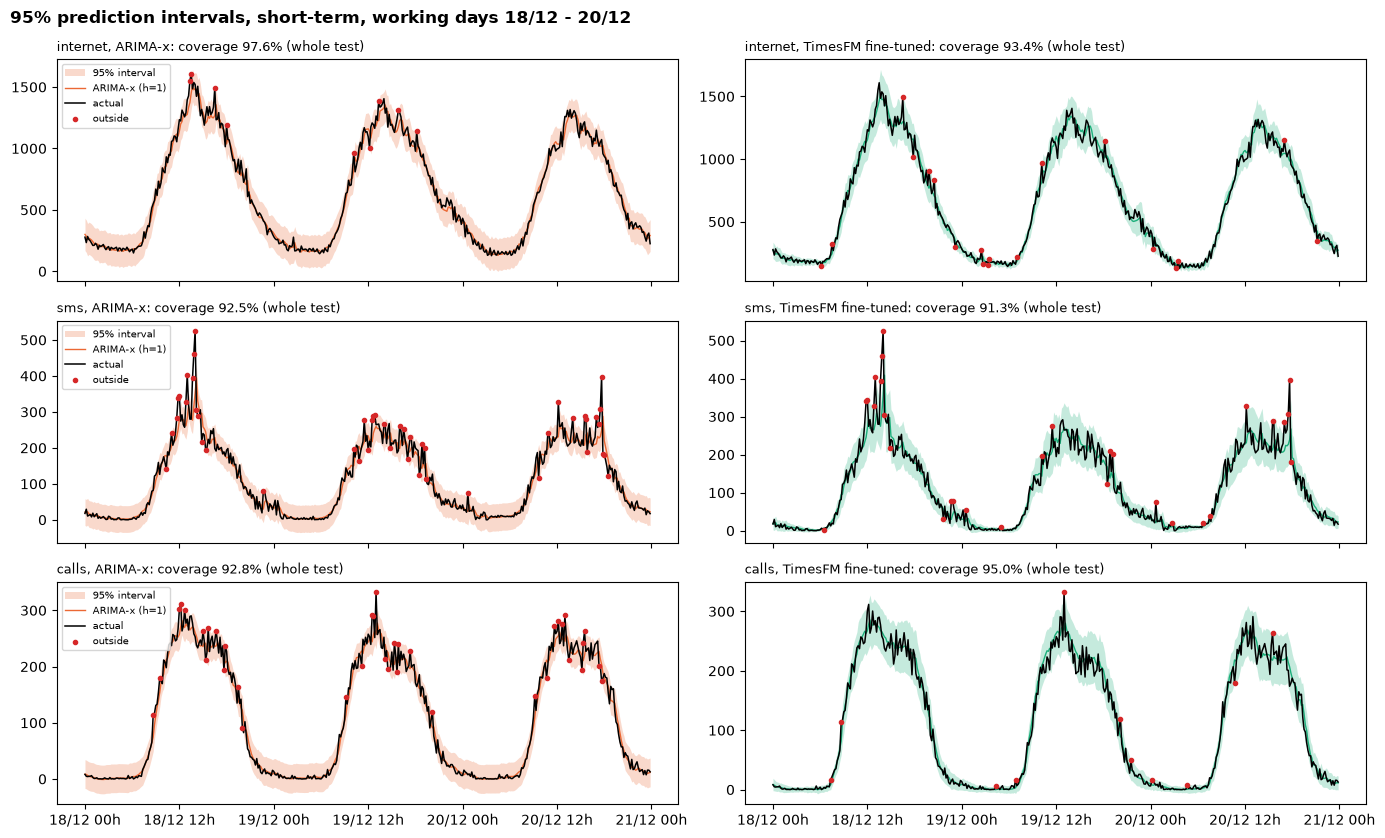

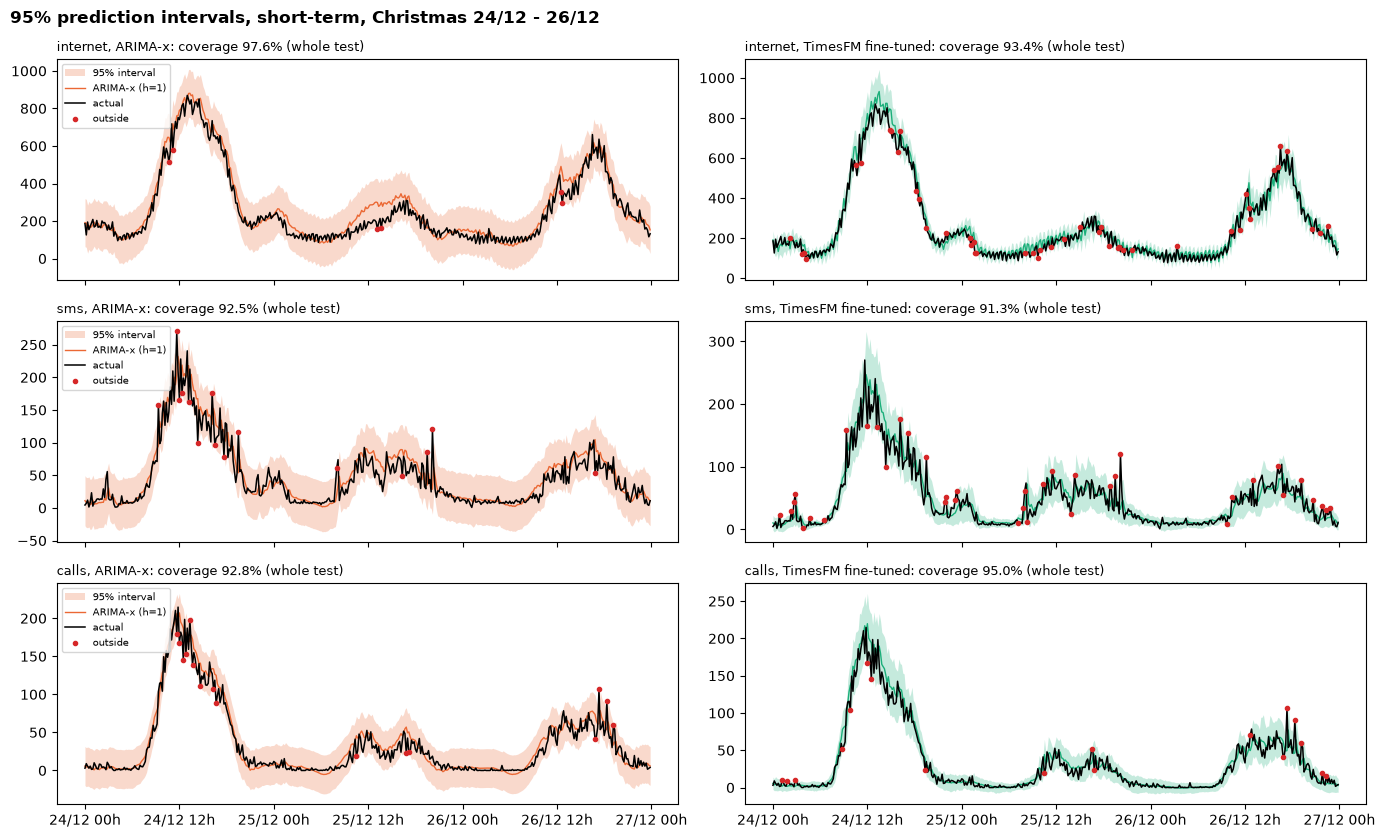

In [33]:
for period, title in [(slice("2013-12-18", "2013-12-20"), "working days 18/12 - 20/12"),
                      (slice("2013-12-24", "2013-12-26"), "Christmas 24/12 - 26/12")]:
    fig, axes = plt.subplots(len(SERIES), 2, figsize=(14, 8.5), sharex=True)
    tt = df.index[idx1]
    sel = (tt >= pd.Timestamp(period.start)) & (tt < pd.Timestamp(period.stop) + pd.Timedelta("1D"))
    for i, s in enumerate(SERIES):
        for ax, m, c in [(axes[i, 0], "ARIMA-x", GROUP_COLOR["ARIMA"]),
                         (axes[i, 1], "TimesFM fine-tuned", GROUP_COLOR["TimesFM"])]:
            lo, hi = PI[(s, m)]
            ax.fill_between(tt[sel], lo[sel], hi[sel], color=c, alpha=0.25, lw=0, label="95% interval")
            ax.plot(tt[sel], PRED[(s, 1)][m][1][sel], color=c, lw=1, label=f"{m} (h=1)")
            ax.plot(tt[sel], Y[s][idx1][sel], color="k", lw=1.1, label="actual")
            out = sel & ((Y[s][idx1] < lo) | (Y[s][idx1] > hi))
            ax.scatter(tt[out], Y[s][idx1][out], color="#d62728", s=9, zorder=3, label="outside")
            ax.set_title(f"{s}, {m}: coverage {COVERAGE.loc[(s, m), 'coverage %']:.1f}% (whole test)",
                         loc="left", fontsize=9.5)
        axes[i, 0].legend(fontsize=7, loc="upper left")
    for ax in axes[-1]:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
    fig.suptitle(f"95% prediction intervals, short-term, {title}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

#### Ερμηνεία των διαστημάτων

Ο πίνακας δίνει την κάλυψη, το μέσο πλάτος (ως πολλαπλάσιο της κλίμακας της MASE, ώστε να συγκρίνονται οι σειρές) και πόσο συχνά
το κάτω όριο είναι αρνητικό.

Το πλάτος του ARIMA-x είναι πρακτικά σταθερό, γιατί το $\hat\sigma$ είναι ένα για όλη την ημέρα. Τη νύχτα το διάστημα είναι
υπερβολικά φαρδύ και συχνά πηγαίνει κάτω από το μηδέν (στήλη `lower bound < 0 %`), και στην κορυφή είναι πολύ στενό. Είναι η
συνέπεια της ετεροσκεδαστικότητας που βρήκαμε στα κατάλοιπα (ενότητα 2.6).

Το ARIMA-x υπερκαλύπτει στο Internet (περίπου 98%) και υποκαλύπτει στα SMS και Calls (περίπου 92% έως 93%).

Τα διαστήματα του TimesFM προσαρμόζονται: είναι στενά τη νύχτα και φαρδύτερα στην κορυφή. Η κάλυψή τους είναι σωστή στα Calls
(95%) και λίγο χαμηλή στο Internet (93%) και στα SMS (91%), με πλάτος 20% έως 40% μικρότερο από του ARIMA-x. Και στα δύο
μοντέλα τα σημεία εκτός είναι συχνότερα πάνω από το διάστημα παρά κάτω (στήλες `below lower %` και `above upper %`), ιδίως
στα SMS, γιατί τις ανοδικές αιχμές δεν τις προβλέπει κανείς. Εξαίρεση είναι το TimesFM στο Internet, όπου οι δύο πλευρές είναι
περίπου ισόποσες. Το αρνητικό κάτω όριο στην πράξη κόβεται στο 0.

Η κάλυψη δεν πέφτει ουσιαστικά στις γιορτές, γιατί για $h = 1$ η πρόβλεψη βασίζεται κυρίως στην τελευταία πραγματική τιμή.

Τηλεπικοινωνιακά, το άνω όριο είναι αυτό που χρειάζεται για τη διαστασιολόγηση: αν δεσμεύουμε χωρητικότητα ίση με το $q_{0.975}$, η
ζήτηση την ξεπερνά περίπου στο 2.5% των δεκαλέπτων. Ένα πολύ φαρδύ διάστημα σπαταλά πόρους και ενέργεια, ιδίως τη νύχτα, και ένα
πολύ στενό οδηγεί σε συμφόρηση τη στιγμή που μετράει. Όπου η κάλυψη μένει κάτω από 95%, μπορεί να διορθωθεί με conformal
prediction, που ρυθμίζει το πλάτος με βάση τα πρόσφατα σφάλματα.

## 6. Τηλεπικοινωνιακή σημασία, ενορχήστρωση σε 6G και χρόνοι inference

### 6.1 Η τηλεπικοινωνιακή σημασία των αποτελεσμάτων

Internet. Με σχετικό σφάλμα του TimesFM περίπου 8% για $h = 1$ και 12% για $H = 5$ (MAPE, ενότητα 5.1), ο πάροχος ξέρει 10 έως 50 λεπτά πριν από την αιχμή πόση χωρητικότητα θα χρειαστεί,
με σφάλμα μικρότερο από ένα τυπικό περιθώριο. Μπορεί έτσι να ενεργοποιήσει carriers ή small cells και να κλιμακώσει UPF και CU-UP
πριν φτάσει η αιχμή.

Νύχτα. Η κίνηση είναι χαμηλή και το σφάλμα πολύ μικρό, οπότε ο εξοπλισμός μπορεί να απενεργοποιηθεί με ασφάλεια για εξοικονόμηση
ενέργειας, που είναι βασικός στόχος του 6G.

Calls. Η φωνή είναι ευαίσθητη σε καθυστέρηση και χρειάζεται εγγυημένο ρυθμό. Με καλή πρόβλεψη του ημερήσιου προφίλ οι πόροι της δεσμεύονται
δυναμικά, αντί να κρατούνται μόνιμα για τη χειρότερη περίπτωση.

SMS και αιχμές. Τα SMS φορτώνουν κυρίως το control plane. Στην Πρωτοχρονιά έφτασαν περίπου 70 φορές το κανονικό σε 10 λεπτά, κάτι που δεν
προβλέπεται από το ιστορικό. Για τέτοια γεγονότα χρειάζεται ημερολόγιο εκδηλώσεων και περιθώριο ασφαλείας.

Γιορτές. Ένα μοντέλο εκπαιδευμένο σε κανονικές ημέρες υπερεκτιμά τα Χριστούγεννα, που σημαίνει σπατάλη πόρων. Ο ίδιος μηχανισμός σε μια
ασυνήθιστα υψηλή ημέρα θα σήμαινε συμφόρηση, οπότε τα μοντέλα πρέπει να παρακολουθούνται συνεχώς.

Zero-shot. Το TimesFM χωρίς καμία εκπαίδευση στα δεδομένα μας ήταν μάλιστα καλύτερο από το fine-tuned (ενότητα 5.4), οπότε το
καλύτερο μοντέλο δεν χρειάζεται εκπαίδευση ανά κυψέλη. Αυτό απλοποιεί πολύ τη λειτουργία σε δίκτυο με χιλιάδες κυψέλες
και καλύπτει και νέες κυψέλες χωρίς μεγάλο ιστορικό.

Διαστήματα. Η υποεκτίμηση (συμφόρηση, παραβίαση SLA) κοστίζει συνήθως πολύ περισσότερο από την υπερεκτίμηση (ενέργεια, δεσμευμένοι πόροι).
Γι' αυτό η διαστασιολόγηση πρέπει να γίνεται με ένα άνω όριο της πρόβλεψης και όχι με τη σημειακή τιμή.

### 6.2 Ενορχήστρωση σε πραγματικό δίκτυο 6G πραγματικού χρόνου

Ο κλειστός βρόχος ακολουθεί το ETSI ZSM και την αρχιτεκτονική O-RAN, όπου η «ευφυΐα» του RAN βρίσκεται σε δύο ελεγκτές: τον Non-RT RIC, με
βρόχους πάνω από 1 s και εφαρμογές που λέγονται rApps, και τον Near-RT RIC, με βρόχους από 10 ms έως 1 s και εφαρμογές που λέγονται xApps.

1. Monitor. Οι μετρήσεις φορτίου κάθε κυψέλης ρέουν από τους σταθμούς βάσης (διεπαφές E2 και O1) και αποθηκεύονται σε βάση χρονοσειρών.
2. Analyze. Ένα forecasting rApp στον Non-RT RIC τρέχει σε κάθε νέο δεκάλεπτο και βγάζει για κάθε κυψέλη πρόβλεψη με ποσοστημόρια. Είναι
   ακριβώς το rolling-window σχήμα του notebook.
3. Decide. Η χωρητικότητα ορίζεται από ένα άνω ποσοστημόριο, $C_{t+h} = \hat q_\tau(y_{t+h})$. Το $\tau$ προκύπτει από το κόστος,
   $\tau^* = c_{\text{under}} / (c_{\text{under}} + c_{\text{over}})$: υψηλό για ένα slice URLLC, χαμηλότερο για eMBB. Η απόφαση περνά στον Near-RT
   RIC ως πολιτική (A1 policy).
4. Execute. Ενεργοποίηση carriers ή small cells πριν από την αιχμή, αναδιανομή PRBs μεταξύ slices, predictive autoscaling των UPF, CU-UP και
   MEC, απενεργοποίηση εξοπλισμού τη νύχτα, load balancing προς γειτονικές κυψέλες.
5. Feedback. Μετά από κάθε δεκάλεπτο η πραγματική τιμή συγκρίνεται με την πρόβλεψη. Αν το μοντέλο γίνει χειρότερο από το Naive για αρκετό
   διάστημα (*concept drift*, όπως στις γιορτές), ο βρόχος γυρίζει σε ένα απλό εφεδρικό μοντέλο και ζητά επανεκπαίδευση.

### 6.3 Χρόνοι εκπαίδευσης και inference

Το επόμενο κελί μετρά στον ίδιο υπολογιστή (CPU, χωρίς GPU) τον χρόνο μίας πρόβλεψης 5 βημάτων και τον μέσο χρόνο όταν πολλές προβλέψεις
γίνονται μαζί σε batch. Για το ARIMA-x μετράμε δύο τρόπους λειτουργίας: ένα βήμα του
rolling βρόχου της ενότητας 2.7 (νέο fit σε όλο το ιστορικό και πρόβλεψη), και την απλή ενημέρωση της κατάστασης του μοντέλου με
τη νέα τιμή, με σταθερές παραμέτρους. Το `statsmodels` δεν έχει batch. Για τα LSTM μετράμε
ένα δίκτυο με την ίδια αρχιτεκτονική. Το κελί φορτώνει ξανά το TimesFM και τρέχει όλες τις προβλέψεις του test μίας σειράς σε batch, οπότε παίρνει μερικά λεπτά.

In [34]:
from timesfm3 import TimesFM3Forecaster


def median_ms(fn, reps):
    """Median wall time of fn() over reps runs, in ms."""
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1e3 * np.median(ts)


s, t = "internet", n_train + 100                               # any series and origin: the cost is the same
timing = []

# ARIMA-x, statsmodels has no batching.
for fam in ARIMA_MODELS:
    n_par, fit_s = len(BEST.loc[(s, fam), "params"]), GRID.loc[GRID["model"] == fam, "fit_seconds"].mean()
    # (a) one step of the rolling loop of section 2.7: refit on the whole history + forecast
    ms = 1e3 * np.mean([ARIMA_ROLL[(ss, fam)]["seconds_per_forecast"] for ss in SERIES])
    timing.append({"model": f"{fam} (refit every step)", "parameters": n_par, "training (s)": fit_s,
                   "single forecast (ms)": ms, "batched (ms / forecast)": ms})
    # (b) parameters kept fixed: only add the new value to the state, then forecast
    base = filter_model(Y[s][:t], s, fam, X_EXOG)
    update = lambda: base.extend(Y[s][t:t + 1], exog=X_EXOG[t:t + 1]).forecast(H_LONG, exog=X_EXOG[t + 1:t + 1 + H_LONG])
    ms = median_ms(update, 20)
    timing.append({"model": f"{fam} (no refit)", "parameters": n_par, "training (s)": fit_s,
                   "single forecast (ms)": ms, "batched (ms / forecast)": ms})

# LSTM: same architecture as in section 3 (the weights do not change the cost of a forward pass)
for w in LSTM_WINDOWS:
    net = LSTMNet(H_LONG).eval()
    x1, xb = torch.randn(1, w, 1), torch.randn(len(idx1), w, 1)
    with torch.no_grad():
        torch.set_num_threads(1)
        single = median_ms(lambda: net(x1), 50)
        torch.set_num_threads(TFM_THREADS)
        batched = median_ms(lambda: net(xb), 3) / len(idx1)
    timing.append({"model": f"LSTM w={w}", "parameters": sum(p.numel() for p in net.parameters()),
                   "training (s)": np.mean([v["train_seconds"] for (ss, ww, ds, h), v in LSTM_RES.items() if ww == w]),
                   "single forecast (ms)": single, "batched (ms / forecast)": batched})

# TimesFM: single and batched forecasts with the pretrained weights. Fine-tuning changes the weights, not the
# architecture, so both versions cost the same per forecast
torch.set_num_threads(TFM_THREADS)
fc = TimesFM3Forecaster.from_pretrained(device="cpu")
ctx = Y[s][t - TFM_CONTEXT:t]
fc.predict(ctx, horizon=H_LONG)                                # warm-up
single = median_ms(lambda: fc.predict(ctx, horizon=H_LONG), 5)
ctxs = [Y[s][tt - TFM_CONTEXT:tt] for tt in idx1]              # every test origin, as in section 4
fc.config.per_core_batch_size = 128
t0 = time.perf_counter(); list(fc.predict_batch(ctxs, horizon=H_LONG, return_quantiles=True))
batched = 1e3 * (time.perf_counter() - t0) / len(ctxs)
for name, train in [("TimesFM zero-shot", 0.0),
                    ("TimesFM fine-tuned", np.mean([TFM_RES[ss]["ft_info"]["train_seconds"] for ss in SERIES]))]:
    timing.append({"model": name, "parameters": TFM_RES[s]["ft_info"]["total_params"], "training (s)": train,
                   "single forecast (ms)": single, "batched (ms / forecast)": batched})
del fc

TIMING = pd.DataFrame(timing).set_index("model")
# One forecast per cell every 10 minutes: compute time for a network of 10 000 cells, batched, on this CPU
TIMING["10k cells, one cycle (s)"] = TIMING["batched (ms / forecast)"] * 10_000 / 1e3
print(f"CPU: {os.cpu_count()} threads, no GPU. LSTM single: 1 thread. LSTM batched and TimesFM: {TFM_THREADS} threads.")
TIMING.style.format({"parameters": "{:,.0f}", "training (s)": "{:.2f}", "single forecast (ms)": "{:.3f}",
                     "batched (ms / forecast)": "{:.4f}", "10k cells, one cycle (s)": "{:.1f}"})

CPU: 192 threads, no GPU. LSTM single: 1 thread. LSTM batched and TimesFM: 32 threads.


,parameters,training (s),single forecast (ms),batched (ms / forecast),"10k cells, one cycle (s)"
model,,,,,
ARIMA-x (refit every step),21,10.96,1414.880,1414.8798,14148.8
ARIMA-x (no refit),21,10.96,2.788,2.7875,27.9
LSTM w=10,"50,757",252.90,0.239,0.0037,0.0
LSTM w=144,"50,757",1024.98,0.850,0.0883,0.9
TimesFM zero-shot,"330,710,976",0.00,596.859,48.3414,483.4
TimesFM fine-tuned,"330,710,976",1630.52,596.859,48.3414,483.4


#### Ευνοούν οι χρόνοι μια online, real-time διαδικασία;

Οι χρόνοι αλλάζουν λίγο από εκτέλεση σε εκτέλεση, οπότε μιλάμε για τάξεις μεγέθους (πίνακας παραπάνω, στήλη
`10k cells, one cycle (s)` για ένα δίκτυο 10 000 κυψελών με μία πρόβλεψη ανά κυψέλη κάθε 10 λεπτά):

* ARIMA-x με νέο fit σε κάθε βήμα: περίπου 1.4 s ανά πρόβλεψη, γιατί κάθε βήμα επαναλαμβάνει τη βελτιστοποίηση της
  πιθανοφάνειας σε όλο το ιστορικό. Σε 10 000 κυψέλες αυτό δίνει περίπου 4 ώρες ανά κύκλο σε έναν πυρήνα, πολύ πάνω από τα 10 λεπτά.
* ARIMA-x χωρίς νέο fit: περίπου 3 ms ανά πρόβλεψη, εκατοντάδες φορές φθηνότερα, γιατί η ενημέρωση της κατάστασης με τη νέα
  τιμή δεν περιέχει βελτιστοποίηση. Ένας κύκλος 10 000 κυψελών κρατά περίπου μισό λεπτό. Το πόσο
  χάνει σε ακρίβεια δεν το μετρήσαμε, αλλά οι παράμετροι εκτιμώνται από χιλιάδες σημεία, οπότε μία νέα τιμή τις αλλάζει ελάχιστα.
  Στην πράξη αρκεί ένα fit offline, π.χ. μία φορά την ημέρα, και ενημέρωση σε κάθε βήμα.
* LSTM: εκπαίδευση περίπου 4 λεπτά ($w = 10$) έως 17 λεπτά ($w = 144$). Οι χρόνοι αυτοί μετρήθηκαν με όλα τα δίκτυα της ενότητας 3
  να εκπαιδεύονται ταυτόχρονα, με 4 threads το καθένα, οπότε είναι αρκετά μεγαλύτεροι από ό,τι για ένα δίκτυο μόνο του. Μία
  πρόβλεψη κοστίζει κάτω από 1 ms και σε batch κάτω από 0.1 ms, οπότε 10 000 κυψέλες χρειάζονται λιγότερο από ένα δευτερόλεπτο.
* TimesFM 3.0: καμία εκπαίδευση (zero-shot) ή περίπου 27 λεπτά fine-tuning ανά σειρά, σε κοινόχρηστο server με άλλα φορτία. Μία
  πρόβλεψη κοστίζει περίπου 0.6 s και σε batch περίπου 48 ms, εκατοντάδες έως χιλιάδες φορές περισσότερο από το LSTM σε αυτόν
  τον server (32 threads, χωρίς GPU).

Το συμπέρασμα εξαρτάται από τη χρονική κλίμακα του βρόχου. Για απόφαση ανά 10 λεπτά σε μία κυψέλη όλες οι μέθοδοι είναι αρκετά
γρήγορες. Σε 10 000 κυψέλες το LSTM και το ARIMA-x χωρίς νέο fit χωράνε άνετα. Το TimesFM χρειάζεται περίπου 8 λεπτά ανά κύκλο,
που χωράει στα 10 λεπτά αλλά χωρίς περιθώριο, ενώ με GPU ο χρόνος μειώνεται σημαντικά. Το ARIMA-x με νέο fit σε κάθε βήμα δεν
χωράει σε έναν υπολογιστή. Για βρόχους κάτω του δευτερολέπτου, όπως του Near-RT RIC, το TimesFM σε CPU δεν είναι κατάλληλο.

Στην πράξη θα προτείναμε μια ιεραρχική αρχιτεκτονική. Το TimesFM (με GPU) τρέχει στον Non-RT RIC για προβλέψεις λεπτών έως ωρών,
όπου η ακρίβειά του (ενότητα 5) αξίζει το κόστος. Ελαφριά μοντέλα, όπως το LSTM ή το ARIMA-x με περιοδικό fit, τρέχουν στον
Near-RT RIC για τις γρήγορες διορθώσεις και λειτουργούν και ως εφεδρικά.

## Αναφορές

1. G. Barlacchi et al., "A multi-source dataset of urban life in the city of Milan and the Province of Trentino,"
   *Scientific Data* 2, 150055, 2015. doi:10.1038/sdata.2015.55
2. Telecom Italia, "Telecommunications - SMS, Call, Internet - MI," Harvard Dataverse, 2015.
   doi:10.7910/DVN/EGZHFV
3. S. Siami-Namini, N. Tavakoli, A. Siami Namin, "A Comparison of ARIMA and LSTM in Forecasting Time Series," *IEEE
   ICMLA*, 2018. doi:10.1109/ICMLA.2018.00227
4. G. E. P. Box, G. M. Jenkins, G. C. Reinsel, G. M. Ljung, *Time Series Analysis: Forecasting and Control*, 5th ed.,
   Wiley, 2015.
5. R. J. Hyndman, A. B. Koehler, "Another look at measures of forecast accuracy," *International Journal of
   Forecasting* 22(4), 2006.
6. R. J. Hyndman, G. Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed., OTexts, 2021.
7. S. Hochreiter, J. Schmidhuber, "Long Short-Term Memory," *Neural Computation* 9(8), 1997.
8. A. Das, W. Kong, R. Sen, Y. Zhou, "A decoder-only foundation model for time-series forecasting," *ICML*, 2024, και
   google-research/timesfm (TimesFM 3.0).
9. ETSI GS ZSM 002, *Zero-touch network and Service Management (ZSM); Reference Architecture*.
10. 3GPP TS 23.288, *Architecture enhancements for 5G System to support network data analytics services*.
11. O-RAN Alliance, *O-RAN Architecture Description* (Non-RT RIC, Near-RT RIC, διεπαφές A1, E2, O1).